# Crimes Analysis on US Populations
Project B.

Lets begin by adding and loading all the packages that will be useful along the notebook.

In [1]:
using Pkg
# Ensure required packages (uncomment to install if needed)
# Pkg.add([
#     "MLJ", 
#     "MLJBase", 
#     "MLJModels", 
#     "MLJEnsembles", 
#     "MLJLinearModels", 
#     "DecisionTree", 
#     "MLJDecisionTreeInterface",
#     "NaiveBayes",
#     "MLJNaiveBayesInterface", 
#     "EvoTrees", 
#     "CategoricalArrays", 
#     "Random",
#     "LIBSVM",           
#     "MLJLIBSVMInterface", 
#     "Plots",
#     "MLJModelInterface",
#     "CSV",       
#     "DataFrames",      
#     "UrlDownload",
#     "XGBoost",
#     "MultivariateStats",
#     "MLJMultivariateStatsInterface",
#     "TSne",
#     "Optimisers",
#     "MLJFlux",
#     "NearestNeighborModels",
#     "Flux",
#     "Statistics",
#     "StatsPlots",
#     "PrettyTables",
#     "Printf"
# ])

In [2]:
using MLJ;
using Plots;
using TSne;
using DataFrames;
using CSV;
using CategoricalArrays;
using Random;
using Pkg;
using LIBSVM;
using MLJFlux;
using Printf;
PCA = MLJ.@load PCA pkg=MultivariateStats
ICA = MLJ.@load ICA pkg=MultivariateStats
LDA = MLJ.@load LDA pkg=MultivariateStats verbosity=0
ICA = MLJ.@load ICA pkg=MultivariateStats
# TSNE = MLJ.@load TSNE pkg=TSne

LogisticClassifier = @load LogisticClassifier pkg=MLJLinearModels verbosity=0
GaussianNBClassifier = @load GaussianNBClassifier pkg=NaiveBayes verbosity=0


[ Info: For silent loading, specify `verbosity=0`. 


import MLJMultivariateStatsInterface ✔
import MLJMultivariateStatsInterface ✔


[ Info: For silent loading, specify `verbosity=0`. 


import MLJMultivariateStatsInterface ✔


[ Info: For silent loading, specify `verbosity=0`. 


MLJNaiveBayesInterface.GaussianNBClassifier

In [3]:
# Finally lets import the functions created during the previous assignments
include("src/Preprocessing.jl")
include("src/Sampling.jl")
include("src/Training.jl")
include("src/Output.jl")
include("src/Ensembles.jl")


import MLJLIBSVMInterface ✔


[ Info: For silent loading, specify `verbosity=0`. 


Main.Ensembles

In [4]:
using .Sampling
using .Preprocessing
using .Training
using .Output
using .Ensembles

## Loading data

The next phase is to load the data of our dataset and clean it. The dataset cames as two files the first one is a CSV with all the data (`communities.data`) and the second one (`communities.names`) gives information about the preprocessing being done.

The data cames with missing values which are marked as '?', these values where transformed into missing values to help the dataframe detect the type of each column.

Notice that we won't normalize the data as it has been previously normalize between 0 and 1 retaining their distribution and skew.

In [5]:
Random.seed!(1234); # For reproducibility

# Laoding data
df = CSV.read("data/communities.data", DataFrame; header=false, missingstring="?");
df

Row,Column1,Column2,Column3,Column4,Column5,Column6,Column7,Column8,Column9,Column10,Column11,Column12,Column13,Column14,Column15,Column16,Column17,Column18,Column19,Column20,Column21,Column22,Column23,Column24,Column25,Column26,Column27,Column28,Column29,Column30,Column31,Column32,Column33,Column34,Column35,Column36,Column37,Column38,Column39,Column40,Column41,Column42,Column43,Column44,Column45,Column46,Column47,Column48,Column49,Column50,Column51,Column52,Column53,Column54,Column55,Column56,Column57,Column58,Column59,Column60,Column61,Column62,Column63,Column64,Column65,Column66,Column67,Column68,Column69,Column70,Column71,Column72,Column73,Column74,Column75,Column76,Column77,Column78,Column79,Column80,Column81,Column82,Column83,Column84,Column85,Column86,Column87,Column88,Column89,Column90,Column91,Column92,Column93,Column94,Column95,Column96,Column97,Column98,Column99,Column100,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.7,0.77,0.89,0.63,0.51,0.47,0.0,0.0,0.19,0.3,0.73,0.64,⋯
5,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.5,0.72,0.16,0.68,0.44,0.11,0.71,0.46,0.43,0.41,0.28,0.0,0.74,0.51,0.48,0.0,0.06,0.25,0.3,0.33,0.12,0.65,0.67,0.38,0.42,0.46,0.22,0.27,0.2,0.21,0.51,0.91,0.91,0.89,0.85,0.4,0.6,0.0,0.06,0.0,0.03,0.07,0.2,0.27,0.01,0.02,

After importing the data we change the name of the columns by its corresponding one and then we make a first quick analysis.

In [6]:
#TODO: Add column names to CSV
header_string = "state, county, community, communityname, fold, population, householdsize, racepctblack, racePctWhite, racePctAsian, racePctHisp, agePct12t21, agePct12t29, agePct16t24, agePct65up, numbUrban, pctUrban, medIncome, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, medFamInc, perCapInc, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, NumUnderPov, PctPopUnderPov, PctLess9thGrade, PctNotHSGrad, PctBSorMore, PctUnemployed, PctEmploy, PctEmplManu, PctEmplProfServ, PctOccupManu, PctOccupMgmtProf, MalePctDivorce, MalePctNevMarr, FemalePctDiv, TotalPctDiv, PersPerFam, PctFam2Par, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMomYoungKids, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec8, PctImmigRec10, PctRecentImmig, PctRecImmig5, PctRecImmig8, PctRecImmig10, PctSpeakEnglOnly, PctNotSpeakEnglWell, PctLargHouseFam, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PersPerRentOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctHousOwnOcc, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, OwnOccMedVal, OwnOccHiQuart, RentLowQ, RentMedian, RentHighQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameHouse85, PctSameCity85, PctSameState85, LemasSwornFT, LemasSwFTPerPop, LemasSwFTFieldOps, LemasSwFTFieldPerPop, LemasTotalReq, LemasTotReqPerPop, PolicReqPerOffic, PolicPerPop, RacialMatchCommPol, PctPolicWhite, PctPolicBlack, PctPolicHisp, PctPolicAsian, PctPolicMinor, OfficAssgnDrugUnits, NumKindsDrugsSeiz, PolicAveOTWorked, LandArea, PopDens, PctUsePubTrans, PolicCars, PolicOperBudg, LemasPctPolicOnPatr, LemasGangUnitDeploy, LemasPctOfficDrugUn, PolicBudgPerPop, ViolentCrimesPerPop"
new_headers = [Symbol(strip(name)) for name in split(header_string, ',')]
rename!(df, Dict(names(df) .=> new_headers))
describe(df)

Row,variable,mean,min,median,max,nmissing,eltype
,Symbol,Union…,Any,Union…,Any,Int64,Type
1,state,28.6836,1,34.0,56,0,Int64
2,county,58.8268,1,23.0,840,1174,"Union{Missing, Int64}"
3,community,46188.3,70,48090.0,94597,1177,"Union{Missing, Int64}"
4,communityname,,Aberdeencity,,Zanesvillecity,0,String31
5,fold,5.49398,1,5.0,10,0,Int64
6,population,0.0575928,0.0,0.02,1.0,0,Float64
7,householdsize,0.463395,0.0,0.44,1.0,0,Float64
8,racepctblack,0.179629,0.0,0.06,1.0,0,Float64
9,racePctWhite,0.753716,0.0,0.85,1.0,0,Float64


## Cleaning data

The next phase of our analysis is cleaning the data to delete unnecessary variables and those which add more noise that information. If possible we will try not to delete variables but instead try to infer missing values.

In the previous cell a first analysis was done, where we detected a number of columns with the same number of missing values as rows in the dataset. We decided we will begin this section identifying them, to analysis the reason of those missing values.

In [7]:
# We detected a group of columns with the same number of missing values as rows in the dataset
n = 1675

# 2. Count the missing values for each column
missing_counts = map(col -> sum(ismissing, col), eachcol(df))
# Result: [1, 3, 0, 5, 1]

# 3. Find the indices where the count equals n
column_indices = findall(==(n), missing_counts)
# Result: [2] (Index for column B)

# 4. Get the column names using the indices
columns_with_n_missings = names(df)[column_indices]

22-element Vector{String}:
 "LemasSwornFT"
 "LemasSwFTPerPop"
 "LemasSwFTFieldOps"
 "LemasSwFTFieldPerPop"
 "LemasTotalReq"
 "LemasTotReqPerPop"
 "PolicReqPerOffic"
 "PolicPerPop"
 "RacialMatchCommPol"
 "PctPolicWhite"
 "PctPolicBlack"
 "PctPolicHisp"
 "PctPolicAsian"
 "PctPolicMinor"
 "OfficAssgnDrugUnits"
 "NumKindsDrugsSeiz"
 "PolicAveOTWorked"
 "PolicCars"
 "PolicOperBudg"
 "LemasPctPolicOnPatr"
 "LemasGangUnitDeploy"
 "PolicBudgPerPop"

We decided to remove these columns as they have to many missing values to infer them ($\approx 0.84\%$) and they are caused based on `communities.data` due to missing Law Enforcement Management and Administrative Statistics data on some communities.

In [8]:
# Remove all columns with n missing values
select!(df, Not(columns_with_n_missings))

Row,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.9

The next thing to do is identify the rest of the variables with missing values so we can manage this missing values.

In [9]:
# See pending nulls columns
function describe_missing(df::DataFrame)
    
    pending_nulls = map(col -> sum(ismissing, col), eachcol(df))
    pending_nulls_dict = Dict(names(df) .=> pending_nulls)

    println("Columns with pending missing values:")
    for (col_name, miss_count) in pending_nulls_dict
        if miss_count > 0
            println("$col_name: $miss_count missing values")
        end
    end
end
describe_missing(df)

Columns with pending missing values:
community: 1177 missing values
OtherPerCap: 1 missing values
county: 1174 missing values


We identify the variable OtherPerCap which represents per capita income for people with heritage not coming from caucasians, african americans, native americans, asian, hispanic. As this is a numeric continuous variable, with only one missing values, we decided to infer the missing value instead of deleting the row.

To infer the missing value a mean was calculated and the value was replaced by this mean.

In [10]:
# Complete OtherPerCap missing values with the mean of the column
mean_otherpercap = mean(skipmissing(df.OtherPerCap))
df.OtherPerCap .= coalesce.(df.OtherPerCap, mean_otherpercap)
describe_missing(df)

Columns with pending missing values:
community: 1177 missing values
county: 1174 missing values


The next step was deleting other data identified as non predictive variables, which means that they are not useful to train our model to predict the goal variable.

In [11]:
# Removing not predictive Variables
select!(df, Not([:state, :county, :community, :communityname, :fold]))

Row,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,⋯
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,0.64,0.12,0.26,0.2,0.32,⋯
2,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,0.52,0.02,0.12,0.45,0.0,⋯
3,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.0,⋯
4,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0

We continue by trying to find variables with all the values with the same value

In [12]:
# Access LemasPctOfficDrugUn
# Show statistics for LemasPctOfficDrugUn I want mean, median, mode, std
# TODO Probably delete this column
lemas_col = df.LemasPctOfficDrugUn
mean_lemas = mean(skipmissing(lemas_col))
median_lemas = median(skipmissing(lemas_col))
mode_lemas = mode(skipmissing(lemas_col))
std_lemas = std(skipmissing(lemas_col))
println("Statistics for LemasPctOfficDrugUn:")
println("Mean: $mean_lemas")
println("Median: $median_lemas")
println("Mode: $mode_lemas")
println("Standard Deviation: $std_lemas")

Statistics for LemasPctOfficDrugUn:
Mean: 0.09405215646940823
Median: 0.0
Mode: 0.0
Standard Deviation: 0.24032827792826494


In [13]:
"""
    detect_values_near_0(df::DataFrame, threshold::Float64, count::Int=0)

Identifies columns in a DataFrame where the number of values whose absolute 
magnitude is less than or equal to a given 'threshold' meets a specified 'count'.

# Arguments
- `df::DataFrame`: The input DataFrame.
- `threshold::Float64`: The maximum absolute value for a number to be considered "near 0".
- `count::Int=0`: The required number of "near 0" values for a column to be selected.

# Returns
- `near_0_cols::Vector{Symbol}`: A list of column names (Symbols) that meet the criteria.
"""
function detect_values_near_0(df::DataFrame, threshold::Float64, count::Int=0, verbose::Bool=true)::Vector{Symbol}
    
    # 1. Initialize variables and prepare for reporting
    near_0_cols = Symbol[]
    report = "Value Detection Report (Threshold: $threshold, Required Count: $count)\n"
    
    # 2. Iterate through each column in the DataFrame
    for col_name in names(df)
        col = df[!, col_name]
        
        # Check if the column elements are of a numeric type (Int, Float, etc.)
        if eltype(col) <: Number
            
            # Count how many values are near zero
            near_0_value_count = sum(abs.(col) .<= threshold)
            
            # Add to the report
            report *= "* Column `:$col_name`: Found $near_0_value_count values near 0.\n"
            
            # Check the criteria
            if near_0_value_count >= count
                push!(near_0_cols, Symbol(col_name))
            end
        else
            # Skip non-numeric columns and note it in the report
            report *= "* Column `:$col_name`: Skipped (Non-numeric Type: $(eltype(col))).\n"
        end
    end
    if verbose
        # 3. Print the full report
        println(report)
    end
    
    # 4. Final summary for the return value
    if isempty(near_0_cols)
        println("Result: No numeric columns matched the criteria (count == $count).")
    else
        println("Result: The following columns matched the criteria: $near_0_cols")
    end

    # 5. Return the list of matching column symbols
    return near_0_cols
end


detect_values_near_0

In [14]:
len_df = size(df)[1]
n= 0.3* len_df
# Cast n to Int
n = round(Int, n)
near_0_columns = detect_values_near_0(df, 0.00001, n, true)

println("Columns detected with near 0 values $(length(near_0_columns)):")
for col in near_0_columns
    println("Column to consider for removal due to near 0 values: $col")
end

Value Detection Report (Threshold: 1.0e-5, Required Count: 598)
* Column `:population`: Found 385 values near 0.
* Column `:householdsize`: Found 2 values near 0.
* Column `:racepctblack`: Found 134 values near 0.
* Column `:racePctWhite`: Found 33 values near 0.
* Column `:racePctAsian`: Found 8 values near 0.
* Column `:racePctHisp`: Found 59 values near 0.
* Column `:agePct12t21`: Found 2 values near 0.
* Column `:agePct12t29`: Found 1 values near 0.
* Column `:agePct16t24`: Found 1 values near 0.
* Column `:agePct65up`: Found 3 values near 0.
* Column `:numbUrban`: Found 568 values near 0.
* Column `:pctUrban`: Found 558 values near 0.
* Column `:medIncome`: Found 1 values near 0.
* Column `:pctWWage`: Found 15 values near 0.
* Column `:pctWFarmSelf`: Found 18 values near 0.
* Column `:pctWInvInc`: Found 1 values near 0.
* Column `:pctWSocSec`: Found 2 values near 0.
* Column `:pctWPubAsst`: Found 1 values near 0.
* Column `:pctWRetire`: Found 1 values near 0.
* Column `:medFamInc`

Tendremos esto en cuenta en futuros análisis, viendo el impacto de estas variables o su ausencia.

In [15]:
df_without_near0 = select(df, Not(near_0_columns))

Row,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,PctIlleg,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,ViolentCrimesPerPop
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.14,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.12,0.42,0.5,0.51,0.64,0.12,0.26,0.2,0.2
2,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.24,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.21,0.5,0.34,0.6,0.52,0.02,0.12,0.45,0.67
3,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.46,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.43
4,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.33,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.7,0.77,0.89,0.63,0.51,0.47,0.19,0.3,0.73,0.64,0.65,0.02,0.39,0.28,0.12
5,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.5,0.72,0.16,0.68,0.44,0.11,0.

Our next step is to detect unvariant variables, those without variation in the whole dataset on their values. If found they will be deleted as they won't give any information for the regression but they will add noise.

In [16]:

"""
    detect_unvariant_variables(df::DataFrame)

Identifies columns in a DataFrame where all rows have the same value (i.e., the column is unvariant).

# Arguments
- `df::DataFrame`: The input DataFrame.

# Returns
- `unvariant_cols::Vector{Symbol}`: A list of column names (Symbols) that are unvariant.
"""
function detect_unvariant_variables(df::DataFrame; verbose::Bool=true)::Vector{Symbol}
    
    # 1. Initialize variables and prepare for reporting
    unvariant_cols = Symbol[]
    report = "Unvariant Variable Detection Report\n"
    
    # 2. Iterate through each column in the DataFrame
    for col_name in names(df)
        col = df[!, col_name]
        
        # Get the number of unique values in the column
        n_unique = length(unique(col))
        
        # Add to the report
        report *= "* Column `:$col_name`: Found $n_unique unique value(s). (Type: $(eltype(col)))\n"
        
        # Check the criteria: A column is unvariant if it has only 1 unique value
        if n_unique == 1
            push!(unvariant_cols, Symbol(col_name))
        end
    end
    
    if verbose
        # 3. Print the full report
        println(report)
    end
    # 4. Final summary for the return value
    if isempty(unvariant_cols)
        println("Result: No columns were found to be unvariant.")
    else
        println("Result: The following columns were found to be unvariant: $unvariant_cols")
    end

    # 5. Return the list of matching column symbols
    return unvariant_cols
end
detect_unvariant_variables(df; verbose=false)

Result: No columns were found to be unvariant.


Symbol[]

Finally we will make a fasta analysis in search of somethig wierd.

In [17]:
function fast_analysis(df::DataFrame, columns::Vector{Symbol})
    println("Fast Analysis Report:")
    stats = zeros(Float64, length(columns), 7)
    for i in 1:length(columns)
        col_name = columns[i]
        col = df[!, col_name]
        mean_val = mean(skipmissing(col))
        median_val = median(skipmissing(col))
        std_val = std(skipmissing(col))
        min = minimum(skipmissing(col))
        max = maximum(skipmissing(col))
        unique_vals = length(unique(skipmissing(col)))
        missing_count = sum(ismissing, col)

        stats[i,:] = [mean_val, median_val, std_val, min, max, unique_vals, missing_count]
        
        println("Column: $col_name")
        println("  Min: $min")
        println("  Max: $max")
        println("  Mean: $mean_val")
        println("  Median: $median_val")
        println("  Standard Deviation: $std_val")
        println("  Unique Values: $unique_vals")
        println("  Missing Values: $missing_count")
        
    end

    return DataFrame(stats, :auto)
end
col_names = propertynames(df)
df_analysis = fast_analysis(df, col_names)


Fast Analysis Report:
Column: population
  Min: 0.0
  Max: 1.0
  Mean: 0.05759277833500538
  Median: 0.02
  Standard Deviation: 0.12690583313898707
  Unique Values: 66
  Missing Values: 0
Column: householdsize
  Min: 0.0
  Max: 1.0
  Mean: 0.46339518555667
  Median: 0.44
  Standard Deviation: 0.16371673215112292
  Unique Values: 93
  Missing Values: 0
Column: racepctblack
  Min: 0.0
  Max: 1.0
  Mean: 0.17962888665997878
  Median: 0.06
  Standard Deviation: 0.2534420599668195
  Unique Values: 100
  Missing Values: 0
Column: racePctWhite
  Min: 0.0
  Max: 1.0
  Mean: 0.7537161484453421
  Median: 0.85
  Standard Deviation: 0.24403939222461754
  Unique Values: 99
  Missing Values: 0
Column: racePctAsian
  Min: 0.0
  Max: 1.0
  Mean: 0.15368104312938835
  Median: 0.07
  Standard Deviation: 0.208877463728625
  Unique Values: 91
  Missing Values: 0
Column: racePctHisp
  Min: 0.0
  Max: 1.0
  Mean: 0.14402206619859542
  Median: 0.04
  Standard Deviation: 0.23249162298067913
  Unique Values: 9

Row,x1,x2,x3,x4,x5,x6,x7
,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.0575928,0.02,0.126906,0.0,1.0,66.0,0.0
2,0.463395,0.44,0.163717,0.0,1.0,93.0,0.0
3,0.179629,0.06,0.253442,0.0,1.0,100.0,0.0
4,0.753716,0.85,0.244039,0.0,1.0,99.0,0.0
5,0.153681,0.07,0.208877,0.0,1.0,91.0,0.0
6,0.144022,0.04,0.232492,0.0,1.0,91.0,0.0
7,0.424218,0.4,0.155196,0.0,1.0,93.0,0.0
8,0.493867,0.48,0.143564,0.0,1.0,89.0,0.0
9,0.336264,0.29,0.166505,0.0,1.0,94.0,0.0


In [18]:
# Tables with median, std, min, max... TODO
column_names = ["mean_val", "median_val", "std_val", "min", "max", "unique_vals", "missing_count"]
rename!(df_analysis, column_names)
insertcols!(df_analysis, 1, :Feature_name => col_names)
df_analysis

Row,Feature_name,mean_val,median_val,std_val,min,max,unique_vals,missing_count
,Symbol,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,population,0.0575928,0.02,0.126906,0.0,1.0,66.0,0.0
2,householdsize,0.463395,0.44,0.163717,0.0,1.0,93.0,0.0
3,racepctblack,0.179629,0.06,0.253442,0.0,1.0,100.0,0.0
4,racePctWhite,0.753716,0.85,0.244039,0.0,1.0,99.0,0.0
5,racePctAsian,0.153681,0.07,0.208877,0.0,1.0,91.0,0.0
6,racePctHisp,0.144022,0.04,0.232492,0.0,1.0,91.0,0.0
7,agePct12t21,0.424218,0.4,0.155196,0.0,1.0,93.0,0.0
8,agePct12t29,0.493867,0.48,0.143564,0.0,1.0,89.0,0.0
9,agePct16t24,0.336264,0.29,0.166505,0.0,1.0,94.0,0.0


In [19]:
CSV.write("metrics.csv", df_analysis)

"metrics.csv"

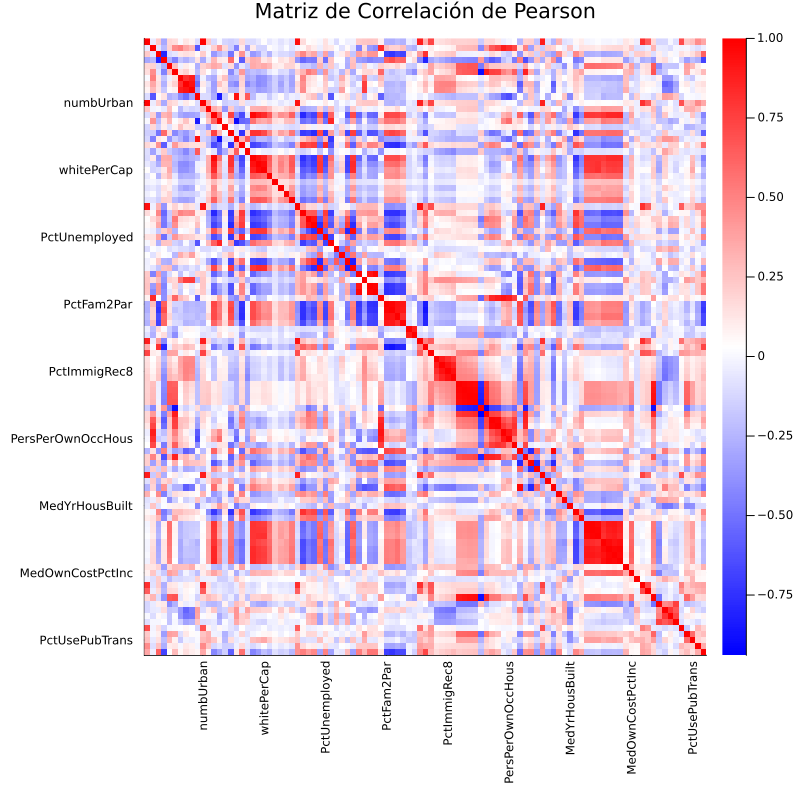

In [20]:
df_limpio, matriz_corr, nombres = reduce_features_by_causality(df, :ViolentCrimesPerPop, umbral=0.8)

heatmap(
    nombres, String.(nombres), matriz_corr,
    title="Matriz de Correlación de Pearson",
    c=cgrad([:blue, :white, :red]),
    yflip=true,
    xrotation=90,
    size=(800, 800)
)

In [21]:
df_limpio

Row,racePctAsian,agePct12t29,pctUrban,pctWFarmSelf,pctWInvInc,pctWPubAsst,pctWRetire,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,PctPopUnderPov,PctNotHSGrad,PctEmploy,PctEmplManu,PctEmplProfServ,MalePctNevMarr,FemalePctDiv,PctKids2Par,PctWorkMom,NumIlleg,NumImmig,PctImmigRec10,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,PctHousOccup,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctWOFullPlumb,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumStreet,PctBornSameState,PctSameHouse85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,ViolentCrimesPerPop
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.12,0.47,1.0,0.34,0.6,0.15,0.43,0.32,0.27,0.27,0.36,0.41,0.19,0.18,0.68,0.23,0.41,0.4,0.75,0.59,0.76,0.04,0.03,0.39,0.55,0.09,0.51,0.5,0.71,0.05,0.26,0.65,0.06,0.38,0.46,0.25,0.0,0.42,0.5,0.64,0.12,0.26,0.2,0.32,0.2
2,0.45,0.59,1.0,0.11,0.45,0.29,0.39,0.33,0.16,0.3,0.22,0.35,0.24,0.24,0.73,0.57,0.15,0.63,0.91,0.47,0.53,0.0,0.01,0.63,0.26,0.2,0.82,0.0,0.79,0.02,0.25,0.65,0.0,0.29,0.32,0.18,0.0,0.5,0.34,0.52,0.02,0.12,0.45,0.0,0.67
3,0.17,0.47,0.0,0.19,0.39,0.4,0.84,0.27,0.07,0.29,0.28,0.39,0.27,0.43,0.58,0.32,0.29,0.41,0.71,0.44,0.67,0.01,0.0,0.19,0.42,0.15,0.51,0.5,0.86,0.29,0.3,0.52,0.45,0.48,0.39,0.28,0.0,0.49,0.54,0.56,0.01,0.21,0.02,0.0,0.43
4,0.12,0.5,1.0,0.21,0.43,0.2,0.82,0.39,0.16,0.25,0.36,0.44,0.1,0.25,0.71,0.36,0.45,0.45,0.49,0.54,0.86,0.03,0.02,0.31,0.94,0.12,0.01,0.5,0.97,0.6,0.47,0.52,0.11,0.63,0.51,0.47,0.0,0.3,0.73,0.65,0.02,0.39,0.28,0.0,0.12
5,0.09,0.38,0.9,0.16,0.68,0.11,0.71,0.28,0.0,0.74,0.51,0.48,0.06,0.3,0.65,0.67,0.38,0.27,0.2,0.91,0.6,0.0,0.0,0.27,0.89,0.02,0.19,0.5,0.89,0.04,0.55,0.73,0.14,0.22,0.51,0.21,0.0,0.72,0.64,0.53,0.04,0.09,0.02,0.0,0.03
6,1.0,0.48,1.0,0.2,0.61,0.15,0.25,0.77,0.28,0.52,0.48,0.6,0.12,0.12,0.65,0.19,0.77,0.57,0.61,0.69,0.43,0.0,0.04,0.47,0.39,0.26,0.73,0.0,0.84,0.16,0.28,0.25,0.05,0.47,0.59,0.11,0.0,0.42,0.49,0.64,0.01,0.58,0.1,0.0,0.14
7,0.06,0.37,0.81,0.23,0.68,0.21,0.54,0.4,0.24,0.86,0.24,0.36,0.11,0.41,0.54,0.44,0.53,0.34,0.28,0.81,0.62,0.0,0.01,0.1,0.65,0.03,0.46,0.5,0.89,0.09,0.49,0.38,0.05,0.46,0.44,0.31,0.0,0.81,0.77,0.84,0.05,0.08,0.06,0.0,0.03
8,0.2,0.55,0.0,1.0,0.23,0.97,0.41,0.08,0.17,0.27,0.18,0.21,0.64,0.82,0.26,0.43,0.34,0.47,0.59,0.43,0.27,0.02,0.02,0.59,0.39,0.89,0.66,0.0,0.91,0.22,0.37,0.6,0.23,0.64,0.59,0.28,0.0,0.58,0.52,0.78,0.01,0.33,0.0,0.0,0.55
9,0.02,0.45,1.0,0.36,0.34,0.48,0.43,0.19,0.1,0.26,0.29,0.22,0.45,0.59,0.43,0.59,0.36,0.26,0.66,0.55,0.64,0.02,0.0,0.13,0.5,0.1,0.64,0.0,0.72,0.05,0.49,0.5,0.22,0.38,0.13,0.36,0.0,0.78,0.48,0.75,0.04,0.17,0.04,0.0,0.53


## Data Preparation & Dimension Reduction

These finalize the cleaning of the data. From now on we will prepare the data to be passed to training models, then we will divide the data, and try to reduce its dimensionallity. 

First lets prepare the data to be ready for training ML models.

In [22]:
using .Sampling
data = Matrix(df)
data_without_near0 = Matrix(df_without_near0)
data_corr = Matrix(df_limpio)
train_idx, test_idx = Sampling.holdOut(size(data, 1), 0.2)

train_input = data[train_idx, 1:end-1]
train_output = data[train_idx,end]
test_input = data[test_idx, 1:end-1]
test_output = data[test_idx, end]

train_corr = data_corr[train_idx, 1:end-1]
test_corr = data_corr[test_idx, 1:end-1]

399×44 Matrix{Float64}:
 0.05  0.47  1.0   0.29  0.58  0.09  …  0.5   0.63  0.03  0.2   0.09  0.0
 0.11  0.39  1.0   0.27  0.84  0.09     0.84  0.79  0.03  0.42  0.5   0.0
 0.03  0.49  0.0   0.47  0.35  0.45     0.51  0.52  0.05  0.13  0.01  0.0
 0.22  0.51  1.0   0.1   0.31  0.57     0.15  0.56  0.12  0.08  0.01  0.0
 0.2   0.41  1.0   0.12  0.54  0.34     0.27  0.65  0.09  0.12  0.05  0.0
 0.1   0.46  0.99  0.74  0.52  0.08  …  0.48  0.79  0.07  0.07  0.02  0.0
 0.04  0.49  0.0   0.15  0.61  0.17     0.41  0.53  0.19  0.05  0.05  0.0
 0.04  0.46  0.0   0.4   0.38  0.27     0.46  0.72  0.02  0.13  0.0   0.0
 0.05  0.28  1.0   0.14  0.57  0.16     0.5   0.4   0.04  0.39  0.03  0.0
 1.0   0.49  1.0   0.2   0.58  0.14     0.35  0.65  0.04  0.3   0.05  0.0
 0.09  0.68  0.0   0.1   0.34  0.32  …  0.32  0.53  0.03  0.17  0.06  0.0
 0.26  1.0   0.0   0.29  0.66  0.04     0.28  0.14  0.02  0.13  0.0   0.0
 0.08  0.66  1.0   0.0   0.18  0.91     0.63  0.82  0.02  0.15  0.35  0.0
 ⋮            

In [23]:
using Optimisers
using Flux

ann_hyperparameters = Dict(
    :topology => (64, 32),
    :transferFunctions => Flux.relu,
    :epochs => 1000,
    :optimiser => Optimisers.Adam(0.01),
    :batch_size => 32,
    :finaliser => identity, # identity is correct because your original buildClassANN handles the final activation (softmax or σ)
    :loss => Flux.mse   
)

model = createModel(:ANN, ann_hyperparameters)


NeuralNetworkClassifier(
  builder = MLP(
        hidden = (64, 32), 
        σ = NNlib.relu), 
  finaliser = identity, 
  optimiser = Adam(0.01, (0.9, 0.999), 1.0e-8), 
  loss = Flux.Losses.mse, 
  epochs = 1000, 
  batch_size = 32, 
  lambda = 0.0, 
  alpha = 0.0, 
  rng = TaskLocalRNG(), 
  optimiser_changes_trigger_retraining = false, 
  acceleration = CPU1{Nothing}(nothing), 
  embedding_dims = Dict{Symbol, Real}())

In [24]:
mach = machine(model, MLJ.table(train_input), categorical(train_output))

untrained Machine; caches model-specific representations of data
  model: NeuralNetworkClassifier(builder = MLP(hidden = (64, 32), …), …)
  args: 
    1:	Source @466 ⏎ Table{AbstractVector{Continuous}}
    2:	Source @290 ⏎ AbstractVector{Multiclass{97}}


Now we will focus on two dimensionallity reduction techniques, PCA and ICA. We discarded LDA because it is a technique that depends on classes and here we are dealing with a regression problem.

First we go with PCA, we will be creating to models and so to datasets one with selecting a total variance of 95% and the other with a total variance of 99%.

In [25]:
# PCA keeping 95% of the total variance
pca_model = PCA(variance_ratio=0.95)

# Train the PCA model
pca_mach = machine(pca_model, MLJ.table(train_input))
MLJ.fit!(pca_mach)

# Transform the data
pca_train = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(train_input)))
pca_test = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(test_input)))

print("Train Patterns ", size(train_input), " -> ", size(pca_train), "\n")
print("Test Patterns ", size(test_input), " -> ", size(pca_test), "\n")

[ Info: Training machine(PCA(maxoutdim = 0, …), …).


Train Patterns (1595, 100) -> (1595, 32)
Test Patterns (399, 100) -> (399, 32)


In [26]:
# PCA keeping 99% of the total variance
pca_model_99 = PCA(variance_ratio=0.99)

# Train the PCA model
pca_mach_99 = machine(pca_model_99, MLJ.table(train_input))
MLJ.fit!(pca_mach_99)

# Transform the data
pca_train_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(train_input)))
pca_test_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(test_input)))

print("Train Patterns ", size(train_input), " -> ", size(pca_train_99), "\n")
print("Test Patterns ", size(test_input), " -> ", size(pca_test_99), "\n")

[ Info: Training machine(PCA(maxoutdim = 0, …), …).


Train Patterns (1595, 100) -> (1595, 57)
Test Patterns (399, 100) -> (399, 57)


As we can see mantaining 99% of the variance we have already deleted halve of the variables, menaing that they doesn't add any information, only 1% of variance spread in more than 40 variables.

After multiple tries we show next that ICA only finish reducing the model with output dimensions = 2 for this dataset, what is useles because is sure that a lot of information will be lost.

In [27]:
# for seed in 1:100
#     Random.seed!(seed);

#     try
#         ica_model = ICA(outdim=10, tol=0.1)
#         ica_mach = machine(ica_model, MLJ.table(train_input))
#         fit!(ica_mach)

#         ica_train = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(train_input)))
#         ica_test = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(test_input)))

#         println("Train Patterns ", size(train_input), " -> ", size(ica_train))
#         println("Test Patterns ", size(test_input), " -> ", size(ica_test))
#         print("Seed: ", seed)
#         break
#     catch e
#         println("An error occurred with seed $seed: $e")
#     end
# end
# Is left commented as it prints lot of trash.

In [28]:
ica_model = ICA(outdim=2, tol=0.3)
ica_mach = machine(ica_model, MLJ.table(train_input))
MLJ.fit!(ica_mach)

ica_train = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(train_input)))
ica_test = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(test_input)))

println("Train Patterns ", size(train_input), " -> ", size(ica_train), "\n")
println("Test Patterns ", size(test_input), " -> ", size(ica_test), "\n")


[ Info: Training machine(ICA(outdim = 2, …), …).


Train Patterns (1595, 100) -> (1595, 2)

Test Patterns (399, 100) -> (399, 2)



Now let's make a quick look into the dependant variable to see it's distribution. 

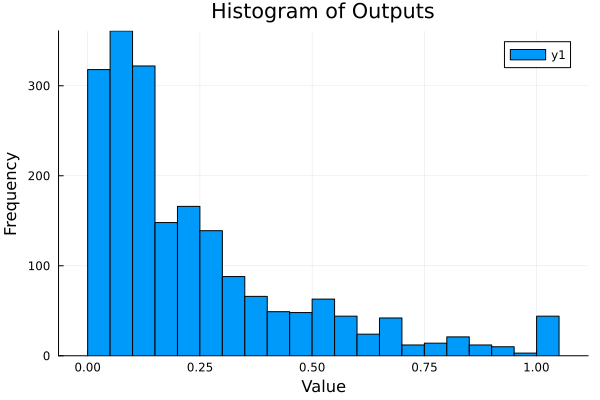

In [29]:
outputs = data[:, end]
histogram(outputs, 
    title="Histogram of Outputs",
    xlabel="Value",
    ylabel="Frequency"
)


In [30]:
using .Sampling
using .Preprocessing
using .Training
using .Output
using .Ensembles

In [31]:
# edges = [0.15, 0.4, 0.70, 1.0, 6.0]
# binned_vector = bin_to_multiclass(outputs, edges)
# # Stratified binarization logaritmic
# println("Original Data: ", outputs)
# println("Bin Edges: ", edges)
# println("Binned Vector (Bin Indices): ", binned_vector)

using Statistics

# using quantile, we obtain an equal distribution of samples per bin
raw_target = data[:, end]
edges = quantile(raw_target, range(0, 1, length=5))
edges[end] += 0.0001
println("Bin Edges: ", edges)

binned_vector = Preprocessing.bin_to_multiclass(raw_target, edges)

counts = [count(x -> x == i, binned_vector) for i in 1:4]
println("Distribution of classes: ", counts)

Bin Edges: [0.0, 0.07, 0.15, 0.33, 1.0001]
Distribution of classes: [484, 468, 537, 505]


In [32]:
train_output_binned = binned_vector[train_idx,end]
test_output_binned = binned_vector[test_idx, end]

399-element Vector{Int64}:
 3
 1
 4
 4
 3
 1
 1
 2
 3
 3
 4
 3
 4
 ⋮
 1
 1
 4
 4
 1
 1
 2
 2
 1
 1
 1
 3

Como resultado del procesamiento de los datos se ofrecen:

- Como datos de entrada: 
    - Sin reducir: train_input, val_input, test_input
    - Con PCA (0.95 of total variance, 33 features): pca_train, pca_val, pca_test
    - Con PCA (0.99 of total variance, 58 features): pca_train_99, pca_val_99, pca_test_99
- Como datos de salida:
    - Regression: train_output, val_output, test_output
    - Classification (applying bining): train_output_binned, val_output_binned, test_output_binned

Here we do a training based on k-fold cross validation, checking different configurations of the classification models used in class.

The idea is to check what of those configurations present the best accuracy and standard deviation for further use afterwards

In [ ]:
using Printf

"""
    ExperimentSuite

Estructura mutable que encapsula todo el estado de un experimento de Machine Learning.
Mantiene los datos, la configuración y los resultados de los modelos entrenados.

# Models Config Update
Para usar con `Training.modelCrossValidation`, `models_config` debe ser un diccionario:
`"Nombre" => (:SimboloModelo, [ListaDeDiccionariosDeParametros])`
Ejemplo:
`"ANN" => (:ANN, [Dict(:topology => [8], ...), ...])`
"""
mutable struct ExperimentSuite
    X                               # Features
    y                               # Target (ya procesado)
    x_test
    y_test
    task_type::Symbol               # :regression o :classification
    split_strategy::ResamplingStrategy # Estrategia de validación (Holdout, CV, etc.)
    models_config::Dict             # Diccionario de Modelos y sus Rangos
    results::Dict                   # Almacenará los reportes y métricas
    best_machines::Dict             # Almacenará las máquinas entrenadas (objetos fit)
    
    """
    Constructor del ExperimentSuite.
    Recibe los datos de entrada (X) y salida (y) directamente como matrices o vectores.
    Realiza el preprocesamiento automático del target (binning) si es clasificación.
    """
    function ExperimentSuite(X_raw, y_raw, X_test_raw, y_test_raw, task_type::Symbol; 
                             n_classes::Int=0, split_strategy=Holdout(fraction_train=0.7), models_config=Dict())
        

        # 1. Preprocesamiento del Target según la tarea
        if task_type == :classification
            if n_classes > 0
                # Discretización basada en cuantiles para convertir regresión continua en clasificación
                println("Transformando target continuo a $n_classes clases usando cuantiles...")
                # Usamos una lógica simple de cuantiles manuales para asegurar compatibilidad
                q_vals = quantile(y_raw, range(0, 1, length=n_classes+1))
                # Ajuste pequeño para incluir extremos
                q_vals[1] -= 1e-5
                q_vals[end] += 1e-5
                
                # Función para binning
                function get_class(val, quantiles)
                    for i in 1:(length(quantiles)-1)
                        if val > quantiles[i] && val <= quantiles[i+1]
                            return i
                        end
                    end
                    return length(quantiles)-1 # Fallback
                end
                
                y_binned = [get_class(v, q_vals) for v in y_raw]
                y_test_binned = [get_class(v, q_vals) for v in y_test_raw]
                y_test = coerce(y_test_binned, OrderedFactor)
                y = coerce(y_binned, OrderedFactor)
            else
                y = coerce(y_raw, Multiclass)
                y_test = coerce(y_test_raw, Multiclass)
            end
        else
            # Regresión
            y = coerce(y_raw, Continuous)
            y_test = coerce(y_test_raw, Continuous)
        end

        # Coerce de Features (heurística simple, se puede mejorar con scitype explícito)
        # Importante: Usamos Continuous para evitar problemas con KNN/SVM y categorías inferidas
        X = coerce(X_raw, Continuous)
        X_test = coerce(X_test_raw, Continuous)
    

        new(X, y, X_test, y_test, task_type, split_strategy, models_config, Dict(), Dict())
    end
end

"""
    run_experiments!(suite::ExperimentSuite)

Ejecuta los experimentos utilizando `Training.modelCrossValidation` y `Sampling.crossvalidation`.
Itera sobre las configuraciones definidas en `suite.models_config`.
"""
function run_experiments!(suite::ExperimentSuite; measure=nothing)
    println("\n🚀 Iniciando ejecución de experimentos para tarea: $(suite.task_type)")
    println("==================================================================================================")
    println("Model           | Configuration                        | Result (CV Mean ± SD)")
    println("--------------------------------------------------------------------------------------------------")
    
    # 1. Preparar Dataset Tuple para Training module (Matriz Float32, Vector)
    dataset_tuple = (suite.X, suite.y)

    # 2. Generar Índices de CrossValidation usando Sampling
    k_folds = 10
    if suite.split_strategy isa CV
        k_folds = suite.split_strategy.nfolds
    end
    
    cv_indices = Sampling.crossvalidation(suite.y, k_folds)

    # 3. Iterar sobre Modelos y Configuraciones
    for (model_name, (model_symbol, param_configs)) in suite.models_config
        # model_symbol: Símbolo esperado por Training (ej. :ANN, :SVC)
        # param_configs: Vector de diccionarios con los parámetros a probar
        
        best_acc = -1.0
        best_result_obj = nothing
        
        for params in param_configs
            try
                # Llamada al módulo Training original
                # modelCrossValidation retorna (results, mach) o similar
                res_obj = Training.modelCrossValidation(model_symbol, params, dataset_tuple, cv_indices)
                
                # Extraemos 'results' si es una tupla (results, mach)
                results = isa(res_obj, Tuple) ? res_obj[1] : res_obj
                
                # Obtener métricas para logging (Accuracy o Error)
                acc_mean = 0.0
                acc_std = 0.0
                
                # Detectar métrica disponible
                if hasproperty(results, :accuracy)
                    acc_mean = results.accuracy[1]
                    acc_std = results.accuracy[2]
                elseif hasproperty(results, :rms)
                     acc_mean = results.rms[1] # Placeholder si fuera regresión
                end
                
                # Formatear configuración para display
                config_str = string(params)
                if length(config_str) > 35
                    config_str = config_str[1:32] * "..."
                end
                
                # Log en consola estilo tabla
                @printf("%-15s | %-35s | Acc: %.2f%% ± %.2f%%\n", 
                        model_name, config_str, acc_mean * 100, acc_std * 100)
                
                # Guardar el mejor resultado localmente
                if acc_mean > best_acc
                    best_acc = acc_mean
                    best_result_obj = (res_obj,model_symbol, params)
                end
                
            catch e
                println("❌ Error en $model_name con params $params: $e")
                # Base.show_backtrace(stdout, catch_backtrace())
            end
        end
        
        # 4. Almacenar el mejor resultado en la Suite
        if best_result_obj !== nothing
            # Desempaquetar si es tupla (results, mach)
            final_res = best_result_obj[1]
            if best_result_obj[2] == :ANN
                params = deepcopy(best_result_obj[3])
                classes = sort(unique(suite.y))
                num_classes = length(classes)

                # OneHotEncoding
                one_hot_targets = oneHotEncoding(suite.y, classes)
                pop!(params, :validationRatio)
                ann, _, _, _ = trainClassANN(
                    pop!(params, :topology),
                    (suite.X, one_hot_targets);
                    params...
                )
                final_mach = ann
            else
                final_model = Training.createModel(best_result_obj[2], best_result_obj[3])
                final_mach = machine(final_model, MLJ.table(suite.X), categorical(suite.y))
                MLJ.fit!(final_mach, rows=1:size(suite.X, 1), verbosity=0)
            end
            

            
            suite.results[model_name] = (
                metric_score = best_acc,
                report = final_res,
                model_type = best_result_obj[2],
                history = nothing # No disponible en legacy mode
            )
            
            if final_mach !== nothing

                suite.best_machines[model_name] = final_mach
            end
        end
    end
    println("--------------------------------------------------------------------------------------------------")
end

"""
    visualize_results(suite::ExperimentSuite; type=:bar, model_name=nothing)

Realiza predicciones sobre el conjunto de TEST (`suite.x_test`) usando los modelos entrenados
y genera visualizaciones según el tipo solicitado.

Tipos soportados (`type`):
- `:bar`: Gráfico de barras comparando el rendimiento (Accuracy o RMSE) de todos los modelos en Test.
- `:heatmap`: Matriz de confusión en Test (requiere `model_name` y `task_type=:classification`).
- `:scatter`: Gráfico de Predicción vs Real en Test (requiere `model_name` y `task_type=:regression`).
"""
function visualize_results(suite::ExperimentSuite; type=:bar, model_name=nothing)
    
    X_test_table = MLJ.table(suite.x_test)
    y_test = suite.y_test

    # -----------------------------------------------------------
    # 1. BAR CHART
    # -----------------------------------------------------------
    if type == :bar
        println("📊 Generando comparativa de rendimiento en Test Set...")
        
        model_names = collect(keys(suite.best_machines))
        scores = Float64[]
        
        for name in model_names
            mach = suite.best_machines[name]
            model_type = suite.results[name].model_type
            if suite.task_type == :classification
                if model_type == :ANN
                    y_hat = mach(suite.x_test')
                    classes = sort(unique(y_test))
                    num_classes = length(classes)
                    one_hot_targets = oneHotEncoding(y_test, classes)
                    y_hat = classifyOutputs(y_hat')
                    # println(y_hat)
                    # println(one_hot_targets)
                    acc = Training.accuracy(y_hat, one_hot_targets)
                elseif model_type == :SVC
                    y_hat = MLJ.predict(mach, X_test_table)
                    acc = MLJ.accuracy(y_hat, y_test)
                else
                    y_hat = MLJ.predict_mode(mach, X_test_table)
                    acc = MLJ.accuracy(y_hat, y_test)
                end
                println(name, acc)
                push!(scores, acc)
            else
                y_hat = MLJ.predict(mach, X_test_table)
                err = MLJ.rmse(y_hat, y_test)
                println(name, err)
                push!(scores, err)
            end
        end
        
        perm = sortperm(scores)
        model_names = model_names[perm]
        scores = scores[perm]
        
        title_str = suite.task_type == :regression ? "Test RMSE (Menor es mejor)" : "Test Accuracy (Mayor es mejor)"
        y_lims = (0, maximum(scores)) : suite.task_type == :regression : (0.3, maximum(scores)
        p = bar(model_names, scores, 
            orientation=:v, title=title_str, legend=false, color=:tab10,
            xrotation=45, ylabel="Score en Test", fmt=:png, ylims=y_lims)
        )
        display(p)

    # -----------------------------------------------------------
    # 2. HEATMAP (Cálculo Manual)
    # -----------------------------------------------------------
    elseif type == :heatmap
        if suite.task_type != :classification
            println("⚠️ El heatmap es solo para clasificación.")
            return
        end
        if isnothing(model_name)
            error("Debes especificar 'model_name'.")
        end
        
        mach = suite.best_machines[model_name]
        model_type = suite.results[model_name].model_type
        # println(model_name, model_type)
        # 1. Obtener predicciones y reales
        
        if model_type == :ANN
            outputs = mach(suite.x_test')
            outputs = classifyOutputs(outputs')
            outputs = [argmax(row) for row in eachrow(outputs)]
        elseif model_type == :SVC
            outputs = MLJ.predict(mach, X_test_table)
        else
            outputs = MLJ.predict_mode(mach, X_test_table) # Predicciones
        end
        targets = y_test                           # Reales
        
        # 2. Obtener clases (usamos levels de MLJ para asegurar el dominio completo)
        classes = MLJ.levels(targets)

        # 3. Lógica manual de ordenamiento (tu código)
        sorted_classes = try
            sort(classes, by = x -> parse(Float64, string(x)))
        catch
            sort(classes)
        end

        # 4. Construcción manual de la matriz (tu código)
        n = length(sorted_classes)
        class_map = Dict(c => i for (i, c) in enumerate(sorted_classes))
        matrix = zeros(Int, n, n)

        for (pred, real) in zip(outputs, targets)
            if haskey(class_map, pred) && haskey(class_map, real)
                r = class_map[real] # Fila: Real
                c = class_map[pred] # Columna: Predicho
                matrix[r, c] += 1
            end
        end

        # 5. Visualización
        labels_str = string.(sorted_classes)
        max_val = maximum(matrix)
        
        # Generar anotaciones con contraste de color
        anns = []
        for i in 1:n, j in 1:n
            val = matrix[i, j]
            # Texto blanco sobre fondo oscuro, negro sobre claro
            text_col = (val < max_val / 2) ? :white : :black
            push!(anns, (j, i, text(string(val), 10, text_col, :center, :center)))
        end

        p = heatmap(
            matrix,
            title="Matriz de Confusión: $model_name",
            xlabel="Predicho", 
            ylabel="Real",
            color = :blues,
            c=:viridis,
            aspect_ratio=:equal,
            xticks=(1:n, labels_str),
            yticks=(1:n, labels_str),
            yflip=true, # Fila 1 arriba
            annotations=anns
        )
        
        display(p)

    # -----------------------------------------------------------
    # 3. SCATTER
    # -----------------------------------------------------------
    elseif type == :scatter
        if suite.task_type != :regression
            println("⚠️ El scatter plot es para regresión.")
            return
        end
        if isnothing(model_name)
            error("Debes especificar 'model_name'.")
        end
        
        mach = suite.best_machines[model_name]
        y_hat = MLJ.predict(mach, X_test_table)
        
        p = scatter(y_hat, y_test,
            title="Predicción vs Real: $model_name",
            xlabel="Predicho", ylabel="Real",
            legend=:topleft, label="Datos", markeralpha=0.6, color=:blue
        )
        plot!(p, y_test, y_test, color=:red, linestyle=:dash, label="Ideal")
        display(p)
        
    else
        println("❌ Tipo desconocido.")
    end
end


visualize_results

🏁 INICIANDO SUITE DE EXPERIMENTOS MODULARIZADA (Backend: Training.jl)

📂 Procesando Dataset: Raw Attributes
Transformando target continuo a 4 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 59.18% ± 3.45%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 57.42% ± 3.48%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 56.66% ± 4.36%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 57.68% ± 3.38%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 52.28% ± 3.19%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 55.42% ± 2.98%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 57.29% ± 3.14%
SVM             | Dict{Symbol, Any}(:degree => 2, ... |

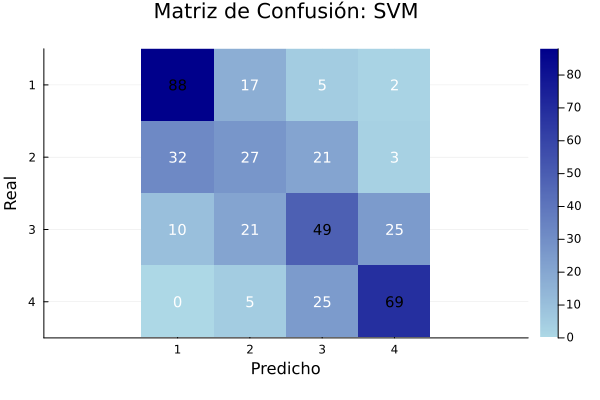

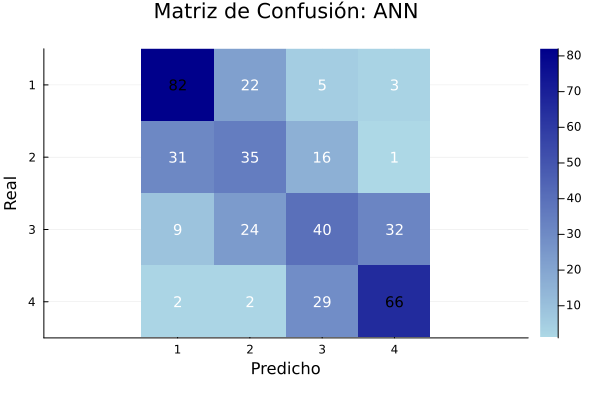

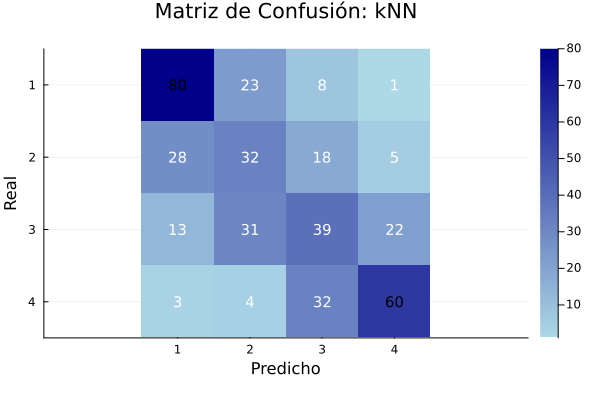

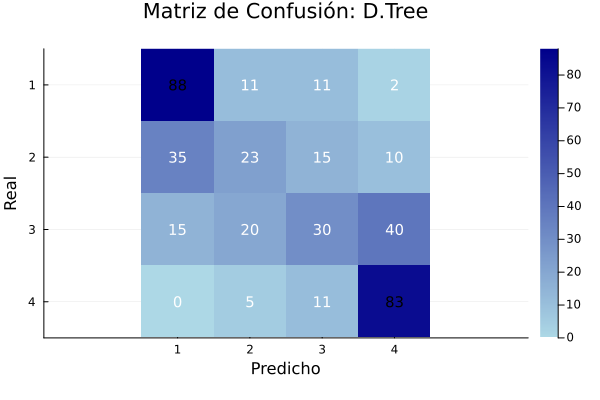


📂 Procesando Dataset: PCA (99% Var)
Transformando target continuo a 4 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 57.42% ± 3.78%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 57.10% ± 3.60%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 57.42% ± 3.01%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 56.92% ± 3.97%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 41.36% ± 3.17%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 53.72% ± 4.29%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 58.61% ± 3.71%
SVM             | Dict{Symbol, Any}(:degree => 2, ... | Acc: 50.66% ± 1.89%
ANN             | Dict{Symbol, Any}(:maxEpochs => 

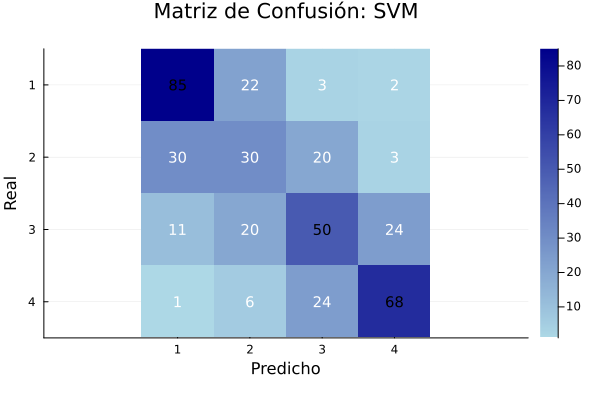

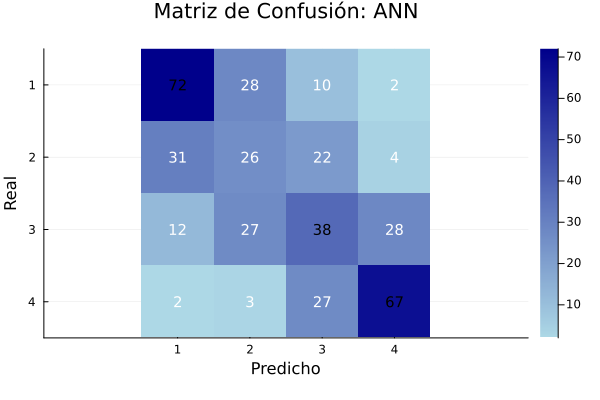

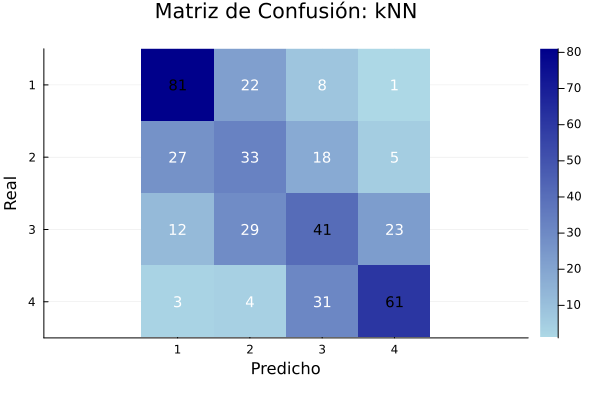

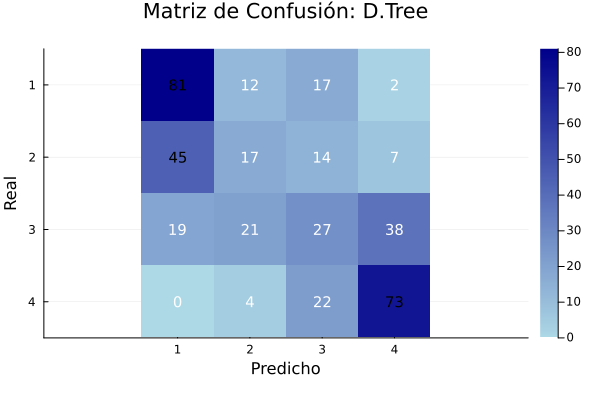


📂 Procesando Dataset: ICA (2 Comp)
Transformando target continuo a 4 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 51.28% ± 2.69%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 51.66% ± 3.29%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 51.53% ± 3.46%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 51.53% ± 2.91%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 52.78% ± 3.14%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 52.97% ± 4.00%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 51.97% ± 3.15%
SVM             | Dict{Symbol, Any}(:degree => 2, ... | Acc: 37.05% ± 1.37%
ANN             | Dict{Symbol, Any}(:maxEpochs => .

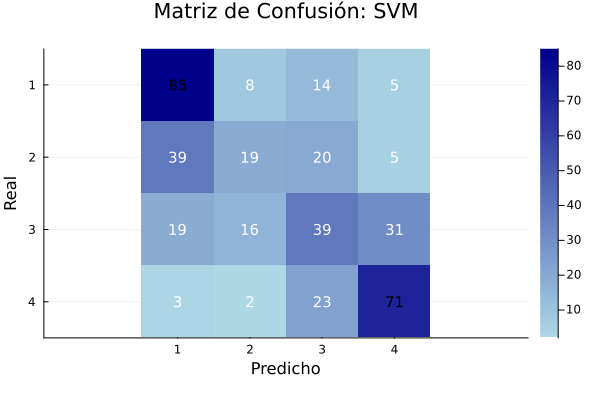

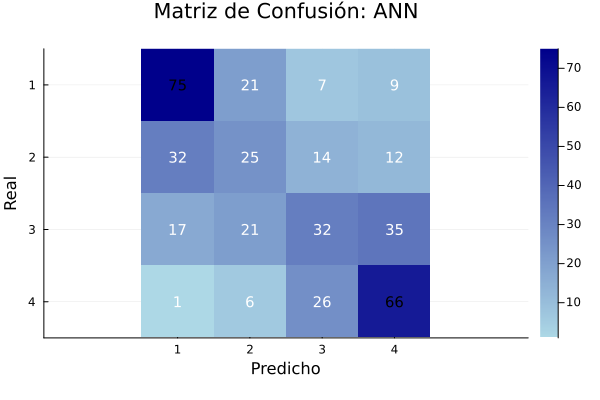

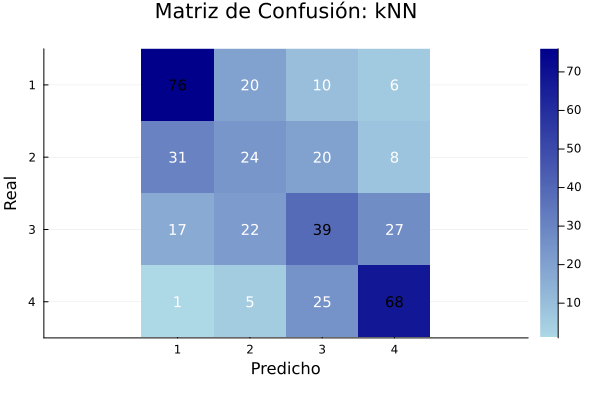

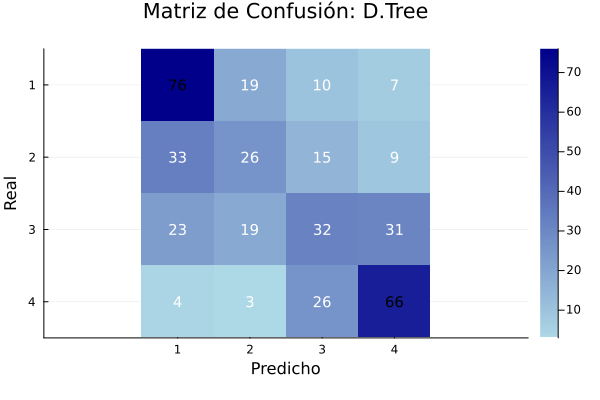


📂 Procesando Dataset: Filtered by Correlation
Transformando target continuo a 4 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 59.50% ± 3.74%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 58.43% ± 4.32%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 58.11% ± 4.30%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 58.74% ± 5.09%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 54.29% ± 4.51%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 56.30% ± 4.36%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 58.05% ± 5.29%
SVM             | Dict{Symbol, Any}(:degree => 2, ... | Acc: 52.99% ± 5.30%
ANN             | Dict{Symbol, Any}(:max

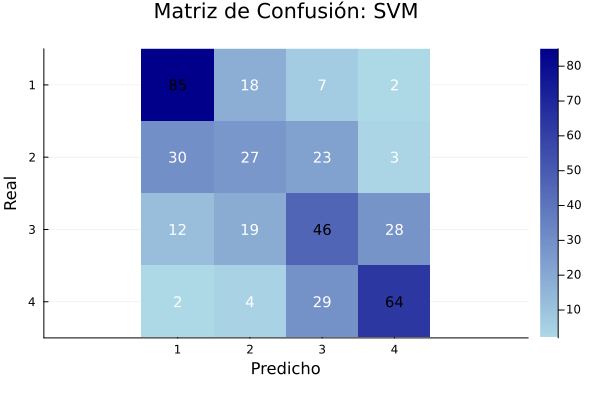

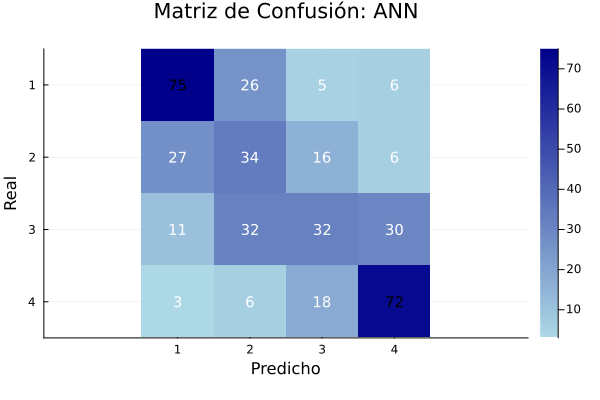

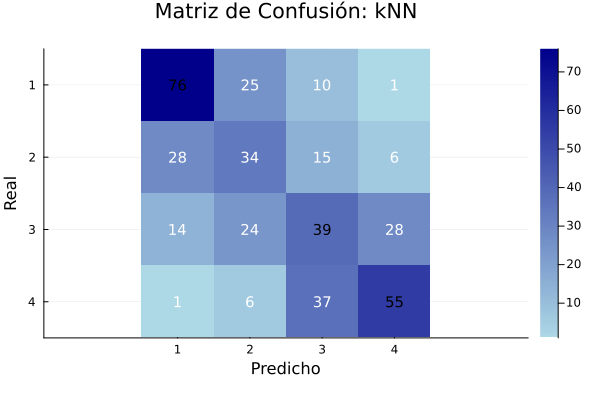

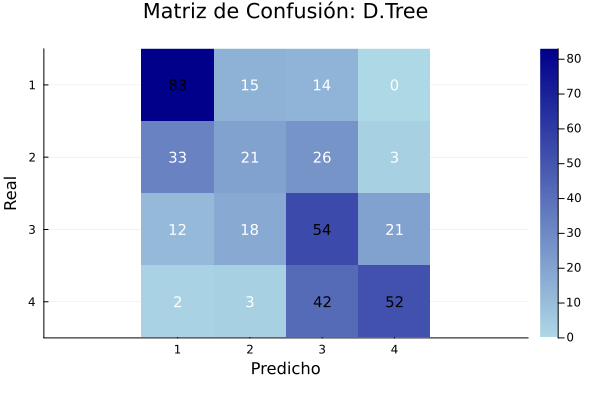


📂 Procesando Dataset: PCA (95% Var)
Transformando target continuo a 4 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 58.38% ± 4.04%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 59.57% ± 4.25%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 59.76% ± 4.18%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 58.24% ± 3.45%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 54.43% ± 3.52%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 56.12% ± 4.00%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 58.88% ± 4.25%
SVM             | Dict{Symbol, Any}(:degree => 2, ... | Acc: 50.04% ± 3.78%
ANN             | Dict{Symbol, Any}(:maxEpochs => 

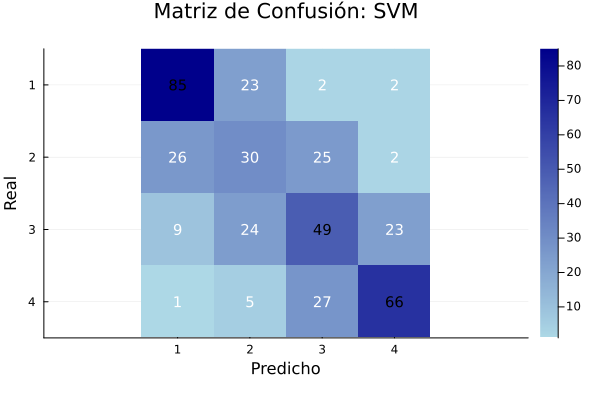

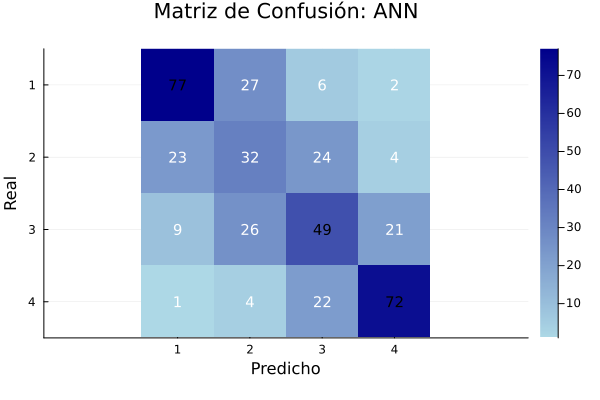

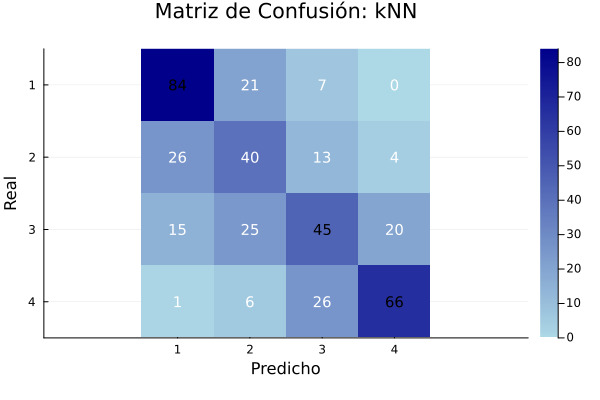

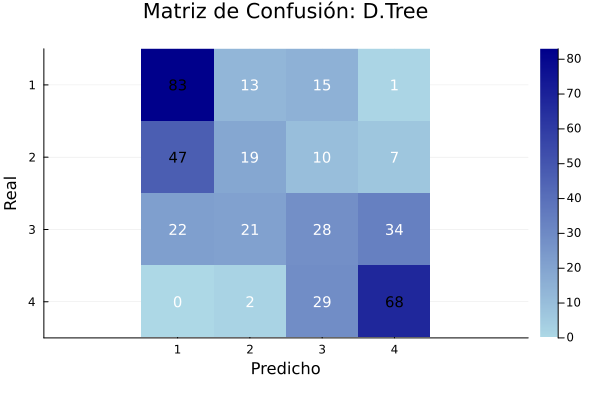

In [34]:
# Asegúrate de tener cargado el módulo MLTools

# using Flux # Necesario para la configuración de ANN (relu)

# ==========================================
# 1. DEFINICIÓN DE LA CONFIGURACIÓN (MODELS CONFIG)
# ==========================================
# Adaptamos los rangos al formato que espera Training.modelCrossValidation:
# "Nombre" => (:SimboloModelo, [Lista de Diccionarios de Parámetros])

# --- k-Nearest Neighbors ---
# K = 1, 3, 5, 7, 11, 21
knn_configs = [Dict(:K => k) for k in [1, 3, 5, 7, 11, 21]]

# --- Decision Tree ---
# Depths = 3, 5, 7, 9, 15, 20
dt_configs = [Dict(:max_depth => d) for d in [3, 5, 7, 9, 15, 20]]

# --- SVM ---
svm_configs = [
    Dict(:kernel => "LINEAR", :C => 0.1),
    Dict(:kernel => "LINEAR", :C => 1.0),
    Dict(:kernel => "LINEAR", :C => 10.0),

    Dict(:kernel => "RBF", :C => 1.0, :gamma => 0.01),
    Dict(:kernel => "RBF", :C => 1.0, :gamma => 0.1),
    Dict(:kernel => "RBF", :C => 10.0, :gamma => 0.01),
    Dict(:kernel => "RBF", :C => 100.0, :gamma => 0.001),

    Dict(:kernel => "POLY", :C => 1.0, :degree => Int32(2)) 
]



# --- Artificial Neural Networks (ANN) ---
# Topologías variadas

ann_topologies = [[8,], [16,], [32,], [64,], [8, 8], [16, 16], [32, 32], [64, 64]]
# ann_topologies = [[8,]]
ann_configs = [
    Dict(
        :topology => topo,
        :transferFunctions => fill(Flux.relu, length(topo)),
        :maxEpochs => 500,  
        :learningRate => 0.01,
        :showText => false,
        :validationRatio => 0.1,
        :maxEpochsVal => 10
    ) for topo in ann_topologies
]

# DICCIONARIO MAESTRO
# Mapea Nombre -> (Simbolo para Training.jl, Lista de Configs)
my_models = Dict(
    "kNN"        => (:KNeighborsClassifier, knn_configs),
    "D.Tree"     => (:DecisionTreeClassifier, dt_configs),
    "SVM"        => (:SVC, svm_configs),
    "ANN"        => (:ANN, ann_configs)
)

# ==========================================
# 2. DATOS DE ENTRADA
# ==========================================
# Asumo que 'train_input', 'train_corr', etc. están en tu workspace
experiment_inputs = Dict(
    "Raw Attributes"          => Float32.(train_input),
    "Filtered by Correlation" => Float32.(train_corr), 
    "PCA (95% Var)"           => Float32.(pca_train),
    "PCA (99% Var)"           => Float32.(pca_train_99),
    "ICA (2 Comp)"            => Float32.(ica_train)
)
experiment_tests = Dict(
    "Raw Attributes"          => Float32.(test_input),
    "Filtered by Correlation" => Float32.(test_corr), 
    "PCA (95% Var)"           => Float32.(pca_test),
    "PCA (99% Var)"           => Float32.(pca_test_99),
    "ICA (2 Comp)"            => Float32.(ica_test)
)
target = train_output # Tu vector de salida

suites_4 = Dict(
)
# ==========================================
# 3. EJECUCIÓN
# ==========================================
println("🏁 INICIANDO SUITE DE EXPERIMENTOS MODULARIZADA (Backend: Training.jl)")

for (dataset_name, X_data) in experiment_inputs
    println("\n=============================================")
    println("📂 Procesando Dataset: $dataset_name")
    
    # A. Instanciar la Suite
    # Nota: Pasamos 'my_models' que ya tiene el formato correcto para Training.jl
    suite = ExperimentSuite(
        X_data, 
        target,
        experiment_tests[dataset_name],
        test_output,
        :classification;
        n_classes = 4, # Cuantiles
        models_config = my_models
    )
    
    # B. Ejecutar Experimentos
    # Esto llamará a Training.modelCrossValidation internamente
    run_experiments!(suite)
    
    suites_4[dataset_name] = suite
    # C. Visualizar Resultados
    println("\n📊 Resumen Gráfico para $dataset_name:")
    for (model_name, model_parameters) in my_models
        visualize_results(suite, type=:heatmap, model_name=model_name)
    end
end


📂 Procesando Dataset: Raw Attributes

📊 Resumen Gráfico para Raw Attributes:
📊 Generando comparativa de rendimiento en Test Set...
SVM0.5839598997493735
ANN0.5588972431077694
kNN0.5288220551378446
D.Tree0.5614035087719298


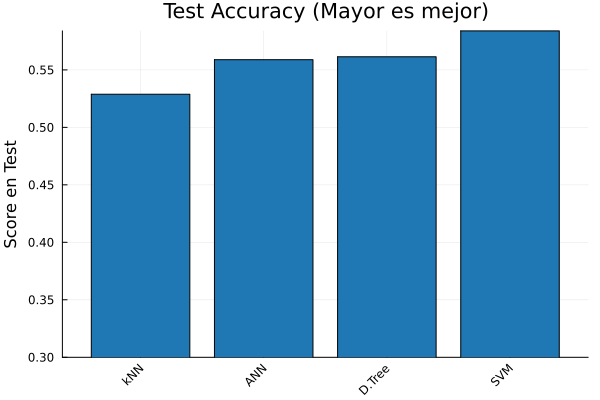


📂 Procesando Dataset: PCA (99% Var)

📊 Resumen Gráfico para PCA (99% Var):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.5839598997493735
ANN0.5087719298245614
kNN0.5413533834586466
D.Tree0.49624060150375937


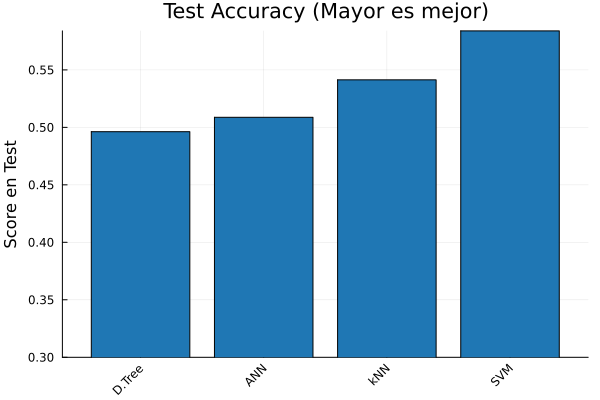


📂 Procesando Dataset: ICA (2 Comp)

📊 Resumen Gráfico para ICA (2 Comp):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.5363408521303258
ANN0.49624060150375937
kNN0.518796992481203
D.Tree0.5012531328320802


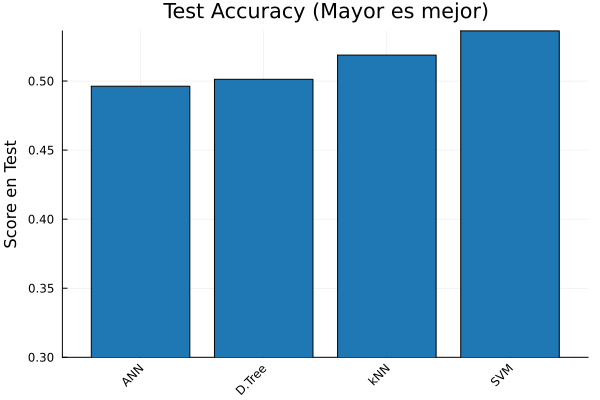


📂 Procesando Dataset: Filtered by Correlation

📊 Resumen Gráfico para Filtered by Correlation:
📊 Generando comparativa de rendimiento en Test Set...
SVM0.556390977443609
ANN0.5338345864661654
kNN0.5112781954887218
D.Tree0.5263157894736842


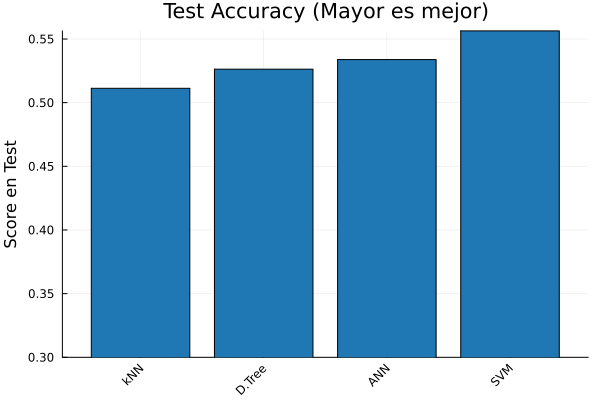


📂 Procesando Dataset: PCA (95% Var)

📊 Resumen Gráfico para PCA (95% Var):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.5764411027568922
ANN0.5764411027568922
kNN0.5889724310776943
D.Tree0.49624060150375937


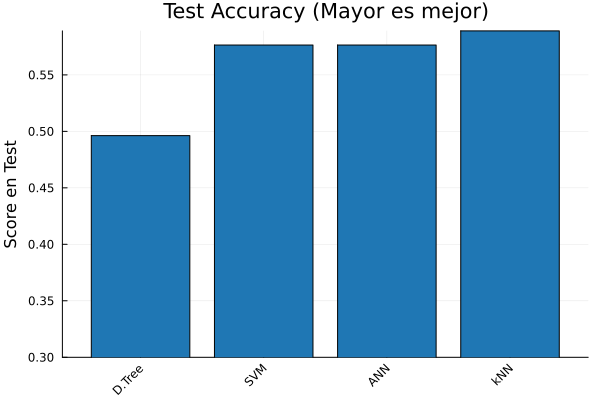

In [36]:
for (dataset_name, X_data) in experiment_inputs
    println("\n=============================================")
    println("📂 Procesando Dataset: $dataset_name")
    
    
    # C. Visualizar Resultados
    println("\n📊 Resumen Gráfico para $dataset_name:")
    visualize_results(suites_4[dataset_name], type=:bar)
end


🏁 INICIANDO SUITE DE EXPERIMENTOS MODULARIZADA (Backend: Training.jl)

📂 Procesando Dataset: Raw Attributes
Transformando target continuo a 3 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 69.26% ± 4.45%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 68.39% ± 3.36%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 68.46% ± 3.43%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 70.52% ± 3.20%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 61.81% ± 4.28%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 66.58% ± 3.55%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 69.09% ± 2.97%
SVM             | Dict{Symbol, Any}(:degree => 2, ... |

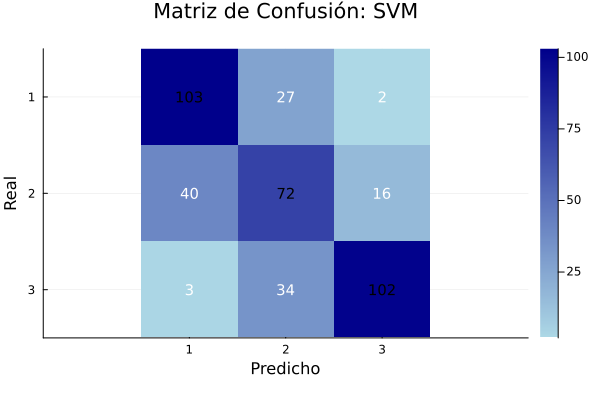

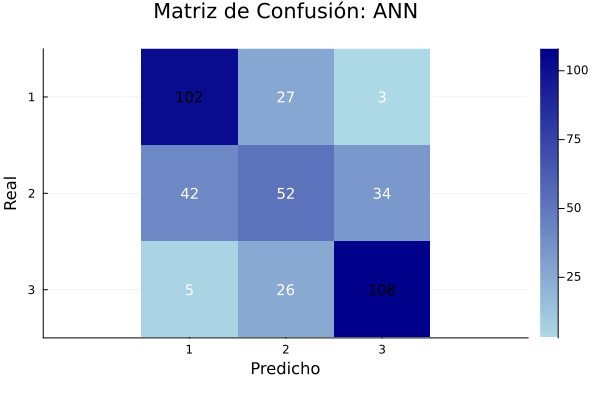

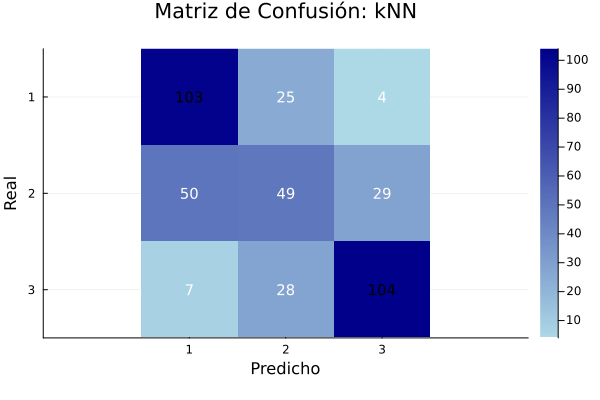

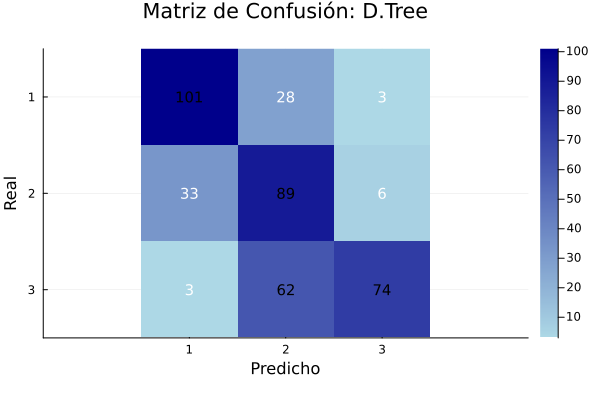


📂 Procesando Dataset: PCA (99% Var)
Transformando target continuo a 3 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 67.52% ± 2.02%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 68.52% ± 2.31%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 67.71% ± 2.44%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 68.64% ± 2.60%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 59.56% ± 2.98%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 65.07% ± 2.11%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 67.95% ± 2.52%
SVM             | Dict{Symbol, Any}(:degree => 2, ... | Acc: 61.06% ± 2.20%
ANN             | Dict{Symbol, Any}(:maxEpochs => 

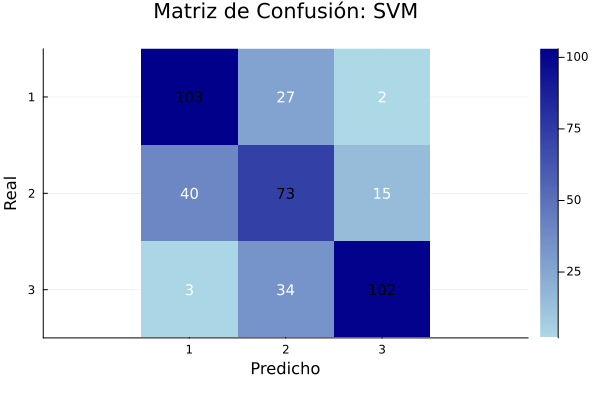

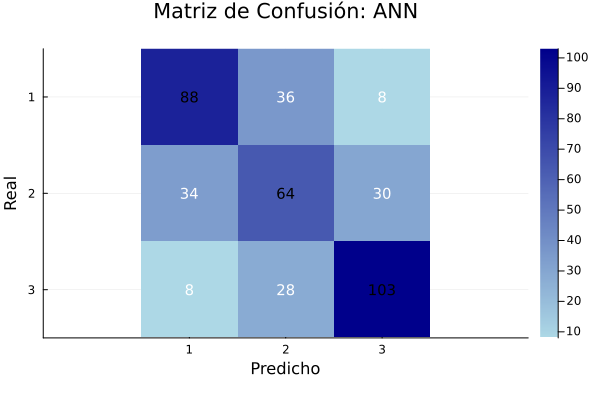

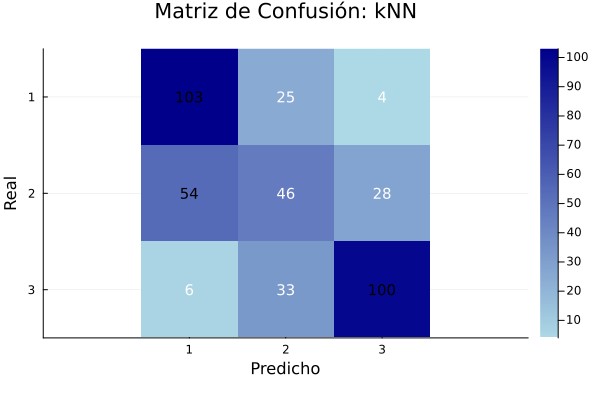

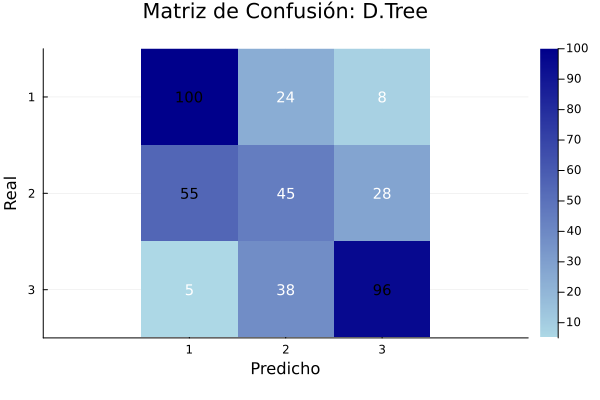


📂 Procesando Dataset: ICA (2 Comp)
Transformando target continuo a 3 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 63.52% ± 4.08%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 63.96% ± 3.78%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 63.90% ± 3.82%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 63.33% ± 3.63%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 63.96% ± 3.65%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 64.08% ± 3.80%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 63.83% ± 3.55%
SVM             | Dict{Symbol, Any}(:degree => 2, ... | Acc: 48.09% ± 2.02%
ANN             | Dict{Symbol, Any}(:maxEpochs => .

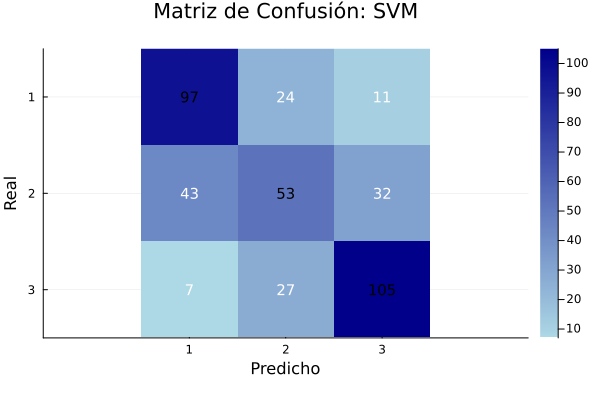

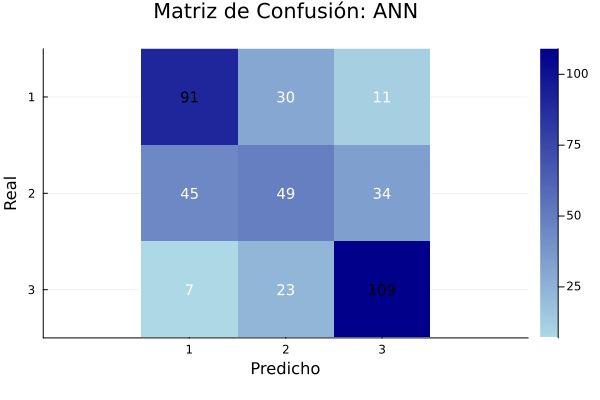

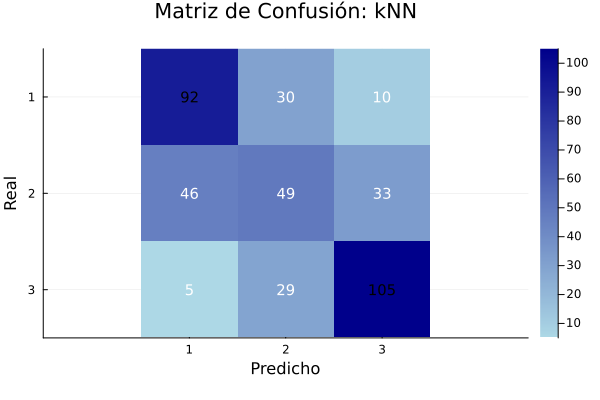

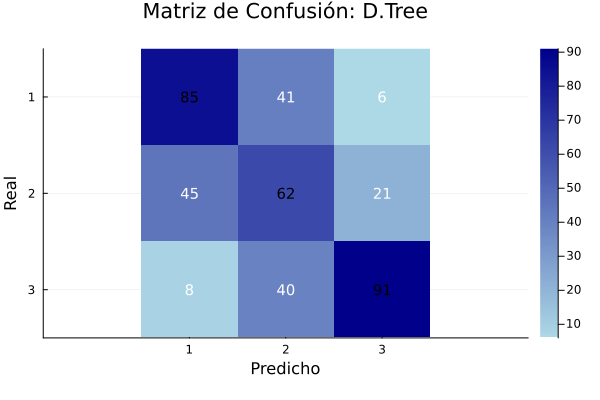


📂 Procesando Dataset: Filtered by Correlation
Transformando target continuo a 3 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 68.78% ± 4.66%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 68.47% ± 4.21%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 68.78% ± 4.79%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 69.85% ± 4.37%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 66.28% ± 4.23%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 68.40% ± 4.40%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 70.16% ± 4.27%
SVM             | Dict{Symbol, Any}(:degree => 2, ... | Acc: 63.08% ± 5.00%
ANN             | Dict{Symbol, Any}(:max

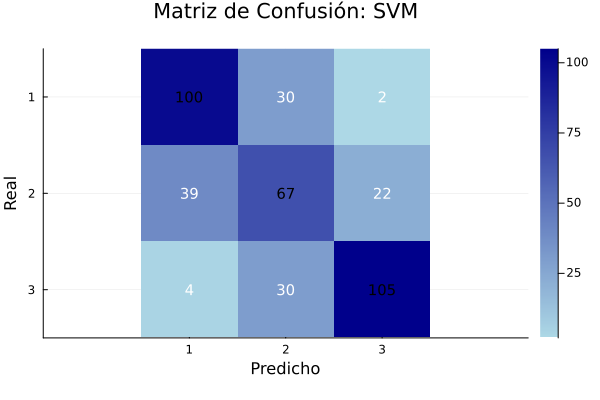

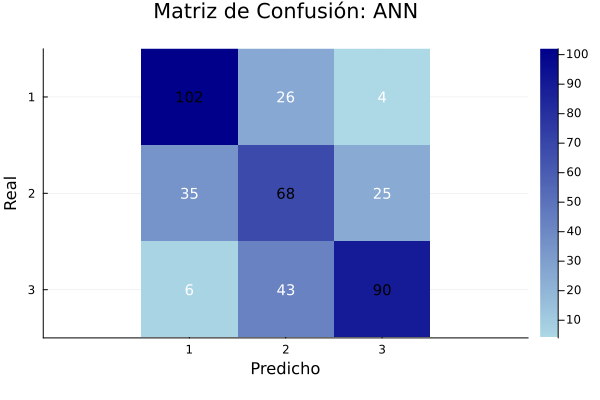

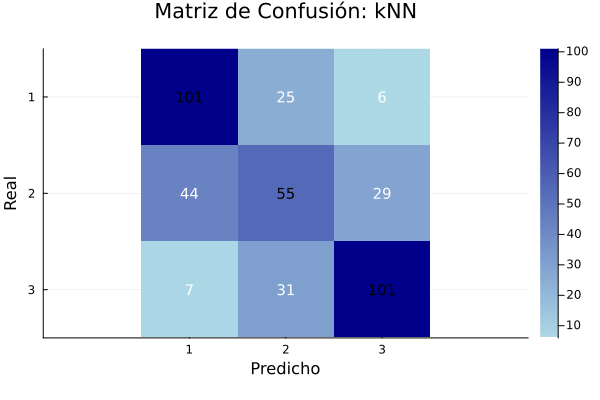

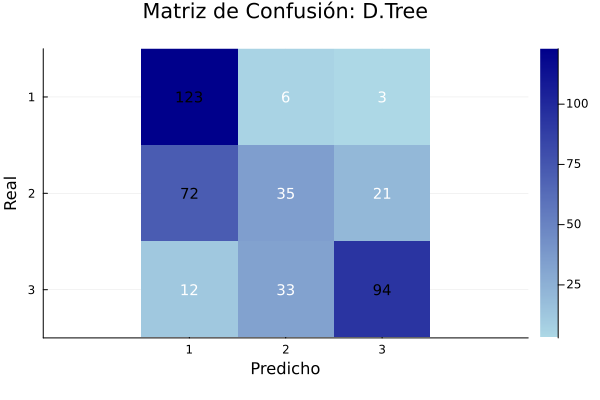


📂 Procesando Dataset: PCA (95% Var)
Transformando target continuo a 3 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 68.78% ± 3.35%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 69.47% ± 3.43%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 69.28% ± 3.44%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 69.46% ± 3.41%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 64.89% ± 3.92%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 67.58% ± 3.89%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 69.90% ± 3.53%
SVM             | Dict{Symbol, Any}(:degree => 2, ... | Acc: 61.32% ± 3.53%
ANN             | Dict{Symbol, Any}(:maxEpochs => 

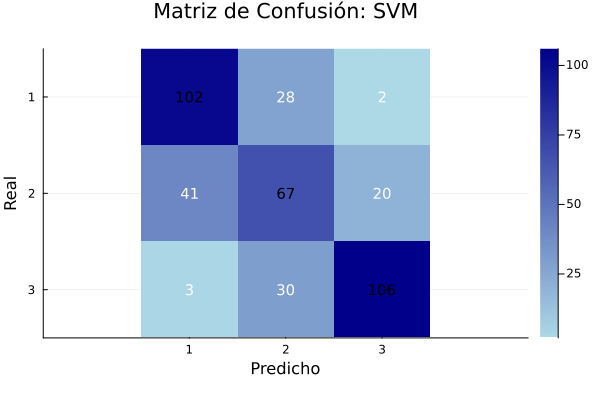

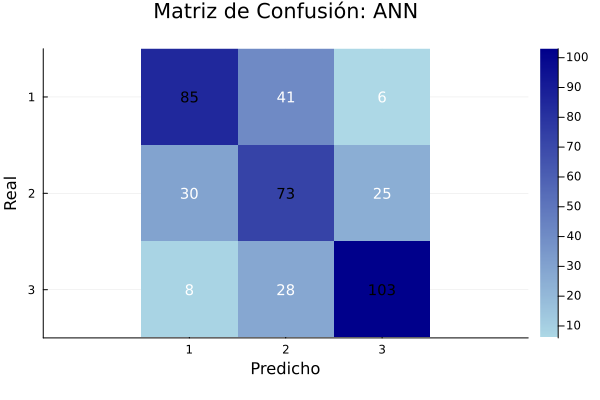

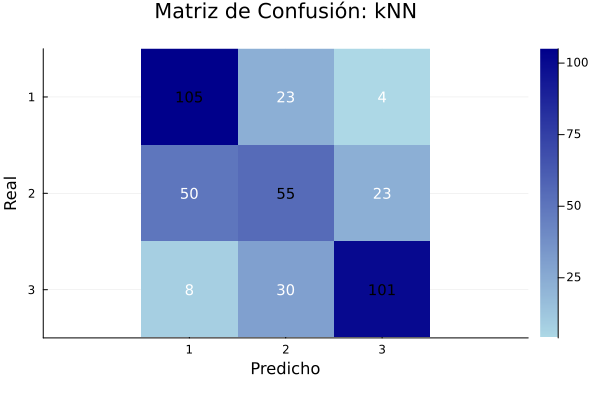

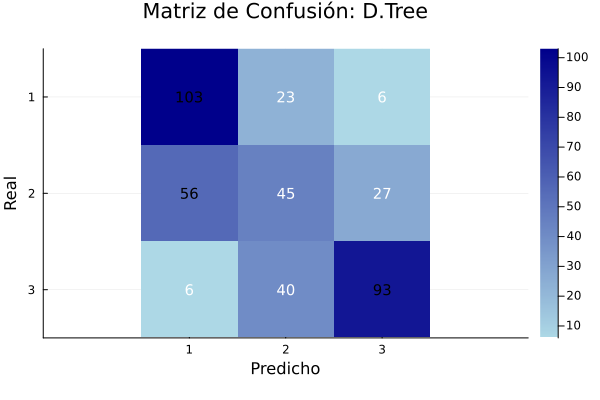

In [37]:
println("🏁 INICIANDO SUITE DE EXPERIMENTOS MODULARIZADA (Backend: Training.jl)")
suites_3 = Dict(
)
for (dataset_name, X_data) in experiment_inputs
    println("\n=============================================")
    println("📂 Procesando Dataset: $dataset_name")
    
    # A. Instanciar la Suite
    # Nota: Pasamos 'my_models' que ya tiene el formato correcto para Training.jl
    suite = ExperimentSuite(
        X_data, 
        target,
        experiment_tests[dataset_name],
        test_output,
        :classification;
        n_classes = 3, # Cuantiles
        models_config = my_models
    )
    
    # B. Ejecutar Experimentos
    # Esto llamará a Training.modelCrossValidation internamente
    run_experiments!(suite)
    
    suites_3[dataset_name] = suite
    # C. Visualizar Resultados
    println("\n📊 Resumen Gráfico para $dataset_name:")
    for (model_name, model_parameters) in my_models
        visualize_results(suite, type=:heatmap, model_name=model_name)
    end
end


📊 Resumen Gráfico para Raw Attributes:
📊 Generando comparativa de rendimiento en Test Set...
SVM0.6942355889724311
ANN0.656641604010025
kNN0.6416040100250626
D.Tree0.6616541353383458


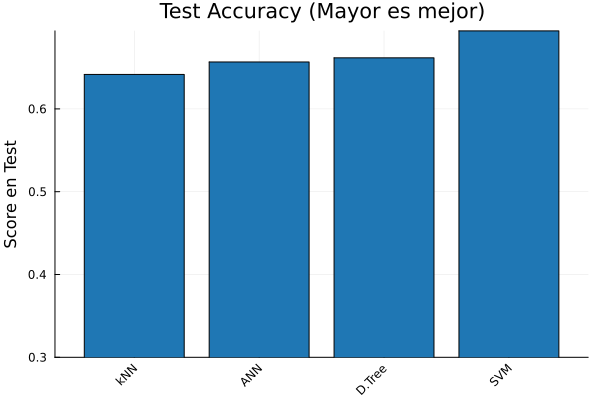


📊 Resumen Gráfico para PCA (99% Var):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.6967418546365914
ANN0.6390977443609023
kNN0.6240601503759399
D.Tree0.6040100250626567


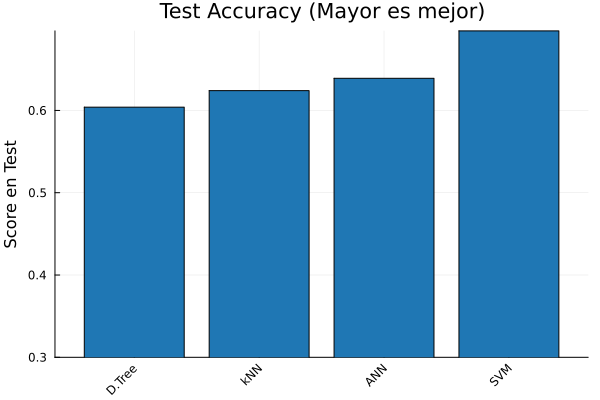


📊 Resumen Gráfico para ICA (2 Comp):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.6390977443609023
ANN0.6240601503759399
kNN0.6165413533834586
D.Tree0.5964912280701754


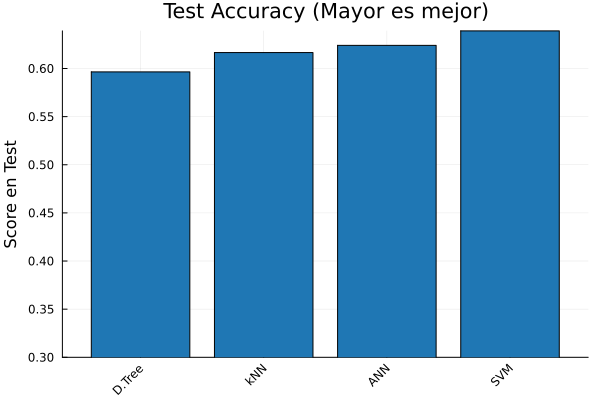


📊 Resumen Gráfico para Filtered by Correlation:
📊 Generando comparativa de rendimiento en Test Set...
SVM0.681704260651629
ANN0.6516290726817042
kNN0.6441102756892231
D.Tree0.631578947368421


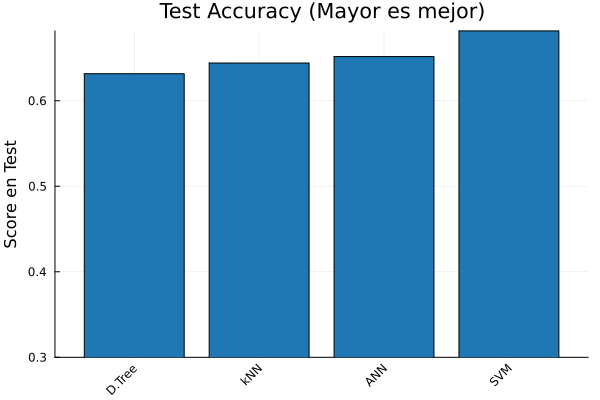


📊 Resumen Gráfico para PCA (95% Var):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.6892230576441103
ANN0.6541353383458647
kNN0.6541353383458647
D.Tree0.6040100250626567


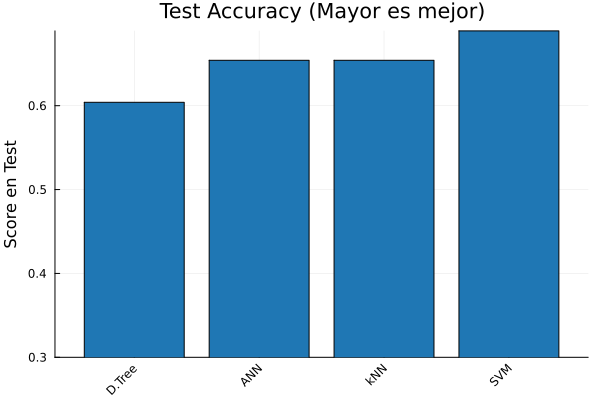

In [38]:
for (dataset_name, X_data) in experiment_inputs
    println("\n📊 Resumen Gráfico para $dataset_name:")
    visualize_results(suites_3[dataset_name], type=:bar)
end


In [ ]:
println("🏁 INICIANDO SUITE DE EXPERIMENTOS MODULARIZADA (Backend: Training.jl)")
suites_2 = Dict(
)
for (dataset_name, X_data) in experiment_inputs
    println("\n=============================================")
    println("📂 Procesando Dataset: $dataset_name")
    
    # A. Instanciar la Suite
    # Nota: Pasamos 'my_models' que ya tiene el formato correcto para Training.jl
    suite = ExperimentSuite(
        X_data, 
        target,
        experiment_tests[dataset_name],
        test_output,
        :classification;
        n_classes = 2, # Cuantiles
        models_config = my_models
    )
    
    # B. Ejecutar Experimentos
    # Esto llamará a Training.modelCrossValidation internamente
    run_experiments!(suite)
    
    suites_2[dataset_name] = suite
    # C. Visualizar Resultados
    println("\n📊 Resumen Gráfico para $dataset_name:")
    for (model_name, model_parameters) in my_models
        visualize_results(suite, type=:heatmap, model_name=model_name)
    end
end

🏁 INICIANDO SUITE DE EXPERIMENTOS MODULARIZADA (Backend: Training.jl)

📂 Procesando Dataset: Raw Attributes
Transformando target continuo a 2 clases usando cuantiles...

🚀 Iniciando ejecución de experimentos para tarea: classification
Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 85.23% ± 2.25%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 82.63% ± 3.67%
SVM             | Dict{Symbol, Any}(:kernel => "LI... | Acc: 82.26% ± 3.70%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 85.48% ± 1.56%
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | Acc: 59.92% ± 2.72%
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | Acc: 82.76% ± 3.26%
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | Acc: 84.87% ± 3.16%
SVM             | Dict{Symbol, Any}(:degree => 2, ... |


📊 Resumen Gráfico para Raw Attributes:
📊 Generando comparativa de rendimiento en Test Set...
SVM0.8446115288220551
ANN0.8370927318295739
kNN0.8095238095238095
D.Tree0.7969924812030075


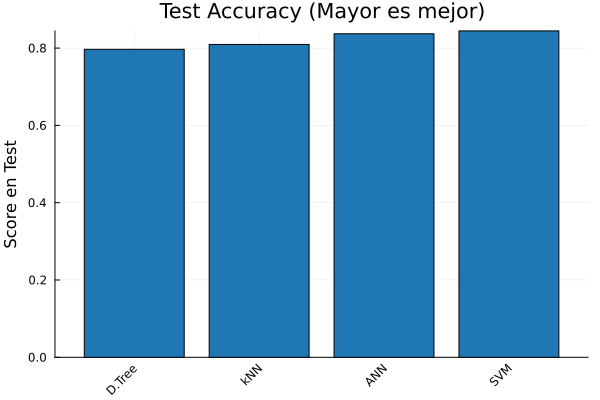


📊 Resumen Gráfico para PCA (99% Var):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.8320802005012531
ANN0.7944862155388471
kNN0.8120300751879699
D.Tree0.7794486215538847


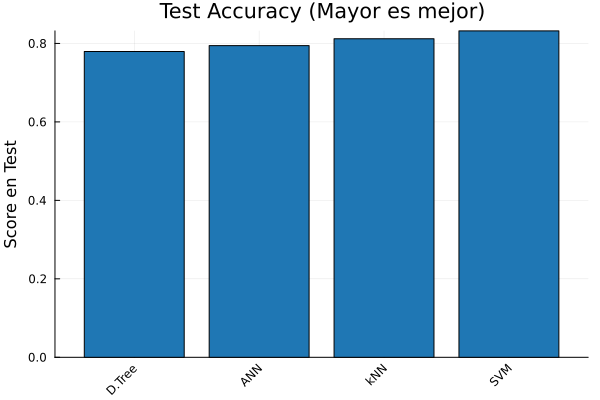


📊 Resumen Gráfico para ICA (2 Comp):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.7844611528822055
ANN0.7919799498746867
kNN0.7894736842105263
D.Tree0.7644110275689223


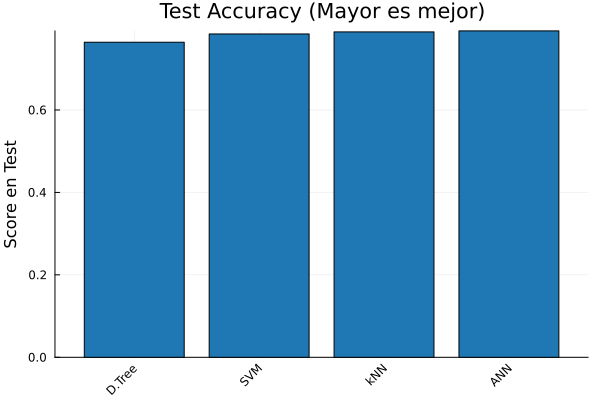


📊 Resumen Gráfico para Filtered by Correlation:
📊 Generando comparativa de rendimiento en Test Set...
SVM0.8345864661654135
ANN0.8145363408521303
kNN0.8095238095238095
D.Tree0.7744360902255639


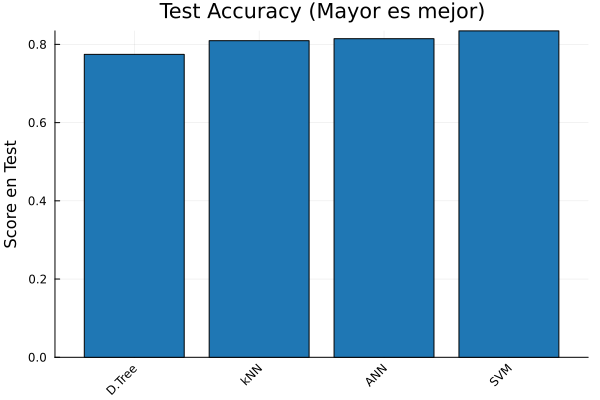


📊 Resumen Gráfico para PCA (95% Var):
📊 Generando comparativa de rendimiento en Test Set...
SVM0.8370927318295739
ANN0.8045112781954887
kNN0.8245614035087719
D.Tree0.7794486215538847


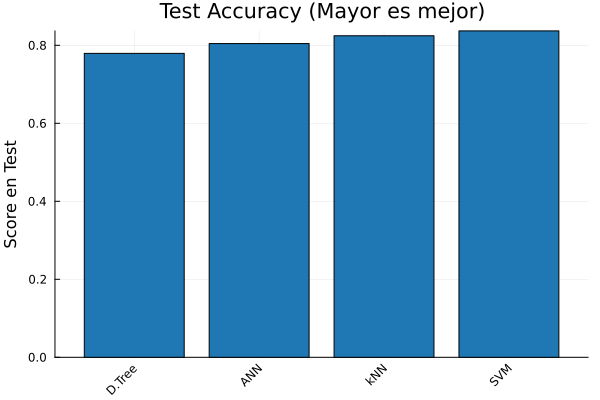

In [ ]:
for (dataset_name, X_data) in experiment_inputs
    
    println("\n📊 Resumen Gráfico para $dataset_name:")
    visualize_results(suites_2[dataset_name], type=:bar)
end


In [ ]:
EpsilonSVR = @load EpsilonSVR pkg=LIBSVM verbosity=0
DTRegressor = @load DecisionTreeRegressor pkg=DecisionTree verbosity=0
KNNRegressor = @load KNNRegressor pkg=NearestNeighborModels verbosity=0
NeuralNetworkRegressor = @load NeuralNetworkRegressor pkg=MLJFlux verbosity=0

function run_experiments_regression!(suite::ExperimentSuite; measure=nothing)
    println("\n🚀 Iniciando ejecución de experimentos para tarea: $(suite.task_type)")
    println("==================================================================================================")
    println("Model           | Configuration                        | Result (CV RMSE ± SD)")
    println("--------------------------------------------------------------------------------------------------") 
    # 1. Preparar Dataset Tuple para Training module (Matriz Float32, Vector)
    current_targets_reg=Float32.(suite.y)
    inputs=Float32.(suite.X)
    # 2. Generar Índices de CrossValidation usando Sampling
    k_folds = 10
    cv_indices_reg = Sampling.crossvalidation(length(suite.y), k_folds)

    # 3. Iterar sobre Modelos y Configuraciones
    for (model_name, (model_symbol, param_configs)) in suite.models_config
        # model_symbol: Símbolo esperado por Training (ej. :ANN, :SVC)
        # param_configs: Vector de diccionarios con los parámetros a probar
        
        best_rmse = 100000.0
        best_std_rmse = 0
        best_result_obj = nothing
        mach = nothing
        for params in param_configs
                          

                rmse_folds = Float32[]
                for k in 1:k_folds
                    train_mask = cv_indices_reg .!= k
                    test_mask = cv_indices_reg .== k

                    if model_symbol == :ANN
                        model = NeuralNetworkRegressor(;params...)
                        pipe = Standardizer() |> model
                        mach = machine(pipe, MLJ.table(inputs[train_mask, :]), current_targets_reg[train_mask])

                    elseif model_symbol == :SVC
                        model = EpsilonSVR(;params...)
                        pipe = Standardizer() |> model
                        mach = machine(pipe, MLJ.table(inputs[train_mask, :]), current_targets_reg[train_mask])
                    
                    elseif model_symbol == :DecisionTreeClassifier
                        model = DTRegressor(;params...)
                        mach = machine(model, MLJ.table(inputs[train_mask, :]), current_targets_reg[train_mask])

                    elseif model_symbol == :KNeighborsClassifier
                        model = KNNRegressor(;params...)
                        mach = machine(model, MLJ.table(inputs[train_mask, :]), current_targets_reg[train_mask])

                    end
                    
                    MLJ.fit!(mach, verbosity=0)
                    preds = MLJ.predict(mach, MLJ.table(inputs[test_mask, :]))
                    
                    rmse, _ = evaluate_regression(preds, current_targets_reg[test_mask])
                    push!(rmse_folds, rmse)
                end
                
                # Formatear configuración para display
                config_str = string(params)
                if length(config_str) > 35
                    config_str = config_str[1:32] * "..."
                end
                rmse_mean = mean(rmse_folds)
                rmse_std = std(rmse_folds)
                # Log en consola estilo tabla
                @printf("%-15s | %-35s | RMSE: %.2f ± %.2f\n", 
                        model_name, config_str, rmse_mean, rmse_std)
                
                # Guardar el mejor resultado localmente
                
                if rmse_mean < best_rmse
                    best_rmse = rmse_mean
                    best_std_rmse = rmse_std
                    best_result_obj = ((best_rmse, best_std_rmse), model_symbol, params)
                end
                
        end
        
        # 4. Almacenar el mejor resultado en la Suite
        if best_result_obj !== nothing
            model_symbol = best_result_obj[2]
            final_res = best_result_obj[1]
            rmse = final_res[1]
            params = best_result_obj[3]
            mach = nothing
            if model_symbol == :ANN    
                # Instantiate model
                final_model = NeuralNetworkRegressor(;params...)
                final_pipe = Standardizer() |> final_model
                final_mach = machine(final_pipe, MLJ.table(inputs), suite.y)

            elseif model_symbol == :SVC
                final_model = EpsilonSVR(;params...)
                final_pipe = Standardizer() |> final_model
                final_mach = machine(final_pipe, MLJ.table(suite.X), suite.y)
            
            elseif model_symbol == :DecisionTreeClassifier
                final_model = DTRegressor(;params...)
                final_mach = machine(final_model, MLJ.table(suite.X), suite.y)

            elseif model_symbol == :KNeighborsClassifier
                final_model = KNNRegressor(;params...)
                final_mach = machine(final_model, MLJ.table(suite.X), suite.y)
            end
            MLJ.fit!(final_mach, rows=1:size(suite.X, 1), verbosity=0)
            
            suite.results[model_name] = (
                metric_score = best_rmse,
                report = final_res,
                history = nothing # No disponible en legacy mode
            )
            
            if final_mach !== nothing
                suite.best_machines[model_name] = final_mach
            end
        end
    end
    println("--------------------------------------------------------------------------------------------------")
end

run_experiments_regression! (generic function with 1 method)

🏁 INICIANDO SUITE DE EXPERIMENTOS MODULARIZADA (Backend: Training.jl)

📂 Procesando Dataset: Raw Attributes

🚀 Iniciando ejecución de experimentos para tarea: regression
Model           | Configuration                        | Result (CV RMSE ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.32 ± 0.03
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.33 ± 0.05


SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.33 ± 0.04
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.33 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.29 ± 0.06
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.38 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | RMSE: 0.34 ± 0.03
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.95 ± 0.39
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.16 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.15 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.16 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.16 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.15 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.15 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.15 ± 0.01
ANN             | Dict{Symbol, Any}(:b

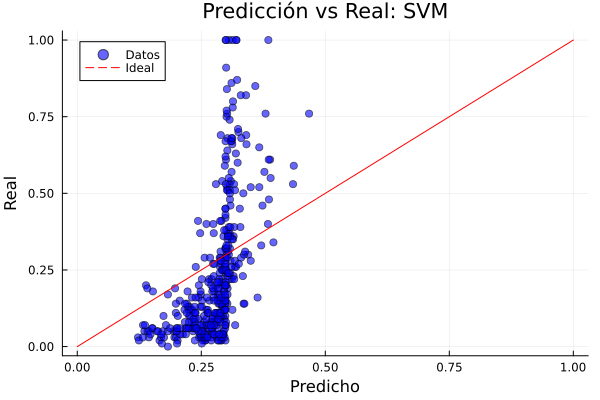

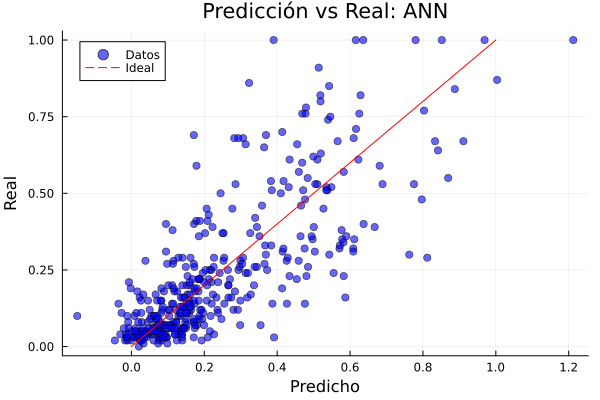

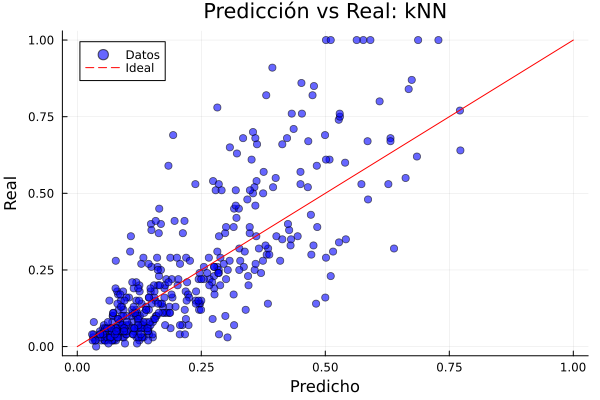

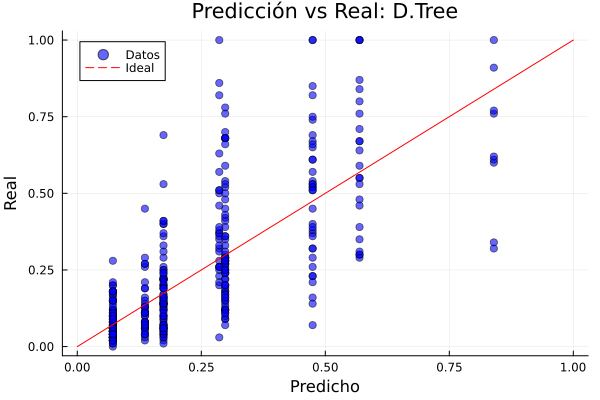


📂 Procesando Dataset: PCA (99% Var)

🚀 Iniciando ejecución de experimentos para tarea: regression
Model           | Configuration                        | Result (CV RMSE ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.33 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.33 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.34 ± 0.06
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.33 ± 0.07
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.30 ± 0.12
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.49 ± 0.28
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | RMSE: 0.36 ± 0.04
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 2.70 ± 3.14
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.17 ± 0.02
ANN             | Dict{Symbol, Any}(:batch_size =>... | R

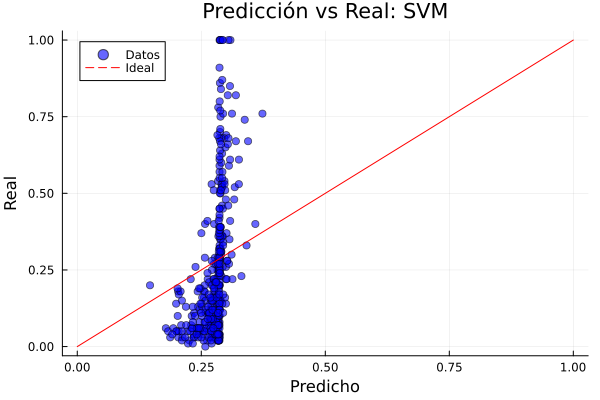

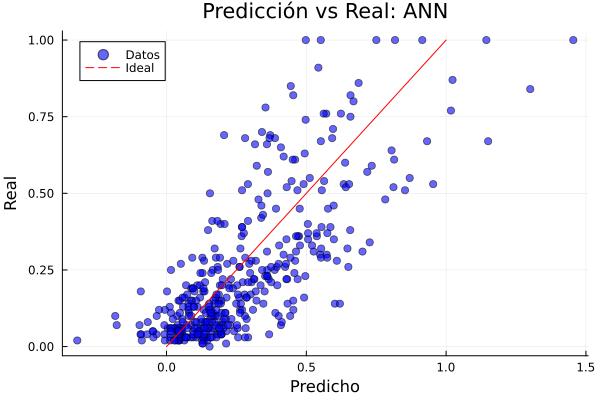

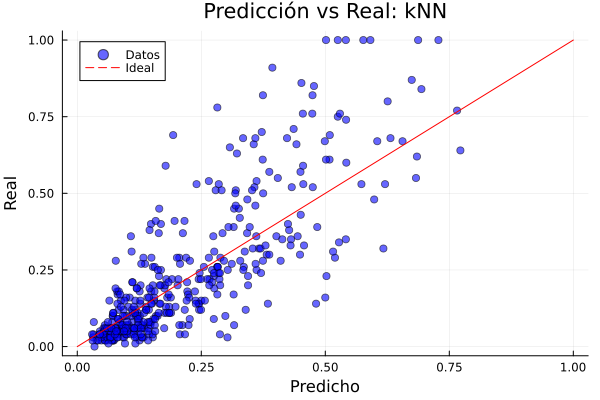

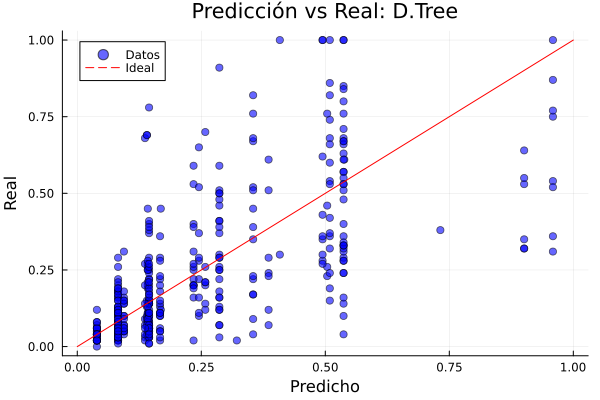


📂 Procesando Dataset: ICA (2 Comp)

🚀 Iniciando ejecución de experimentos para tarea: regression
Model           | Configuration                        | Result (CV RMSE ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: NaN ± NaN
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.35 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.33 ± 0.06
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.34 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.34 ± 0.06
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.34 ± 0.06
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | RMSE: 0.30 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.30 ± 0.06
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.17 ± 0.02
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE

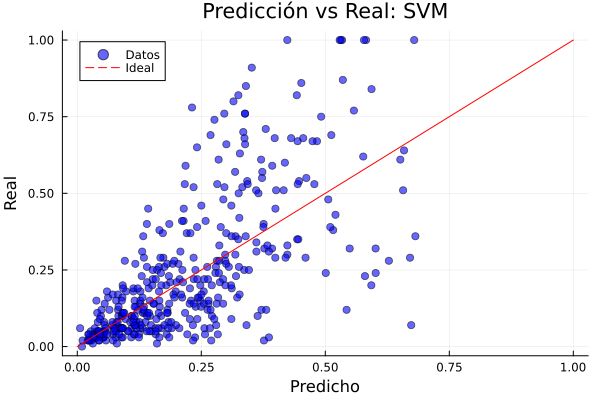

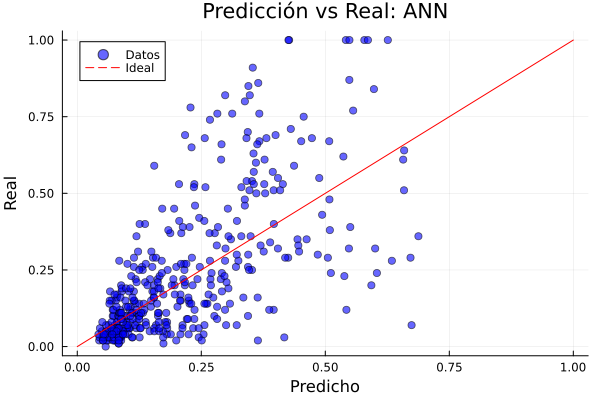

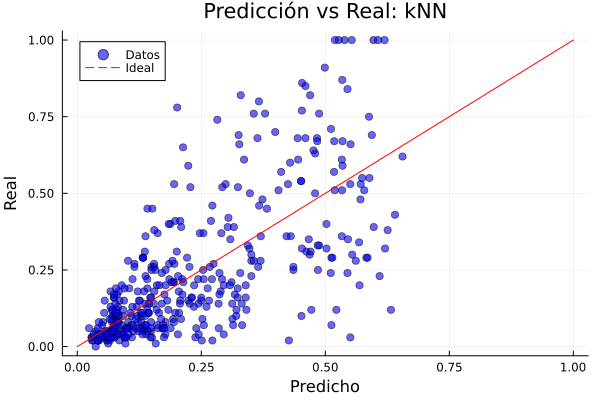

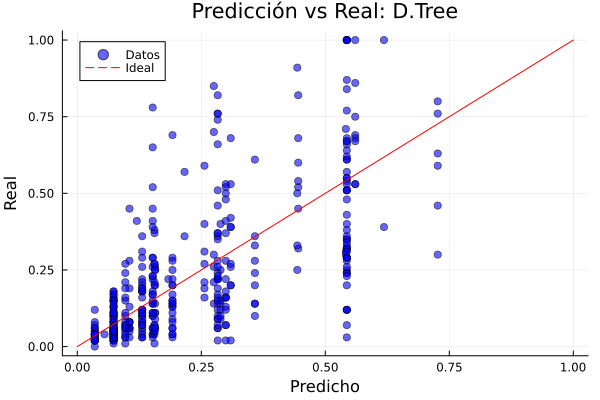


📂 Procesando Dataset: Filtered by Correlation

🚀 Iniciando ejecución de experimentos para tarea: regression
Model           | Configuration                        | Result (CV RMSE ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.32 ± 0.04
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: NaN ± NaN


SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.35 ± 0.03
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.32 ± 0.03
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.35 ± 0.06
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.38 ± 0.07
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | RMSE: 0.35 ± 0.03
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.80 ± 0.75
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.15 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.15 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.16 ± 0.02
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.16 ± 0.02
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.15 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.16 ± 0.02
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.16 ± 0.01
ANN             | Dict{Symbol, Any}(:b

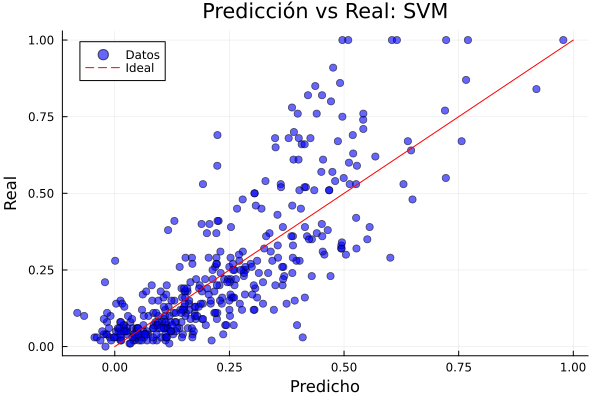

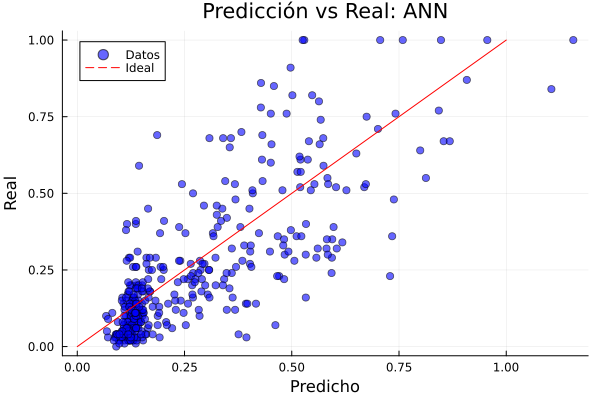

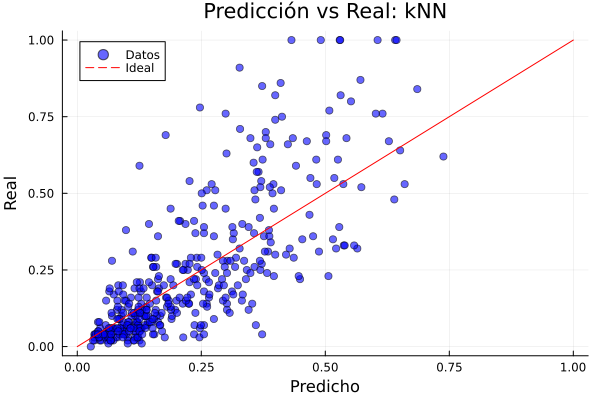

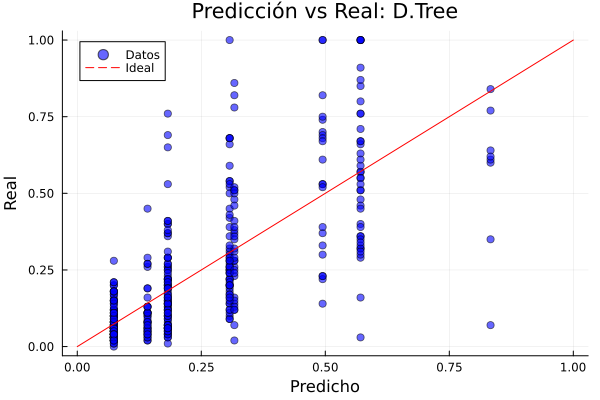


📂 Procesando Dataset: PCA (95% Var)

🚀 Iniciando ejecución de experimentos para tarea: regression
Model           | Configuration                        | Result (CV RMSE ± SD)
--------------------------------------------------------------------------------------------------
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.34 ± 0.04
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.34 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.34 ± 0.05
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.33 ± 0.02
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.33 ± 0.06
SVM             | Dict{Symbol, Any}(:gamma => 0.01... | RMSE: 0.37 ± 0.04
SVM             | Dict{Symbol, Any}(:gamma => 0.00... | RMSE: 0.34 ± 0.04
SVM             | Dict{Symbol, Any}(:gamma => 0.1,... | RMSE: 0.42 ± 0.08
ANN             | Dict{Symbol, Any}(:batch_size =>... | RMSE: 0.15 ± 0.01
ANN             | Dict{Symbol, Any}(:batch_size =>... | R

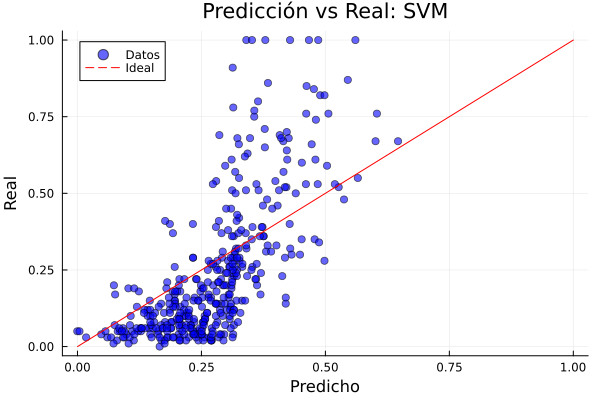

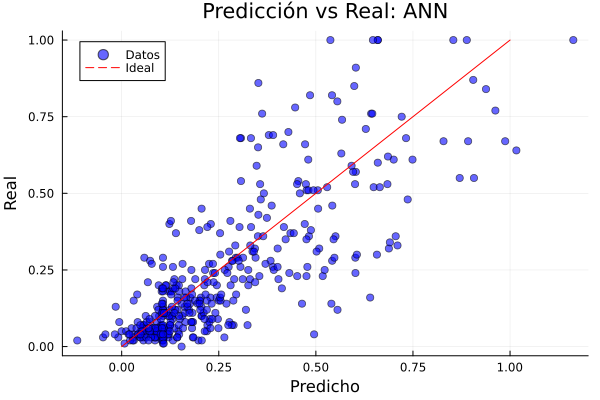

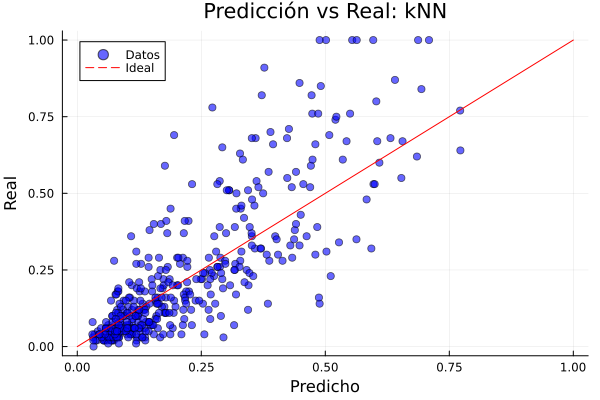

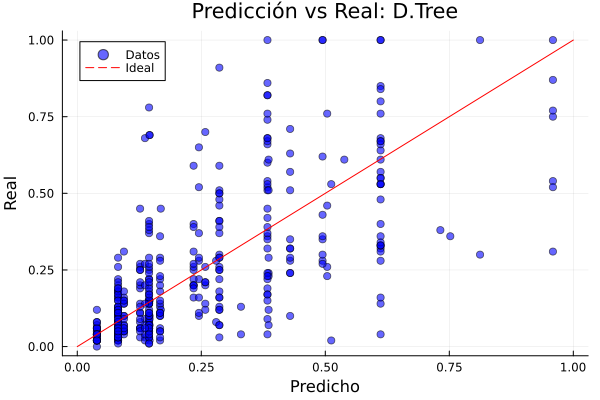

In [ ]:
# Asegúrate de tener cargado el módulo MLTools

# using Flux # Necesario para la configuración de ANN (relu)

# ==========================================
# 1. DEFINICIÓN DE LA CONFIGURACIÓN (MODELS CONFIG)
# ==========================================
# Adaptamos los rangos al formato que espera Training.modelCrossValidation:
# "Nombre" => (:SimboloModelo, [Lista de Diccionarios de Parámetros])

# --- k-Nearest Neighbors ---
# K = 1, 3, 5, 7, 11, 21
knn_configs = [Dict(:K => k) for k in [1, 3, 5, 7, 11, 21]]

# --- Decision Tree ---
# Depths = 3, 5, 7, 9, 15, 20
dt_configs = [Dict(:max_depth => d) for d in [3, 5, 7, 9, 15, 20]]

# --- SVM ---
svm_configs = [
    Dict(:kernel=>LIBSVM.Kernel.Linear, :cost=>1.0, :gamma=>0.1),
    Dict(:kernel=>LIBSVM.Kernel.Linear, :cost=>0.1, :gamma=>0.1),
    Dict(:kernel=>LIBSVM.Kernel.Linear, :cost=>10.0, :gamma=>0.1),
    Dict(:kernel=>LIBSVM.Kernel.RadialBasis, :cost=>1.0, :gamma=>0.01),
    Dict(:kernel=>LIBSVM.Kernel.RadialBasis, :cost=>1.0, :gamma=>0.1),
    Dict(:kernel=>LIBSVM.Kernel.RadialBasis, :cost=>10.0, :gamma=>0.01),
    Dict(:kernel=>LIBSVM.Kernel.RadialBasis, :cost=>100.0, :gamma=>0.001),
    Dict(:kernel=>LIBSVM.Kernel.Polynomial, :cost=>1.0, :gamma=>0.1, :degree=>Int32(2))

]


# --- Artificial Neural Networks (ANN) ---
# Topologías variadas

#ann_topologies = [[8,], [16,], [32,], [64,], [8, 8], [16, 16], [32, 32], [64, 64]]

ann_topologies = [(8,), (16,), (32,), (64,), (8,8), (16, 16), (32, 32), (64, 64)]

ann_epoch = [77, 20, 15, 7, 8, 8, 5, 5]

i = 1
ann_configs = []
for topo in ann_topologies
    current = Dict(
        :builder => MLJFlux.MLP(topo, Flux.relu),
        :epochs => ann_epoch[i],  
        :batch_size => 32,
        :optimiser => Optimisers.Adam(0.01)
    )
    
    push!(ann_configs, current)
    i = i + 1   
end

# DICCIONARIO MAESTRO
# Mapea Nombre -> (Simbolo para Training.jl, Lista de Configs)
my_models = Dict(
    "kNN"        => (:KNeighborsClassifier, knn_configs),
    "D.Tree"     => (:DecisionTreeClassifier, dt_configs),
    "SVM"        => (:SVC, svm_configs),
    "ANN"        => (:ANN, ann_configs)
)

# ==========================================
# 2. DATOS DE ENTRADA
# ==========================================
# Asumo que 'train_input', 'train_corr', etc. están en tu workspace
experiment_inputs = Dict(
    "Raw Attributes"          => Float32.(train_input),
    "Filtered by Correlation" => Float32.(train_corr), 
    "PCA (95% Var)"           => Float32.(pca_train),
    "PCA (99% Var)"           => Float32.(pca_train_99),
    "ICA (2 Comp)"            => Float32.(ica_train)
)

experiment_tests = Dict(
    "Raw Attributes"          => Float32.(test_input),
    "Filtered by Correlation" => Float32.(test_corr), 
    "PCA (95% Var)"           => Float32.(pca_test),
    "PCA (99% Var)"           => Float32.(pca_test_99),
    "ICA (2 Comp)"            => Float32.(ica_test)
)
target = train_output # Tu vector de salida

suites = Dict(
)
# ==========================================
# 3. EJECUCIÓN
# ==========================================
println("🏁 INICIANDO SUITE DE EXPERIMENTOS MODULARIZADA (Backend: Training.jl)")

for (dataset_name, X_data) in experiment_inputs
    println("\n=============================================")
    println("📂 Procesando Dataset: $dataset_name")
    
    # A. Instanciar la Suite
    # Nota: Pasamos 'my_models' que ya tiene el formato correcto para Training.jl
    suite = ExperimentSuite(
        X_data, 
        target,
        experiment_tests[dataset_name],
        test_output,
        :regression;
        n_classes = 4, # Cuantiles
        models_config = my_models
    )
    
    # B. Ejecutar Experimentos
    # Esto llamará a Training.modelCrossValidation internamente
    run_experiments_regression!(suite)
    
    suites[dataset_name] = suite
    # C. Visualizar Resultados
    println("\n📊 Resumen Gráfico para $dataset_name:")
    for (model_name, model_parameters) in my_models
        visualize_results(suite, type=:scatter, model_name=model_name)
    end
end

In [ ]:
for (dataset_name, X_data) in experiment_inputs
    
    println("\n📊 Resumen Gráfico para $dataset_name:")
    visualize_results(suites[dataset_name], type=:bar)
end


In [ ]:
using DecisionTree

s = suites["Raw Attributes"]
# 1. Retrieve the names of the variables
# Exclude the last column because it is the target (ViolentCrimesPerPop)
feature_names = names(df)[1:end-1]

# Safety check:
println("Number of variables (Names): ", length(feature_names))
println("Number of columns in Train Input: ", size(s.X, 2))

mach_tree = s.best_machines["D.Tree"]

# 3. Extract Importance
# MLJ returns a vector like [:x1 => 0.3, :x5 => 0.1, ...]
raw_importances = feature_importances(mach_tree)

# 4. Map the generic indices (x1, x2...) to your Real Names
named_importances = []

for (feature_sym, score) in raw_importances
    # The symbol is like :x12. Convert it to string "x12"
    f_str = string(feature_sym)
    
    # Remove the "x" and convert the number to integer (e.g., "12" -> 12)
    idx = parse(Int, f_str[2:end])
    
    # Find the real name in the list we extracted from df
    real_name = feature_names[idx]
    
    push!(named_importances, (real_name, score))
end

# 5. Sort and Prepare Plot
sort!(named_importances, by = x -> x[2], rev=true) # From largest to smallest

# Take the Top 15
top_n = 15
top_data = named_importances[1:top_n]
labels = [x[1] for x in top_data]
values = [x[2] for x in top_data]


# 6. Print the list to the screen
println("\n=== TOP 10 PREDICTIVE VARIABLES ===")
for i in 1:10
@printf("%d. %-25s : %.4f%%\n", i, labels[i], values[i]*100)
end


Number of variables (Names): 100
Number of columns in Train Input: 100

=== TOP 10 PREDICTIVE VARIABLES ===
1. PctIlleg                  : 66.3582%
2. PctKids2Par               : 11.7121%
3. PctFam2Par                : 9.5118%
4. racePctWhite              : 4.3017%
5. PctBornSameState          : 4.2133%
6. NumUnderPov               : 2.9905%
7. racePctHisp               : 0.9125%
8. population                : 0.0000%
9. householdsize             : 0.0000%
10. racepctblack              : 0.0000%


In [ ]:
s = suites["Filtered by Correlation"]
# 1. Retrieve the names of the variables
# Exclude the last column because it is the target (ViolentCrimesPerPop)
feature_names = names(df_limpio)[1:end-1]

# Safety check:
println("Number of variables (Names): ", length(feature_names))
println("Number of columns in Train Input: ", size(s.X, 2))

mach_tree = s.best_machines["D.Tree"]

# 3. Extract Importance
# MLJ returns a vector like [:x1 => 0.3, :x5 => 0.1, ...]
raw_importances = feature_importances(mach_tree)

# 4. Map the generic indices (x1, x2...) to your Real Names
named_importances = []

for (feature_sym, score) in raw_importances
    # The symbol is like :x12. Convert it to string "x12"
    f_str = string(feature_sym)
    
    # Remove the "x" and convert the number to integer (e.g., "12" -> 12)
    idx = parse(Int, f_str[2:end])
    
    # Find the real name in the list we extracted from df
    real_name = feature_names[idx]
    
    push!(named_importances, (real_name, score))
end

# 5. Sort and Prepare Plot
sort!(named_importances, by = x -> x[2], rev=true) # From largest to smallest

# Take the Top 15
top_n = 15
top_data = named_importances[1:top_n]
labels = [x[1] for x in top_data]
values = [x[2] for x in top_data]


# 6. Print the list to the screen
println("\n=== TOP 10 PREDICTIVE VARIABLES ===")
for i in 1:10
@printf("%d. %-25s : %.4f%%\n", i, labels[i], values[i]*100)
end

Number of variables (Names): 44
Number of columns in Train Input: 44

=== TOP 10 PREDICTIVE VARIABLES ===
1. PctKids2Par               : 88.1733%
2. PctPersDenseHous          : 9.1208%
3. NumIlleg                  : 2.7058%
4. racePctAsian              : 0.0000%
5. agePct12t29               : 0.0000%
6. pctUrban                  : 0.0000%
7. pctWFarmSelf              : 0.0000%
8. pctWInvInc                : 0.0000%
9. pctWPubAsst               : 0.0000%
10. pctWRetire                : 0.0000%


After the cross validation, we have obtained the results of the different models with each configuration for each preprocessing strategy.
Here we are using the best for each preprocessing strategy with the whole training set.

And now, we are plotting the confussion matrix for the best models, to see which results are more interesting

This is an accuracy comparison for the aforementioned models

Now, we do the same as in classification but for regression. To do so, instead of the accuracy, we are checking the RMSE (or root mean squared error).

In [ ]:
typeof(best_ann_model)

MLJFlux.NeuralNetworkRegressor{MLJFlux.MLP{2}, Optimisers.Adam, typeof(Flux.Losses.mse)}

In [ ]:
include("src/Ensembles.jl")

Main.Ensembles

In [ ]:
using .Ensembles

In [ ]:
using Statistics
using DataFrames, PrettyTables
using Plots
using StatsPlots
using Plots.Measures
gr()

function plotEnsembleConfusionsIndividual(
    ensemble_results::Dict{String, Tuple{Vector{String}, Vector{String}}},
    base_title::AbstractString;
    class_labels::Union{Nothing,Vector{String}} = nothing,
    save_dir::Union{Nothing,String} = nothing,
    file_prefix::AbstractString = ""
)
    # 1) Orden “bonito” de las representaciones
    preferred_order = [
        "Raw Attributes",
        "Filtered by Correlation",
        "PCA (95% Var)",
        "PCA (99% Var)",
        "ICA (2 Comp)"
    ]

    names = [n for n in preferred_order if haskey(ensemble_results, n)]
    if length(names) < length(ensemble_results)
        for n in sort(collect(keys(ensemble_results)))
            if !(n in names)
                push!(names, n)
            end
        end
    end

    # Si hay carpeta para guardar, asegúrate de que exista
    if save_dir !== nothing
        isdir(save_dir) || mkpath(save_dir)
    end

    for repr_name in names
        outputs, targets = ensemble_results[repr_name]

        # --- clases presentes en esa representación ---
        classes = unique(vcat(outputs, targets))

        # Orden numérico si se puede, si no alfabético
        sorted_classes = try
            sort(classes, by = x -> parse(Float64, string(x)))
        catch
            sort(classes)
        end

        n         = length(sorted_classes)
        coords    = 1:n
        class_idx = Dict(c => i for (i, c) in enumerate(sorted_classes))
        mat       = zeros(Int, n, n)

        # Matriz de confusión (filas = real, columnas = predicho)
        for (pred, real) in zip(outputs, targets)
            if haskey(class_idx, real) && haskey(class_idx, pred)
                r = class_idx[real]
                c = class_idx[pred]
                mat[r, c] += 1
            end
        end

        ann = [
            (j, i, text(string(mat[i, j]), 8, :black, :center, :center))
            for i in 1:n, j in 1:n
        ]

        # Etiquetas de clase “bonitas” si se pasan y cuadran en longitud
        display_labels =
            (class_labels !== nothing && length(class_labels) == n) ?
                class_labels :
                string.(sorted_classes)

        # Título de esta figura
        title_str = "$base_title – $repr_name"

        p = heatmap(
            coords,
            coords,
            mat;
            color         = :blues,
            aspect_ratio  = 1,
            xrotation     = 45,
            yflip         = true,
            xlabel        = "Predicted",
            ylabel        = "Real",
            title         = title_str,
            annotations   = vec(ann),
            xticks        = (coords, display_labels),
            yticks        = (coords, string.(sorted_classes)),
            size          = (700, 600)
        )

        display(p)

        if save_dir !== nothing
            safe_repr   = replace(repr_name, " " => "_", r"[^\w\-]" => "")
            safe_prefix = replace(file_prefix, " " => "_", r"[^\w\-]" => "")
            fname = isempty(safe_prefix) ?
                "cm_$(safe_repr).png" :
                "$(safe_prefix)_$(safe_repr).png"

            file_path = joinpath(save_dir, fname)
            savefig(p, file_path)
            println("Saved confusion matrix for '$repr_name' to: $file_path")
        end
    end

    return nothing
end

function plot_regression_ensemble_comparison(
    summary_hard,
    summary_equal,
    summary_weighted,
    summary_stacking,
    ordered_datasets::Vector{String};
    ensemble_labels = ["Hard Voting" "Equal Weights" "Weighted" "Stacking"],
    title::AbstractString = "Comparison of Regression Ensembles – Test RMSE",
    ylabel::AbstractString = "RMSE (Lower is better)",
    xlabel::AbstractString = "Data Strategy",
    save_path::Union{Nothing,String} = nothing
)

    # 2) Matriz (n_datasets x 4)
    final_data_ensembles = hcat(
        summary_hard.metrics,
        summary_equal.metrics,
        summary_weighted.metrics,
        summary_stacking.metrics
    )

    dataset_names = ordered_datasets

    p = groupedbar(
        final_data_ensembles;
        labels       = ensemble_labels,
        xticks       = (1:length(dataset_names), dataset_names),
        title        = title,
        ylabel       = ylabel,
        xlabel       = xlabel,
        bar_position = :dodge,
        bar_width    = 0.7,
        alpha        = 0.8,
        lw           = 0,
        size         = (900, 500),
        legend       = :topleft,
        color        = [:blue :orange :green :red]  
    )

    if save_path !== nothing
        # Crear directorios intermedios si no existen
        dir = dirname(save_path)
        if !isdir(dir)
            mkpath(dir)
        end

        savefig(p, save_path)
        println("Saved regression ensemble comparison plot to: $save_path")
    end

    display(p)
    return nothing
end


function print_reg_ensemble_summary(
    results::Dict{String, Tuple{Vector{Float64}, Vector{Float64}}},
    ordered_datasets::Vector{String};
    metric_fn,
    title::AbstractString,
    col_label::AbstractString
)
    # Use the helper from the Ensembles module to compute RMSE per representation
    summary = Ensembles.summarize_regression_ensembles(
        results,
        ordered_datasets;
        metric_fn = metric_fn
    )

    # Column name for the RMSE column (symbol for DataFrame)
    rmse_col_sym = Symbol(replace(col_label, " " => "_"))

    df = DataFrame(
        Representation = summary.representations,
        rmse_col_sym   = summary.metrics
    )

    println("\n$title")
    pretty_table(
        df,
        header     = ["Representation", col_label],
        formatters = ft_printf("%.4f", [2])
    )
    return df
end

function plotEnsembleAccuracyBestVsSimple(
    best_data,
    simple_data;
    folder_name::String   = "comparison_plots_best_vs_simple",
    base_filename::String = "ensemble_best_vs_simple",
    size                   = (900, 600),
    ylims                  = (0.0, 1.0)
)

    # Crear carpeta si no existe
    if !isdir(folder_name)
        mkdir(folder_name)
    end

    # Asumimos que best_data y simple_data vienen en el mismo orden de estrategias
    for i in eachindex(best_data)
        strategy_name_best, best_models   = best_data[i]
        strategy_name_simple, simple_models = simple_data[i]

        # sanity check rápido: mismo nombre de estrategia
        if strategy_name_best != strategy_name_simple
            @warn "Strategy name mismatch between best and simple data: " *
                  "best=$(strategy_name_best), simple=$(strategy_name_simple)"
        end

        strategy_name = strategy_name_best

        # Sacamos nombres de ensembles (Hard, Soft eq, Soft w, Stacking)
        ensemble_names_best   = [m[1] for m in best_models]
        ensemble_names_simple = [m[1] for m in simple_models]

        # Asumimos que el orden de ensembles coincide
        @assert ensemble_names_best == ensemble_names_simple "Ensemble order mismatch"

        ensemble_names = ensemble_names_best

        # Calculamos accuracies
        best_accs   = Float64[]
        simple_accs = Float64[]

        for j in eachindex(ensemble_names)
            # best
            _, preds_best, targets_best = best_models[j]
            acc_best = mean(string.(preds_best) .== string.(targets_best))
            push!(best_accs, acc_best)

            # simple
            _, preds_simple, targets_simple = simple_models[j]
            acc_simple = mean(string.(preds_simple) .== string.(targets_simple))
            push!(simple_accs, acc_simple)
        end

        # Matriz N_ensembles x 2 (Best, Simple)
        acc_matrix = hcat(best_accs, simple_accs)

        # Colores: más oscuro para Best, más claro para Simple
        base_colors = palette(:blues, 3)   # por ejemplo 3 tonos de azul
        color_best   = base_colors[end]    # más oscuro
        color_simple = base_colors[2]      # intermedio / más claro

        p = groupedbar(
            ensemble_names,
            acc_matrix;
            bar_position  = :dodge,
            bar_width     = 0.6,
            lw            = 0,
            xlabel        = "Ensemble",
            ylabel        = "Accuracy",
            title         = "Ensemble Accuracy – $(strategy_name)",
            ylims         = ylims,
            legend        = :topright,
            label         = ["Best models" "Simple models"],
            color         = [color_best color_simple],
            left_margin   = 25mm,
            bottom_margin = 20mm,
            size          = size
        )

        # Nombre de archivo seguro
        safe_name = replace(string(strategy_name), r"[^A-Za-z0-9_]+" => "_")
        filename  = "$(base_filename)_$(safe_name).png"
        save_path = joinpath(folder_name, filename)

        savefig(p, save_path)
        display(p)
    end
end

function plot_regression_ensemble_best_vs_simple(
    summary_hard_best,
    summary_equal_best,
    summary_weighted_best,
    summary_stacking_best,
    summary_hard_simple,
    summary_equal_simple,
    summary_weighted_simple,
    summary_stacking_simple,
    ordered_datasets;
    ensemble_labels::Vector{String} = ["Hard Voting", "Equal Weights", "Weighted", "Stacking"],
    folder_name::String             = "ensembles/regression/best_vs_simple",
    base_filename::String           = "regression_best_vs_simple",
    size                            = (900, 600),
    ylims                           = nothing  # ej. (0.4, 0.9) si quieres fijar escala
)

    if !isdir(folder_name)
        mkdir(folder_name)
    end

    n_strategies = length(ordered_datasets)

    for i in 1:n_strategies
        strategy_name = ordered_datasets[i]

        # RMSE de cada ensemble (Best)
        best_values = [
            summary_hard_best.metrics[i],
            summary_equal_best.metrics[i],
            summary_weighted_best.metrics[i],
            summary_stacking_best.metrics[i]
        ]

        # RMSE de cada ensemble (Simple)
        simple_values = [
            summary_hard_simple.metrics[i],
            summary_equal_simple.metrics[i],
            summary_weighted_simple.metrics[i],
            summary_stacking_simple.metrics[i]
        ]

        # Matriz 4 x 2 (4 ensembles, 2 barras: best vs simple)
        rmse_matrix = hcat(best_values, simple_values)

        # Colores: rojo oscuro para best, rojo más claro para simple
        base_colors  = palette(:reds, 3)
        color_best   = base_colors[end]
        color_simple = base_colors[2]

        if ylims === nothing
            p = groupedbar(
                ensemble_labels,
                rmse_matrix;
                bar_position  = :dodge,
                bar_width     = 0.6,
                lw            = 0,
                xlabel        = "Ensemble",
                ylabel        = "RMSE (Lower is better)",
                title         = "Regression Ensembles – $(strategy_name)",
                legend        = :topright,
                label         = ["Best models" "Simple models"],
                color         = [color_best color_simple],
                left_margin   = 25mm,
                bottom_margin = 20mm,
                size          = size
            )
        else
            p = groupedbar(
                ensemble_labels,
                rmse_matrix;
                bar_position  = :dodge,
                bar_width     = 0.6,
                lw            = 0,
                xlabel        = "Ensemble",
                ylabel        = "RMSE (Lower is better)",
                title         = "Regression Ensembles – $(strategy_name)",
                legend        = :topright,
                label         = ["Best models" "Simple models"],
                color         = [color_best color_simple],
                left_margin   = 25mm,
                bottom_margin = 20mm,
                size          = size,
                ylims         = ylims
            )
        end

        safe_name = replace(string(strategy_name), r"[^A-Za-z0-9_]+" => "_")
        filename  = "$(base_filename)_$(safe_name).png"
        save_path = joinpath(folder_name, filename)

        savefig(p, save_path)
        display(p)
    end
end

plot_regression_ensemble_best_vs_simple (generic function with 1 method)

In [ ]:
using MLJFlux;
using Flux

# Simple ANN baseline (shallower + fewer epochs)
simple_ann_params = Dict(
    :topology => (8,),
    :transferFunctions => Flux.relu,
    :epochs => 100,
    :optimiser => Optimisers.Adam(0.01),
    :loss => Flux.mse,
    :batch_size => 32
)

simple_svm_params = Dict(
    :kernel => "LINEAR",   
    :C      => 1.0
)

simple_dt_params = Dict(
    :max_depth => 3        
)

simple_knn_params = Dict(
    :K => 3                
)

# Build the 
simple_ann_model = createModel(:ANN,                 simple_ann_params)
simple_svm_model = createModel(:SVPC,                 simple_svm_params)
simple_dt_model  = createModel(:DecisionTreeClassifier, simple_dt_params)
simple_knn_model = createModel(:KNeighborsClassifier,   simple_knn_params)

# One common list of base models for all feature representations
simple_base_models = [
    simple_ann_model,
    simple_svm_model,
    simple_dt_model,
    simple_knn_model
]

simple_ensemble_specs = Dict(
    "Raw Attributes" => (
        X_train = Float32.(train_input),
        X_test  = Float32.(test_input),
        models  = simple_base_models
    ),
    "PCA (95% Var)" => (
        X_train = Float32.(pca_train),
        X_test  = Float32.(pca_test),
        models  = simple_base_models
    ),
    "PCA (99% Var)" => (
        X_train = Float32.(pca_train_99),
        X_test  = Float32.(pca_test_99),
        models  = simple_base_models
    ),
    "ICA (2 Comp)" => (
        X_train = Float32.(ica_train),
        X_test  = Float32.(ica_test),
        models  = simple_base_models
    ),
    "Filtered by Correlation" => (
        X_train = Float32.(train_corr),
        X_test  = Float32.(test_corr),
        models  = simple_base_models
    )
)

Dict{String, NamedTuple{(:X_train, :X_test, :models), Tuple{Matrix{Float32}, Matrix{Float32}, Vector{Probabilistic}}}} with 4 entries:
  "Raw Attributes" => (X_train = [0.02 0.56 … 0.02 0.0; 0.04 0.35 … 0.05 0.0; ……
  "PCA (99% Var)"  => (X_train = [-0.524125 0.192786 … -0.0400254 -0.052233; -0…
  "ICA (2 Comp)"   => (X_train = [0.173928 0.527204; -0.369854 0.163244; … ; 0.…
  "PCA (95% Var)"  => (X_train = [-0.524125 0.192786 … 0.075712 0.156021; -0.20…

In [ ]:
y_train_reg = suites["Raw Attributes"].y
y_test_reg  = suites["Raw Attributes"].y_test

# target = train_output # Tu vector de salida
reg_ensemble_specs = Dict([
    name => (
        X_train = experiment.X,
        X_test  = experiment.x_test,
        models  = [
            model
            for names, model in experiment.best_machines 
        ]
    )
    for name, experiment in suites
])
# reg_ensemble_specs = Dict(
#     "Raw Attributes" => (
#         X_train = suites_4["Raw Attributes"].X,
#         X_test  = suites_4["Raw Attributes"].x_test,
#         models  = [
#             model
#             for names, model in suit_4.best_machines 
#         ]
#     ),
#     "PCA (95% Var)" => (
#         X_train = suite_4["PCA (95% Var)"].X,
#         X_test  = suite_4["PCA (95% Var)"].x_test,
#         models  = [
#             best_ann_model_PCA95,
#             best_svm_model_PCA95,
#             best_dt_model_PCA95,
#             best_knn_model_PCA95
#         ]
#     ),
#     "PCA (99% Var)" => (
#         X_train = suite_4["PCA (99% Var)"].X,
#         X_test  = suite_4["PCA (99% Var)"].x_test,
#         models  = [
#             best_ann_model_PCA99,
#             best_svm_model_PCA99,
#             best_dt_model_PCA99,
#             best_knn_model_PCA99
#         ]
#     ),
#     "ICA (2 Comp)" => (
#         X_train = suite_4["ICA (2 Comp)"].X,
#         X_test  = suite_4["ICA (2 Comp)"].x_test,
#         models  = [
#             best_ann_model_ICA2,
#             best_svm_model_ICA2,
#             best_dt_model_ICA2,
#             best_knn_model_ICA2
#         ]
#     ),
#     "Filtered by Correlation" => (
#         X_train = suite_4["Filtered by Correlation"].X,
#         X_test  = suite_4["Filtered by Correlation"].x_test,
#         models  = [
#             best_ann_model_corr,
#             best_svm_model_corr,
#             best_dt_model_corr,
#             best_knn_model_corr
#         ]
#     )
# )

LoadError: UndefVarError: `best_ann_model` not defined

In [ ]:
using MLJFlux
using LIBSVM

# =========================================
# SIMPLE REGRESSION MODELS (for comparison)
# =========================================

# Simple ANN regressor (shallow, small topology)
simple_ann_reg_model = NeuralNetworkRegressor(
    builder    = MLJFlux.MLP((8,), Flux.relu),
    epochs     = 50,
    batch_size = 32,
    optimiser  = Optimisers.Adam(0.01)
)

# Simple SVR (linear kernel, modest C/gamma)
simple_svm_reg_model = EpsilonSVR(
    kernel = LIBSVM.Kernel.Linear,
    cost   = 1.0,
    gamma  = 0.1
)

# Simple Decision Tree Regressor (shallow tree)
simple_dt_reg_model = DTRegressor(
    max_depth = 3
)

# Simple kNN Regressor (small K)
simple_knn_reg_model = KNNRegressor(
    K = 3
)

# Common list of simple base models for all feature representations
simple_reg_base_models = [
    simple_ann_reg_model,
    simple_svm_reg_model,
    simple_dt_reg_model,
    simple_knn_reg_model
]

# =========================================
# SIMPLE REGRESSION ENSEMBLE SPECS
# =========================================

simple_reg_ensemble_specs = Dict(
    "Raw Attributes" => (
        X_train = train_input,
        X_test  = test_input,
        models  = simple_reg_base_models
    ),
    "PCA (95% Var)" => (
        X_train = pca_train,
        X_test  = pca_test,
        models  = simple_reg_base_models
    ),
    "PCA (99% Var)" => (
        X_train = pca_train_99,
        X_test  = pca_test_99,
        models  = simple_reg_base_models
    ),
    "ICA (2 Comp)" => (
        X_train = ica_train,
        X_test  = ica_test,
        models  = simple_reg_base_models
    ),
    "Filtered by Correlation" => (
        X_train = train_corr,
        X_test  = test_corr,
        models  = simple_reg_base_models
    )
)


Dict{String, @NamedTuple{X_train::Matrix{Float64}, X_test::Matrix{Float64}, models::Vector{Deterministic}}} with 4 entries:
  "Raw Attributes" => (X_train = [0.02 0.56 … 0.02 0.0; 0.04 0.35 … 0.05 0.0; ……
  "PCA (99% Var)"  => (X_train = [-0.524125 -0.192786 … -0.0400254 -0.052233; -…
  "ICA (2 Comp)"   => (X_train = [-0.315278 0.45694; 0.308958 0.260741; … ; -0.…
  "PCA (95% Var)"  => (X_train = [-0.524125 -0.192786 … 0.075712 0.156021; -0.2…

In [ ]:
class_labels_4 = ["1-low crime \n(0.0, 0.07)", "2-low-medium crime \n(0.07, 0.15)", "3-medium-high crime \n(0.15, 0.33)", "4-high crime \n(0.33, 1.0)"]

exp_name = "4-class"

ordered_datasets = [
    "Raw Attributes",
    "PCA (95% Var)",
    "PCA (99% Var)",
    "ICA (2 Comp)"
]

soft_weights_4 = [1.5, 2, 1.3, 1.7]


# Reuse X_train/X_test from your original ensemble_specs,
# but plug in the 4-class best models.
ensemble_specs_4 = Dict([
    name => (
        X_train = experiment.X,
        X_test  = experiment.x_test,
        models  = [
            model
            for names, model in experiment.best_machines 
        ]
    )
    for name, experiment in suites_4
])
# ensemble_specs_4 = Dict(
#     "Raw Attributes" => (
#         X_train = train_input,
#         X_test  = test_input,
#         models  = [
#             best_ann_4_class_model,
#             best_svm_4_class_model,
#             best_dt_4_class_model,
#             best_knn_4_class_model
#         ]
#     ),
#     "PCA (95% Var)" => (
#         X_train = pca_train,
#         X_test  = pca_test,
#         models  = [
#             best_ann_4_class_model_95,
#             best_svm_4_class_model_95,
#             best_dt_4_class_model_95,
#             best_knn_4_class_model_95
#         ]
#     ),
#     "PCA (99% Var)" => (
#         X_train = pca_train_99,
#         X_test  = pca_test_99,
#         models  = [
#             best_ann_4_class_model_99,
#             best_svm_4_class_model_99,
#             best_dt_4_class_model_99,
#             best_knn_4_class_model_99
#         ]
#     ),
#     "ICA (2 Comp)" => (
#         X_train = ica_train,
#         X_test  = ica_test,
#         models  = [
#             best_ann_4_class_model_ica,
#             best_svm_4_class_model_ica,
#             best_dt_4_class_model_ica,
#             best_knn_4_class_model_ica
#         ]
#     ),
#     "Filtered by Correlation" => (
#         X_train = train_corr,
#         X_test  = test_corr,
#         models  = [
#             best_ann_4_model_corr,
#             best_svm_4_model_corr,
#             best_dt_4_model_corr,
#             best_knn_4_model_corr
#         ]
#     )
# )

Dict{String, @NamedTuple{X_train::Matrix{Float64}, X_test::Matrix{Float64}, models::Vector{Probabilistic}}} with 4 entries:
  "Raw Attributes" => (X_train = [0.02 0.56 … 0.02 0.0; 0.04 0.35 … 0.05 0.0; ……
  "PCA (99% Var)"  => (X_train = [-0.524125 -0.192786 … -0.0400254 -0.052233; -…
  "ICA (2 Comp)"   => (X_train = [-0.315278 0.45694; 0.308958 0.260741; … ; -0.…
  "PCA (95% Var)"  => (X_train = [-0.524125 -0.192786 … 0.075712 0.156021; -0.2…


VOTING ENSEMBLES – CLASSIFICATION

>>> [4-class crime] Dataset: Raw Attributes (voting=hard)
Weighted Metrics:
Accuracy: 0.6240601503759399
Error Rate: 0.37593984962406013
Sensitivity (Recall): 0.6240601503759398
Specificity: 0.8782891289869525
Positive Predictive Value (Precision): 0.6380320795021339
Negative Predictive Value (Precision): 0.8736909443025549
F-score: 0.6259672346890391
Confusion Matrix:
[49 14 4 20; 27 67 1 3; 6 0 82 14; 34 6 21 51]

>>> [4-class crime] Dataset: PCA (99% Var) (voting=hard)
Weighted Metrics:
Accuracy: 0.568922305764411
Error Rate: 0.43107769423558895
Sensitivity (Recall): 0.568922305764411
Specificity: 0.8572778149904459
Positive Predictive Value (Precision): 0.5572239185407863
Negative Predictive Value (Precision): 0.8575520606020314
F-score: 0.5589330495482093
Confusion Matrix:
[34 27 5 21; 20 73 2 3; 4 2 78 18; 28 12 30 42]

>>> [4-class crime] Dataset: ICA (2 Comp) (voting=hard)
Weighted Metrics:
Accuracy: 0.5363408521303258
Error Rate: 0.463659147

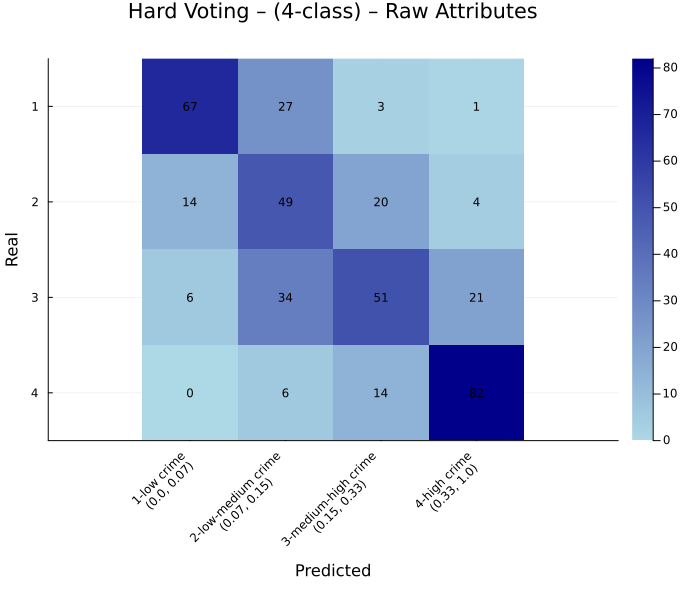

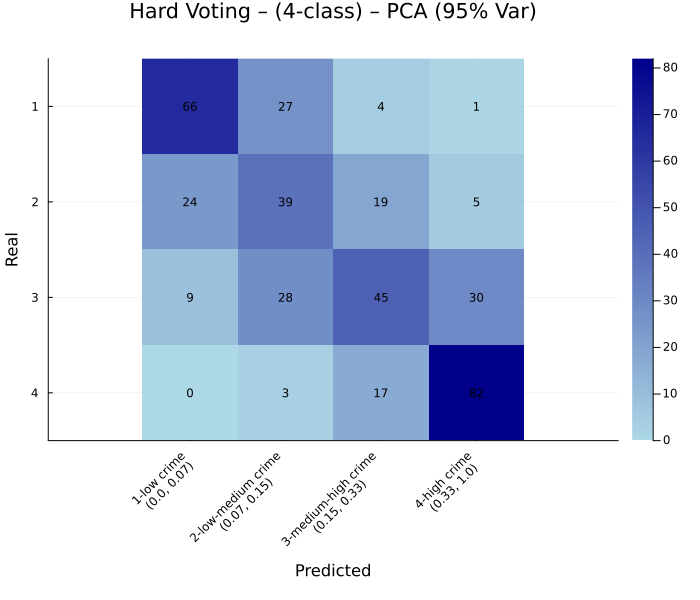

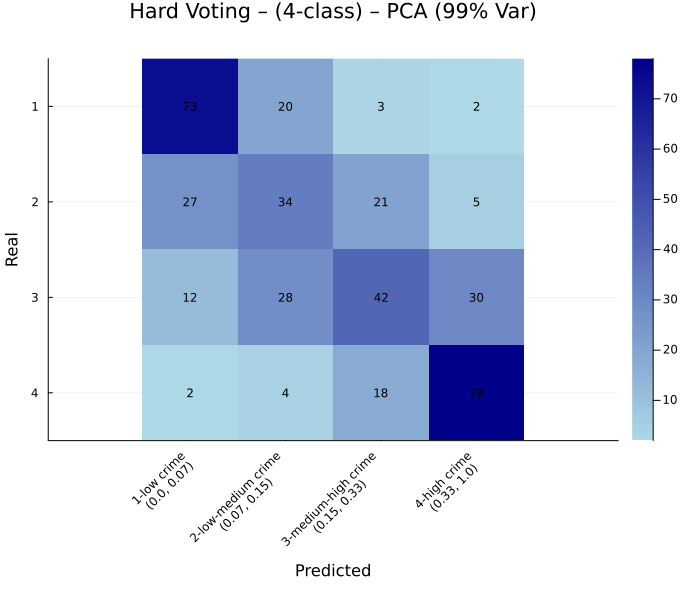

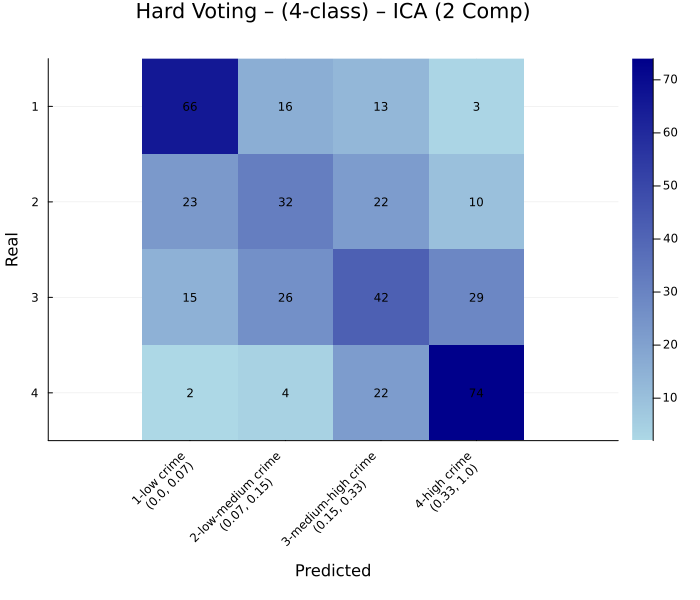

In [ ]:
# ---------------------------
# 1) Hard voting (4-class)
# ---------------------------
hard_voting_4_results = run_voting_ensembles(
    ensemble_specs_4,
    suites_4["Raw Attributes"].y,
    suites_4["Raw Attributes"].y_test;
    voting       = :hard,
    title_prefix = "4-class crime"
)

hard_4_save_dir = joinpath("ensembles", exp_name, "hard_voting")
hard_4_file_prefix = "hard_voting_4class"

plotEnsembleConfusionsIndividual(
    hard_voting_4_results,
    "Hard Voting – ($exp_name)";
    class_labels = class_labels_4,
    save_dir     = hard_4_save_dir,
    file_prefix  = hard_4_file_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [4-class crime] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.6240601503759399
Error Rate: 0.37593984962406013
Sensitivity (Recall): 0.6240601503759398
Specificity: 0.8780099366345895
Positive Predictive Value (Precision): 0.6372390949141354
Negative Predictive Value (Precision): 0.8736833966442137
F-score: 0.6262068465752643
Confusion Matrix:
[48 14 4 21; 27 67 1 3; 6 0 82 14; 33 6 21 52]

>>> [4-class crime] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.5664160401002506
Error Rate: 0.4335839598997494
Sensitivity (Recall): 0.5664160401002506
Specificity: 0.856417077287603
Positive Predictive Value (Precision): 0.5549474526563087
Negative Predictive Value (Precision): 0.856692265991488
F-score: 0.5565635941545328
Confusion Matrix:
[34 27 5 21; 20 72 3 3; 4 2 78 18; 28 12 30 42]

>>> [4-class crime] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.5363408521303258
Error Rate: 0.4636591478

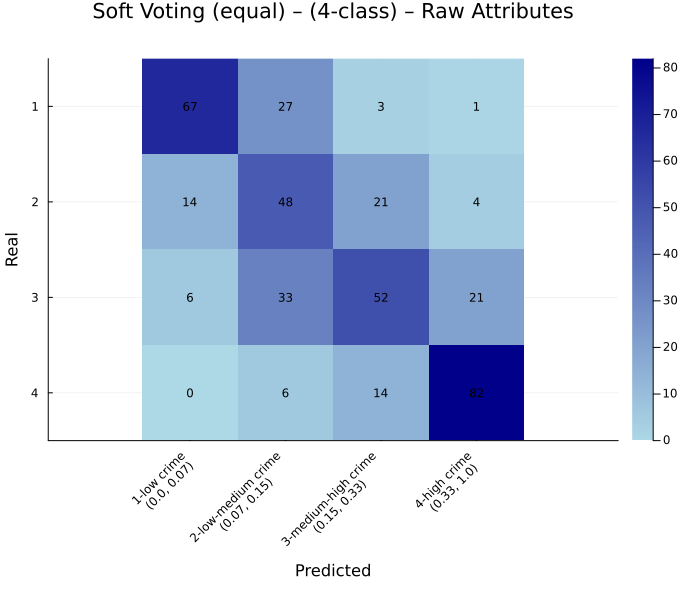

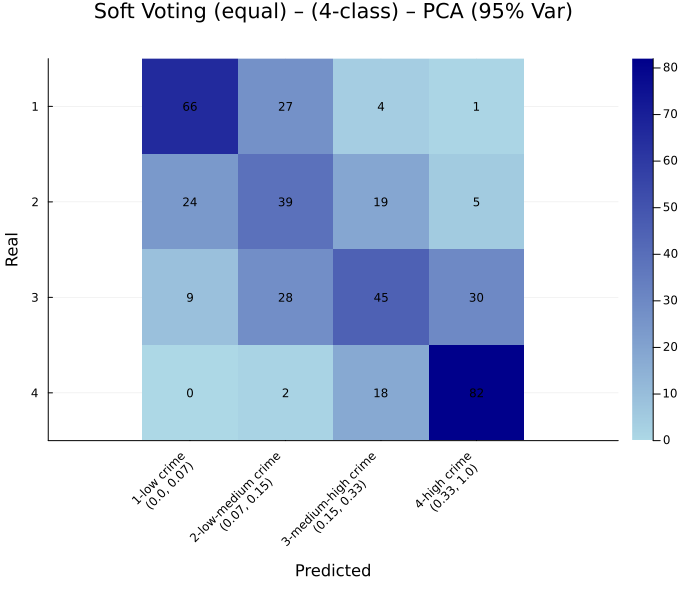

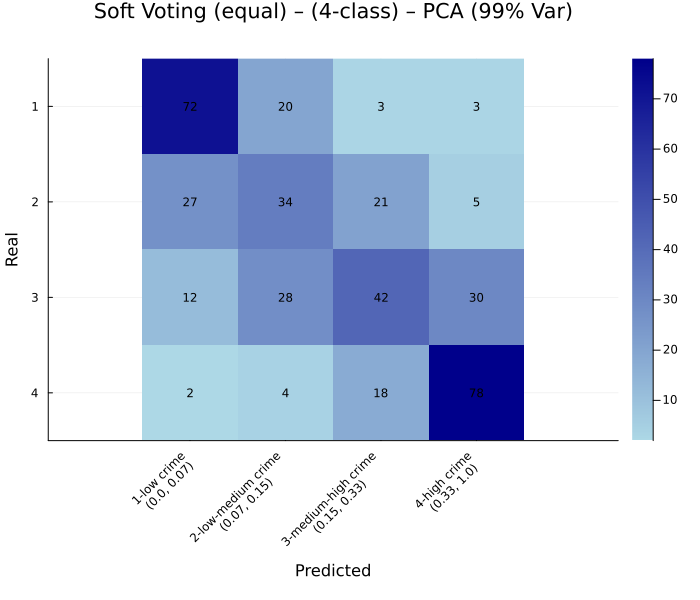

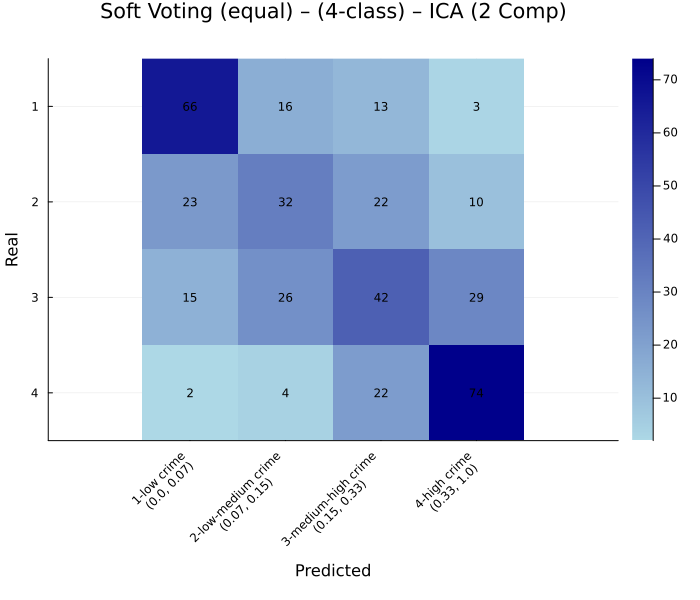

In [ ]:
soft_equal_4_results = run_voting_ensembles(
    ensemble_specs_4,
    train_output_binned,
    test_output_binned;
    voting       = :soft,
    weights      = nothing,
    title_prefix = "4-class crime"
)

soft_equal_4_dir    = joinpath("ensembles", exp_name, "soft_equal_voting")
soft_equal_4_prefix = "soft_equal_voting_4class"

plotEnsembleConfusionsIndividual(
    soft_equal_4_results,
    "Soft Voting (equal) – ($exp_name)";
    class_labels = class_labels_4,
    save_dir     = soft_equal_4_dir,
    file_prefix  = soft_equal_4_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [4-class crime] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.606516290726817
Error Rate: 0.393483709273183
Sensitivity (Recall): 0.606516290726817
Specificity: 0.8696402914989654
Positive Predictive Value (Precision): 0.6095877415077813
Negative Predictive Value (Precision): 0.8681681845445611
F-score: 0.6077968758615608
Confusion Matrix:
[38 21 4 24; 25 68 1 4; 4 0 78 20; 27 9 18 58]

>>> [4-class crime] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.5789473684210527
Error Rate: 0.42105263157894735
Sensitivity (Recall): 0.5789473684210527
Specificity: 0.8588284515867584
Positive Predictive Value (Precision): 0.5678262807838451
Negative Predictive Value (Precision): 0.8610570279416958
F-score: 0.5705374118292708
Confusion Matrix:
[29 30 5 23; 20 73 2 3; 2 2 76 22; 21 15 23 53]

>>> [4-class crime] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.543859649122807
Error Rate: 0.456140350877

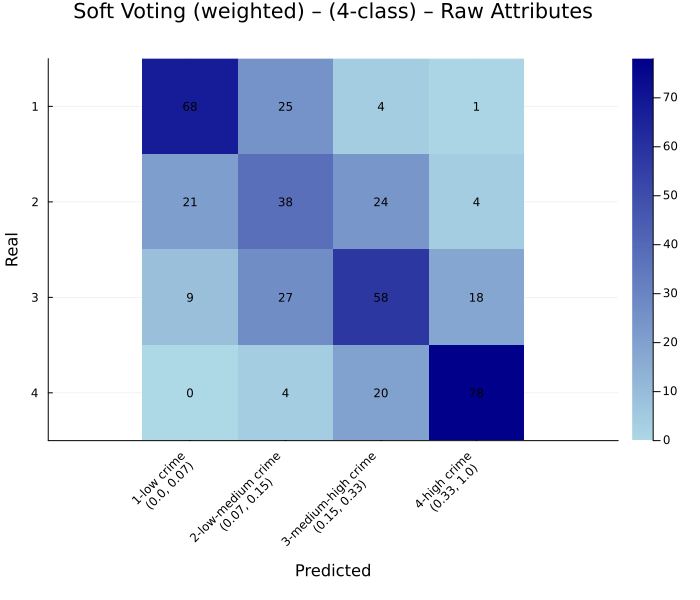

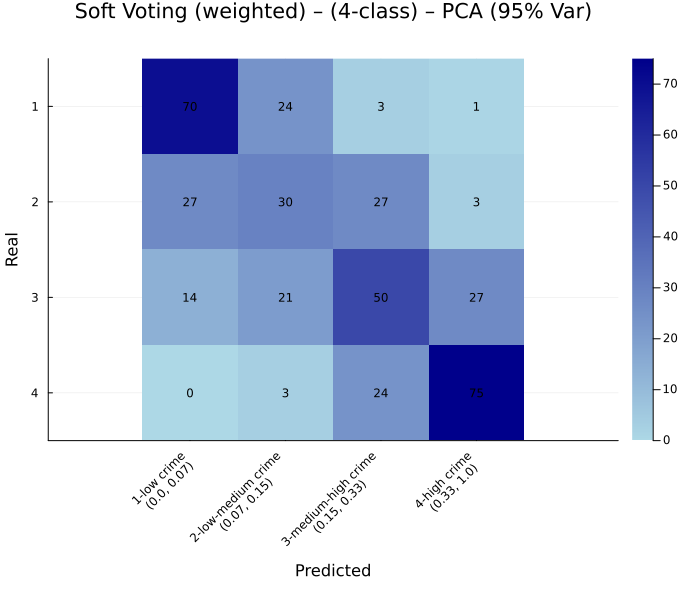

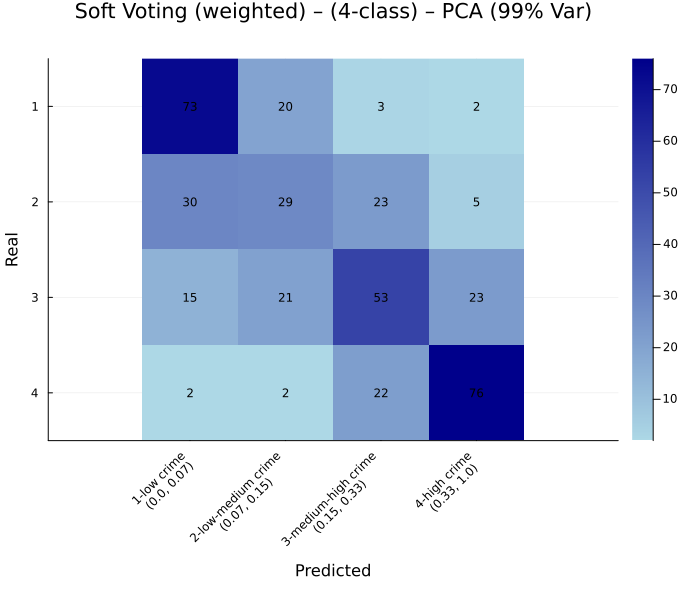

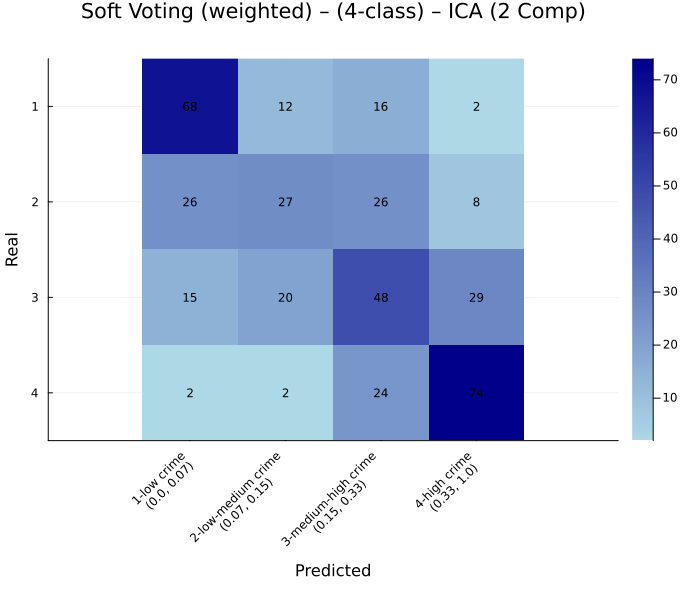

In [ ]:
soft_weighted_4_results = run_voting_ensembles(
    ensemble_specs_4,
    train_output_binned,
    test_output_binned;
    voting       = :soft,
    weights      = soft_weights_4,
    title_prefix = "4-class crime"
)

soft_weighted_4_dir    = joinpath("ensembles", exp_name, "soft_weighted_voting")
soft_weighted_4_prefix = "soft_weighted_voting_4class"

plotEnsembleConfusionsIndividual(
    soft_weighted_4_results,
    "Soft Voting (weighted) – ($exp_name)";
    class_labels = class_labels_4,
    save_dir     = soft_weighted_4_dir,
    file_prefix  = soft_weighted_4_prefix
)


STACKING ENSEMBLES – CLASSIFICATION

>>> [4-class crime] Representation: Raw Attributes
Weighted Metrics:
Accuracy: 0.6015037593984962
Error Rate: 0.3984962406015038
Sensitivity (Recall): 0.6015037593984962
Specificity: 0.8660714323684141
Positive Predictive Value (Precision): 0.5978923194369894
Negative Predictive Value (Precision): 0.8674601090739273
F-score: 0.5988789089641644
Confusion Matrix:
[32 27 26 2; 21 71 5 1; 21 11 61 19; 4 0 22 76]

>>> [4-class crime] Representation: PCA (99% Var)
Weighted Metrics:
Accuracy: 0.5889724310776943
Error Rate: 0.41102756892230574
Sensitivity (Recall): 0.5889724310776943
Specificity: 0.8630462021661233
Positive Predictive Value (Precision): 0.5892024318353437
Negative Predictive Value (Precision): 0.8617730576660412
F-score: 0.5886059184534671
Confusion Matrix:
[40 22 2 23; 27 67 1 3; 3 0 75 24; 22 15 22 53]

>>> [4-class crime] Representation: ICA (2 Comp)
Weighted Metrics:
Accuracy: 0.5213032581453634
Error Rate: 0.4786967418546366
Sensitivi

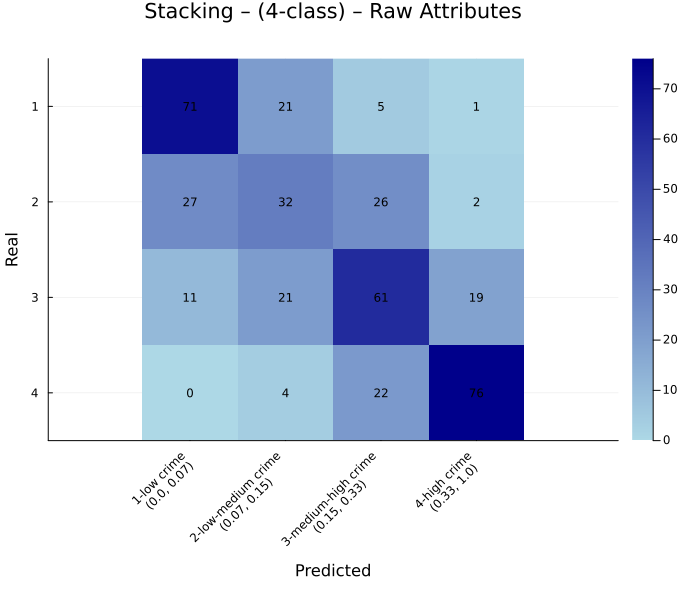

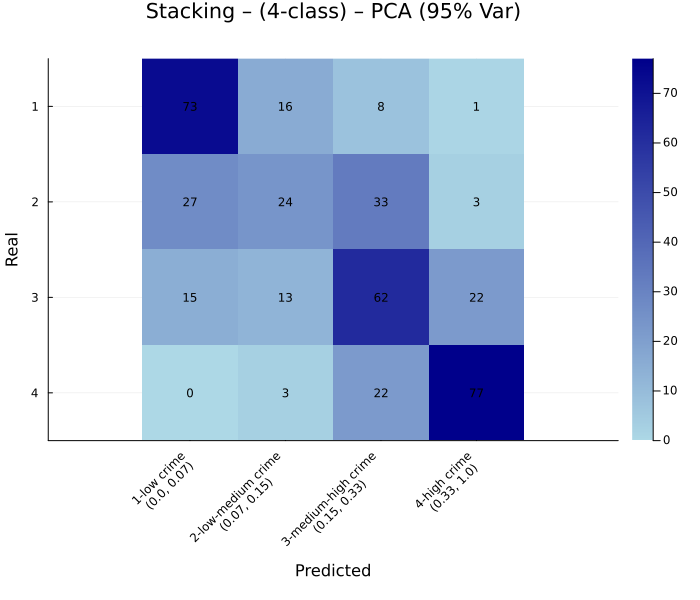

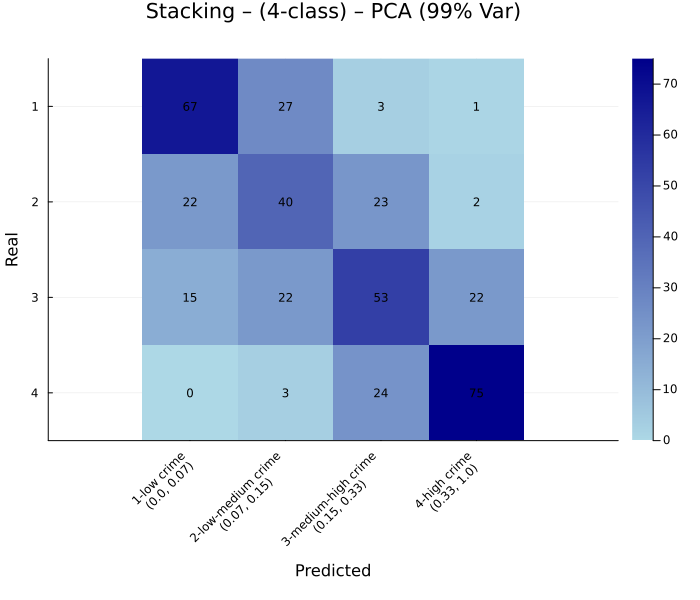

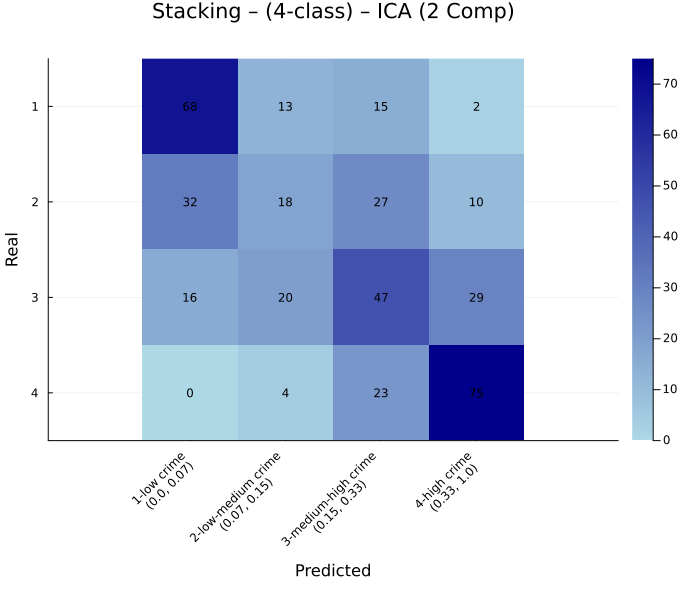

In [ ]:
stacking_4_results = Ensembles.run_stacking_ensembles(
    ensemble_specs_4,
    train_output_binned,
    test_output_binned;
    base_names   = (:ANN, :SVM, :DT, :KNN),
    title_prefix = "4-class crime"
)

stacking_4_dir    = joinpath("ensembles", exp_name, "stacking")
stacking_4_prefix = "stacking_4class"

plotEnsembleConfusionsIndividual(
    stacking_4_results,
    "Stacking – ($exp_name)";
    class_labels = class_labels_4,
    save_dir     = stacking_4_dir,
    file_prefix  = stacking_4_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [4-class crime (simple)] Dataset: Raw Attributes (voting=hard)
Weighted Metrics:
Accuracy: 0.6040100250626567
Error Rate: 0.39598997493734334
Sensitivity (Recall): 0.6040100250626566
Specificity: 0.8705823795496004
Positive Predictive Value (Precision): 0.6166428776303979
Negative Predictive Value (Precision): 0.8670563229731774
F-score: 0.6070317023221592
Confusion Matrix:
[45 18 4 20; 31 62 1 4; 5 0 79 18; 29 4 24 55]

>>> [4-class crime (simple)] Dataset: PCA (99% Var) (voting=hard)
Weighted Metrics:
Accuracy: 0.581453634085213
Error Rate: 0.418546365914787
Sensitivity (Recall): 0.581453634085213
Specificity: 0.8668792246276796
Positive Predictive Value (Precision): 0.6002286886682626
Negative Predictive Value (Precision): 0.8623243439753312
F-score: 0.5766763444182756
Confusion Matrix:
[45 21 5 16; 34 60 2 2; 9 0 86 7; 33 7 31 41]

>>> [4-class crime (simple)] Dataset: ICA (2 Comp) (voting=hard)
Weighted Metrics:
Accuracy: 0.5238095238095238


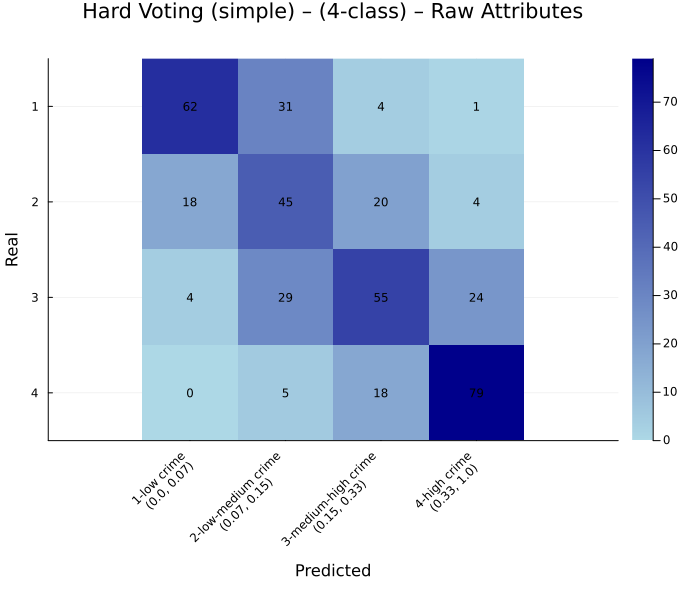

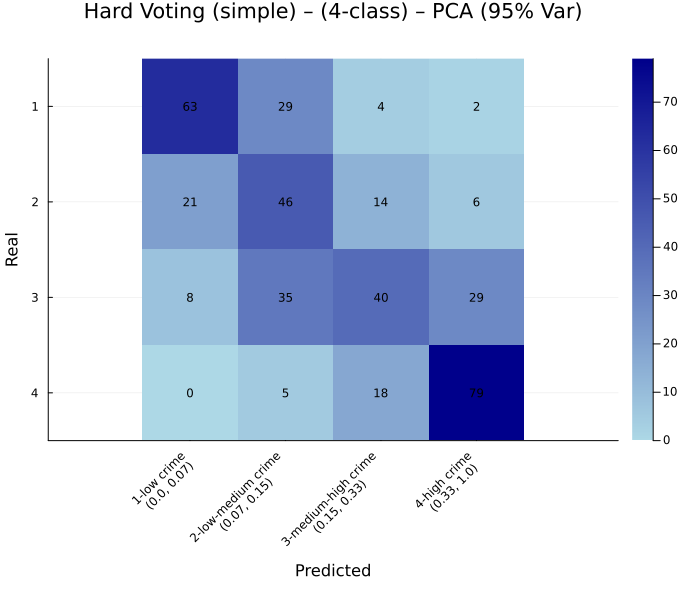

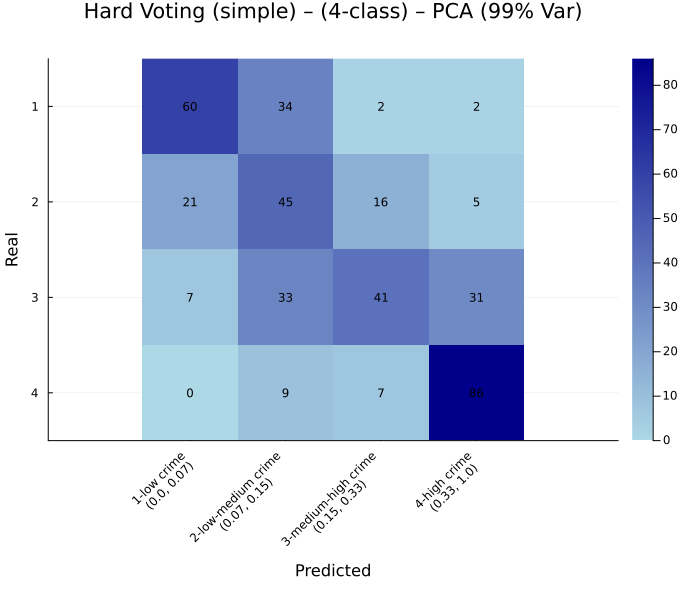

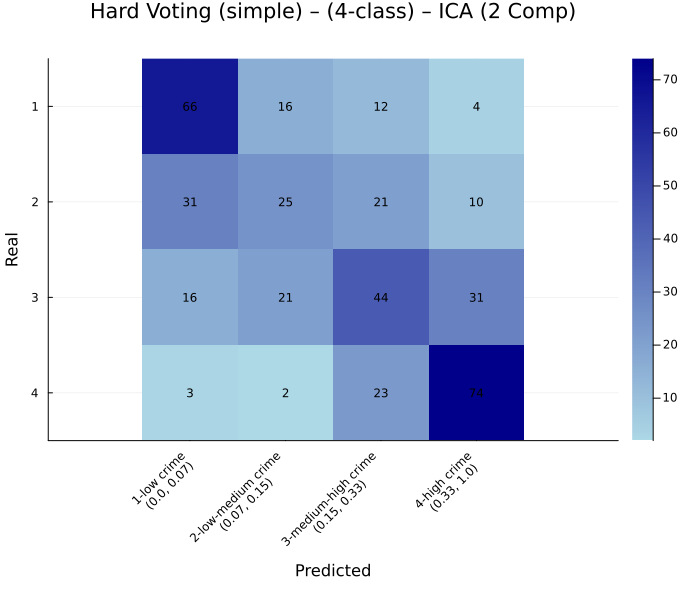

In [ ]:
simple_hard_voting_4_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned,
    test_output_binned;
    voting       = :hard,
    title_prefix = "4-class crime (simple)"
)

simple_hard_4_save_dir    = joinpath("ensembles", exp_name, "simple_hard_voting")
simple_hard_4_file_prefix = "simple_hard_voting_4class"

plotEnsembleConfusionsIndividual(
    simple_hard_voting_4_results,
    "Hard Voting (simple) – ($exp_name)";
    class_labels = class_labels_4,
    save_dir     = simple_hard_4_save_dir,
    file_prefix  = simple_hard_4_file_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [4-class crime (simple)] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.6040100250626567
Error Rate: 0.39598997493734334
Sensitivity (Recall): 0.6040100250626566
Specificity: 0.8705823795496004
Positive Predictive Value (Precision): 0.6166428776303979
Negative Predictive Value (Precision): 0.8670563229731774
F-score: 0.6070317023221592
Confusion Matrix:
[45 18 4 20; 31 62 1 4; 5 0 79 18; 29 4 24 55]

>>> [4-class crime (simple)] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.581453634085213
Error Rate: 0.418546365914787
Sensitivity (Recall): 0.581453634085213
Specificity: 0.8668792246276796
Positive Predictive Value (Precision): 0.6002286886682626
Negative Predictive Value (Precision): 0.8623243439753312
F-score: 0.5766763444182756
Confusion Matrix:
[45 21 5 16; 34 60 2 2; 9 0 86 7; 33 7 31 41]

>>> [4-class crime (simple)] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.5238095238095238


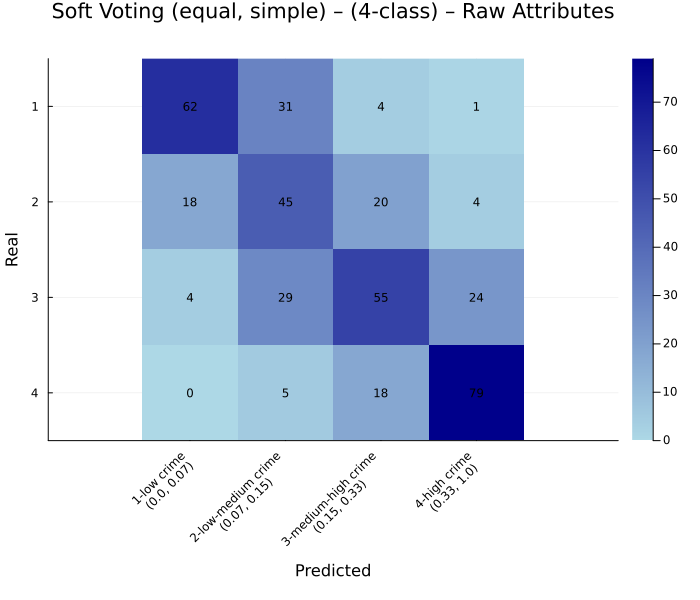

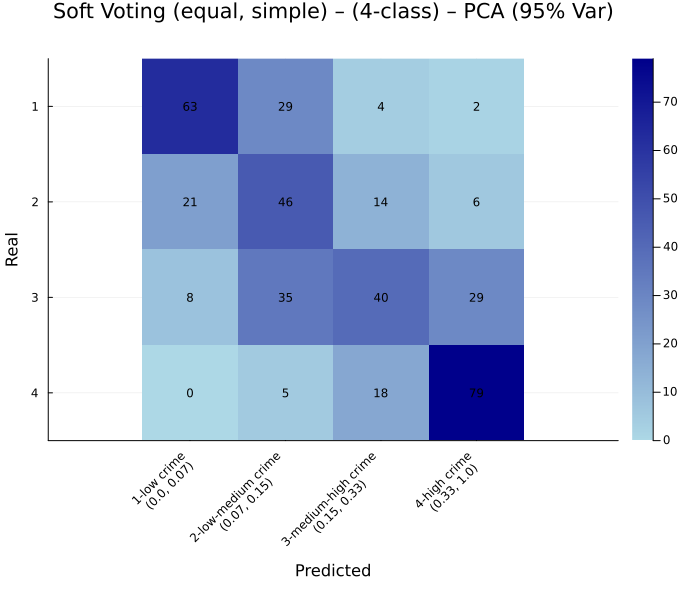

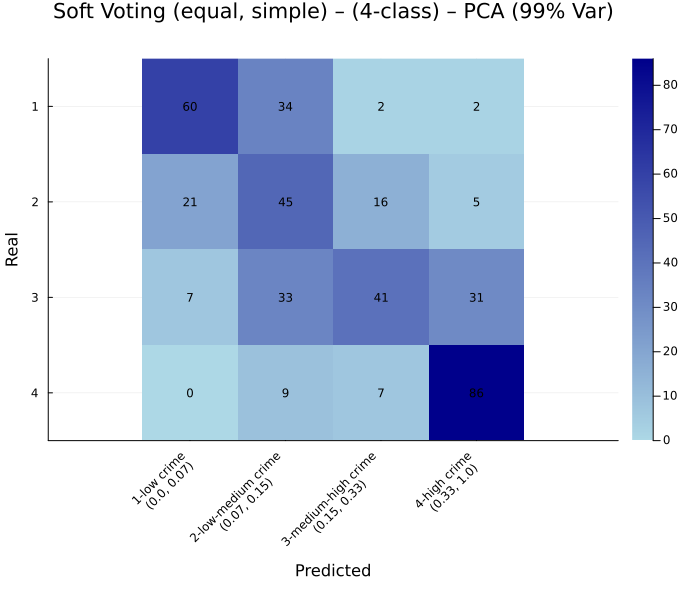

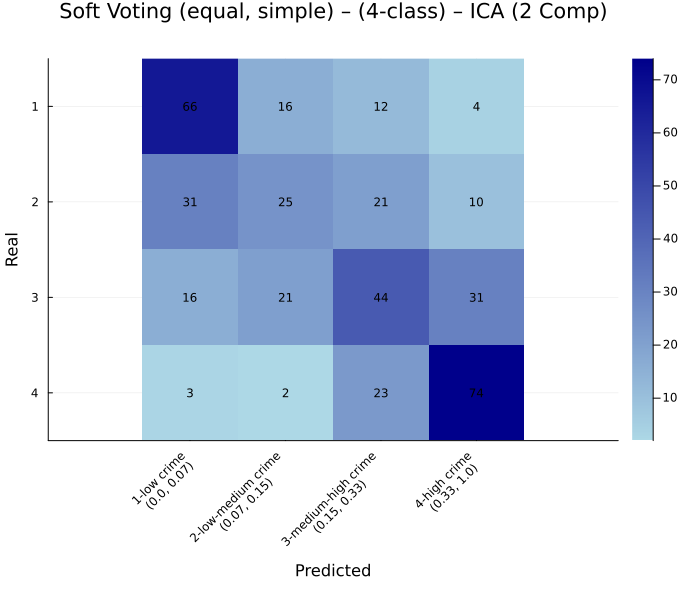

In [ ]:
simple_soft_equal_4_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned,
    test_output_binned;
    voting       = :soft,
    weights      = nothing,
    title_prefix = "4-class crime (simple)"
)

simple_soft_equal_4_dir    = joinpath("ensembles", exp_name, "simple_soft_equal_voting")
simple_soft_equal_4_prefix = "simple_soft_equal_voting_4class"

plotEnsembleConfusionsIndividual(
    simple_soft_equal_4_results,
    "Soft Voting (equal, simple) – ($exp_name)";
    class_labels = class_labels_4,
    save_dir     = simple_soft_equal_4_dir,
    file_prefix  = simple_soft_equal_4_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [4-class crime (simple)] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.5889724310776943
Error Rate: 0.41102756892230574
Sensitivity (Recall): 0.5889724310776943
Specificity: 0.8623533985096214
Positive Predictive Value (Precision): 0.5886789788798572
Negative Predictive Value (Precision): 0.8623919184969984
F-score: 0.5887141328431076
Confusion Matrix:
[35 25 4 23; 23 69 1 5; 5 0 72 25; 23 8 22 59]

>>> [4-class crime (simple)] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.5964912280701754
Error Rate: 0.4035087719298246
Sensitivity (Recall): 0.5964912280701754
Specificity: 0.8671698954746689
Positive Predictive Value (Precision): 0.5916376859145283
Negative Predictive Value (Precision): 0.8664931573985264
F-score: 0.5923075069933773
Confusion Matrix:
[33 27 4 23; 23 72 0 3; 7 0 80 15; 25 10 24 53]

>>> [4-class crime (simple)] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.523809523809

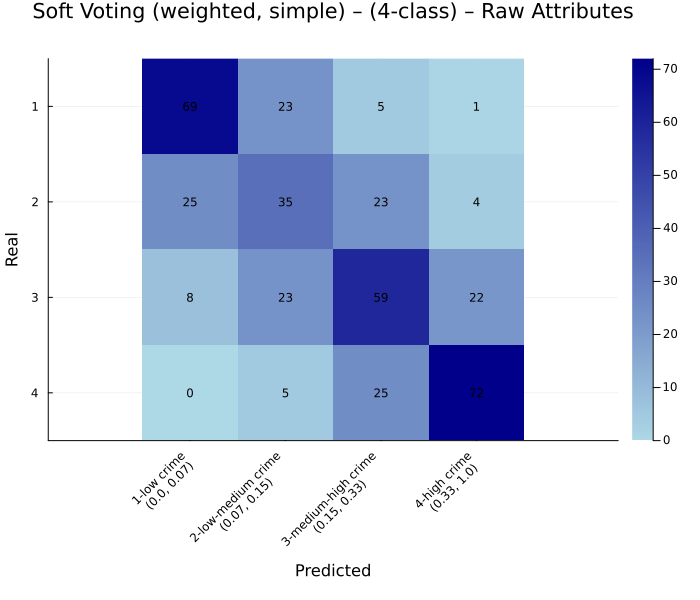

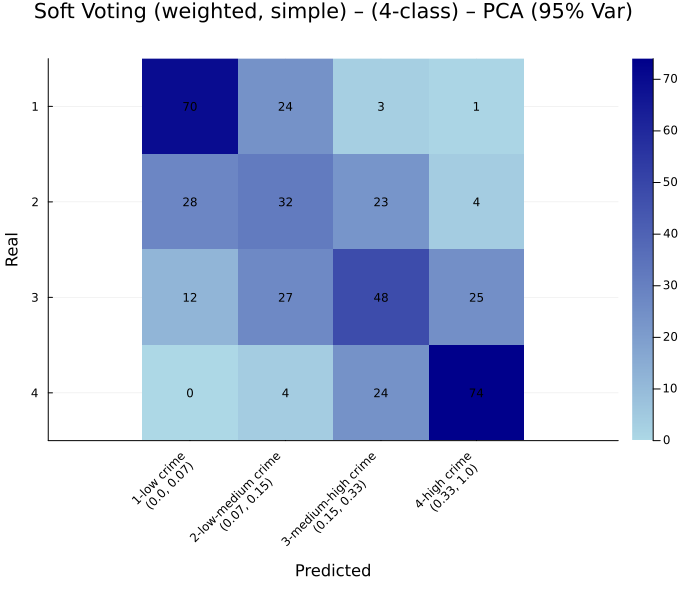

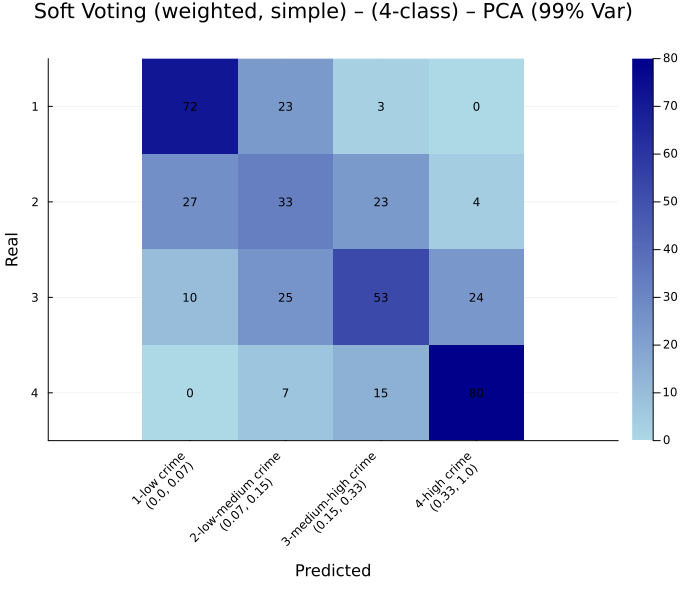

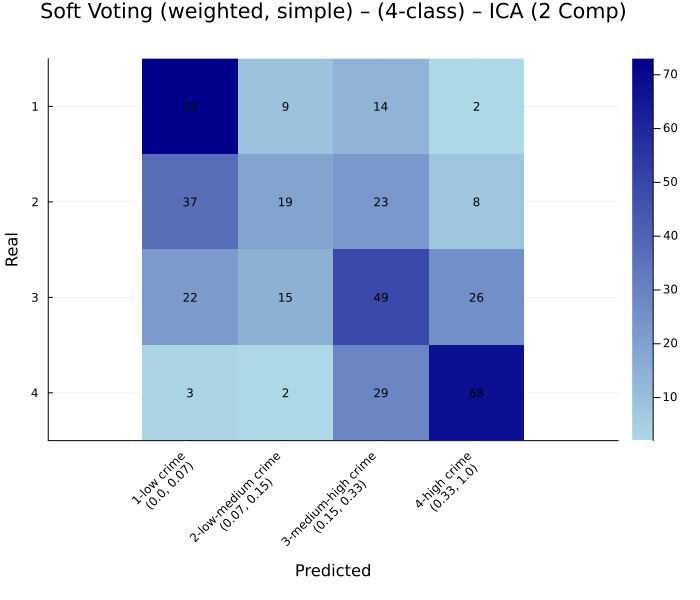

In [ ]:
simple_soft_weighted_4_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned,
    test_output_binned;
    voting       = :soft,
    weights      = soft_weights_4,
    title_prefix = "4-class crime (simple)"
)

simple_soft_weighted_4_dir    = joinpath("ensembles", exp_name, "simple_soft_weighted_voting")
simple_soft_weighted_4_prefix = "simple_soft_weighted_voting_4class"

plotEnsembleConfusionsIndividual(
    simple_soft_weighted_4_results,
    "Soft Voting (weighted, simple) – ($exp_name)";
    class_labels = class_labels_4,
    save_dir     = simple_soft_weighted_4_dir,
    file_prefix  = simple_soft_weighted_4_prefix
)


STACKING ENSEMBLES – CLASSIFICATION

>>> [4-class crime (simple)] Representation: Raw Attributes
Weighted Metrics:
Accuracy: 0.6115288220551378
Error Rate: 0.3884711779448622
Sensitivity (Recall): 0.6115288220551378
Specificity: 0.8719479803382839
Positive Predictive Value (Precision): 0.6165566908831164
Negative Predictive Value (Precision): 0.870175356461594
F-score: 0.6136629007537706
Confusion Matrix:
[38 24 3 22; 27 67 1 3; 4 0 78 20; 27 4 20 61]

>>> [4-class crime (simple)] Representation: PCA (99% Var)
Weighted Metrics:
Accuracy: 0.5789473684210527
Error Rate: 0.42105263157894735
Sensitivity (Recall): 0.5789473684210527
Specificity: 0.8589004657682449
Positive Predictive Value (Precision): 0.5686610594439847
Negative Predictive Value (Precision): 0.8603930734365516
F-score: 0.5714401460206786
Confusion Matrix:
[31 30 23 3; 18 76 4 0; 24 12 50 26; 4 1 23 74]

>>> [4-class crime (simple)] Representation: ICA (2 Comp)
Weighted Metrics:
Accuracy: 0.5238095238095238
Error Rate: 0.4

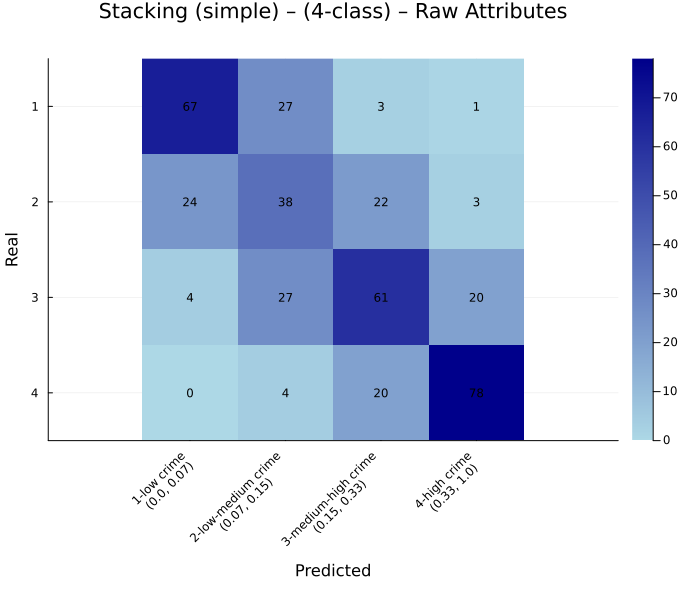

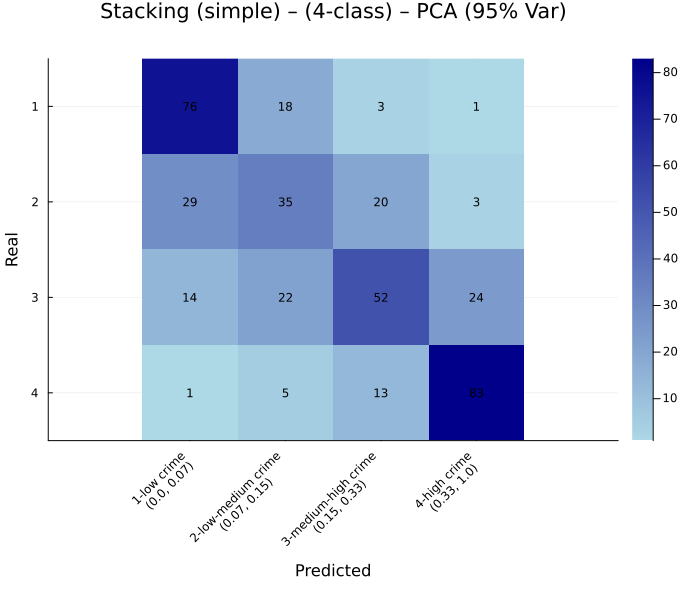

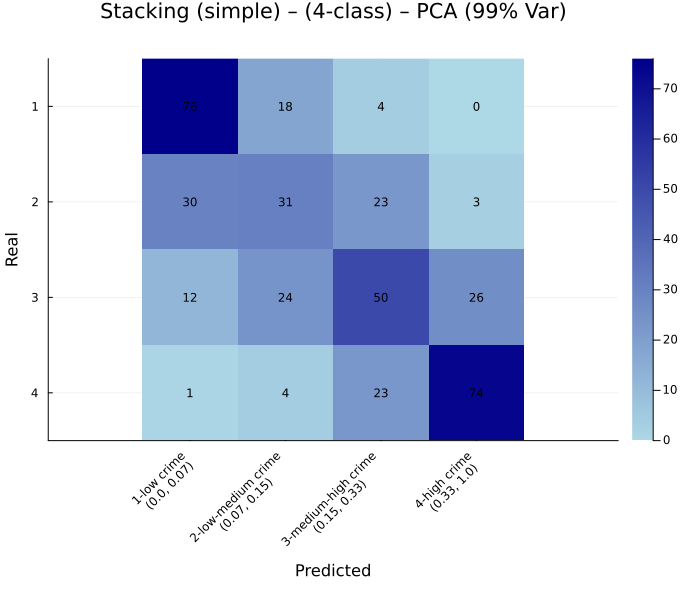

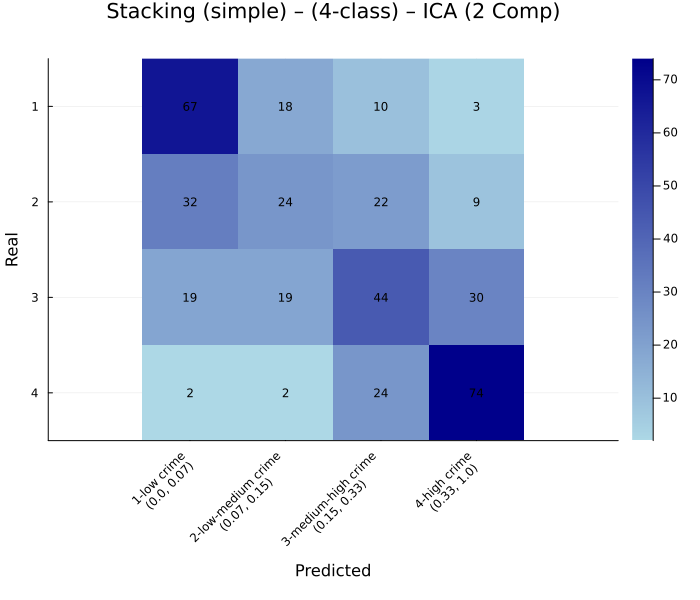

In [ ]:
simple_stacking_4_results = Ensembles.run_stacking_ensembles(
    simple_ensemble_specs,
    train_output_binned,
    test_output_binned;
    base_names   = (:ANN, :SVM, :DT, :KNN),
    title_prefix = "4-class crime (simple)"
)

simple_stacking_4_dir    = joinpath("ensembles", exp_name, "simple_stacking")
simple_stacking_4_prefix = "simple_stacking_4class"

plotEnsembleConfusionsIndividual(
    simple_stacking_4_results,
    "Stacking (simple) – ($exp_name)";
    class_labels = class_labels_4,
    save_dir     = simple_stacking_4_dir,
    file_prefix  = simple_stacking_4_prefix
)

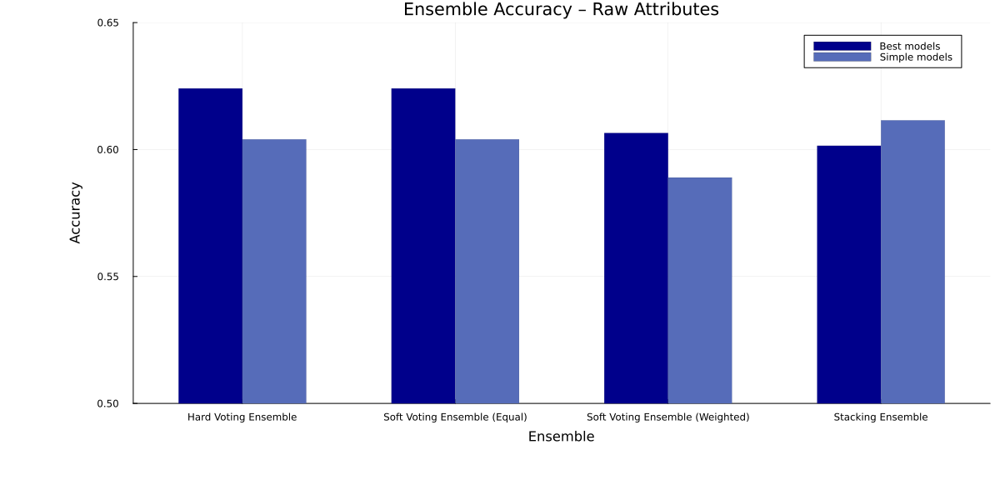

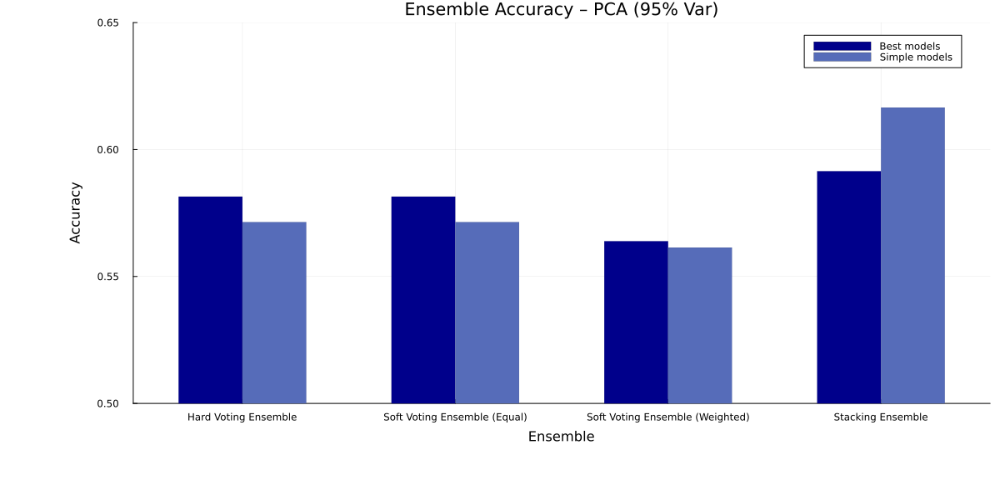

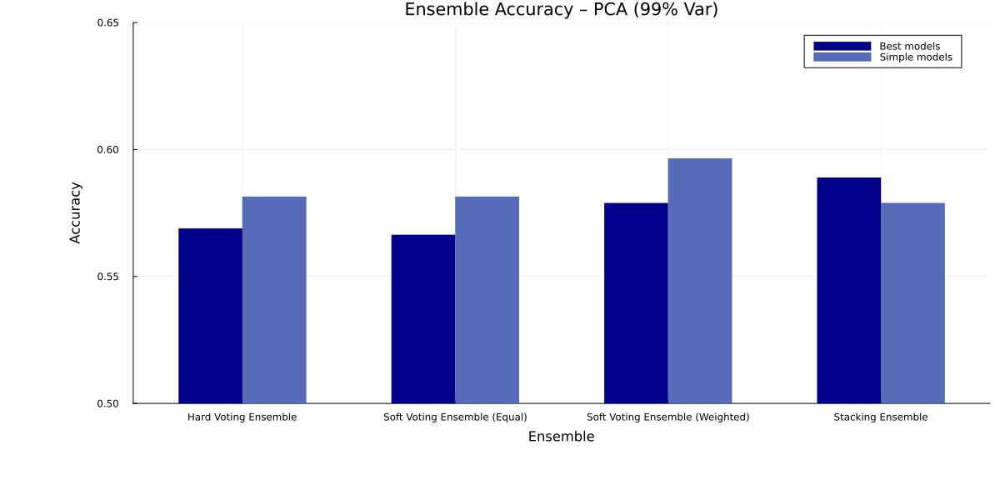

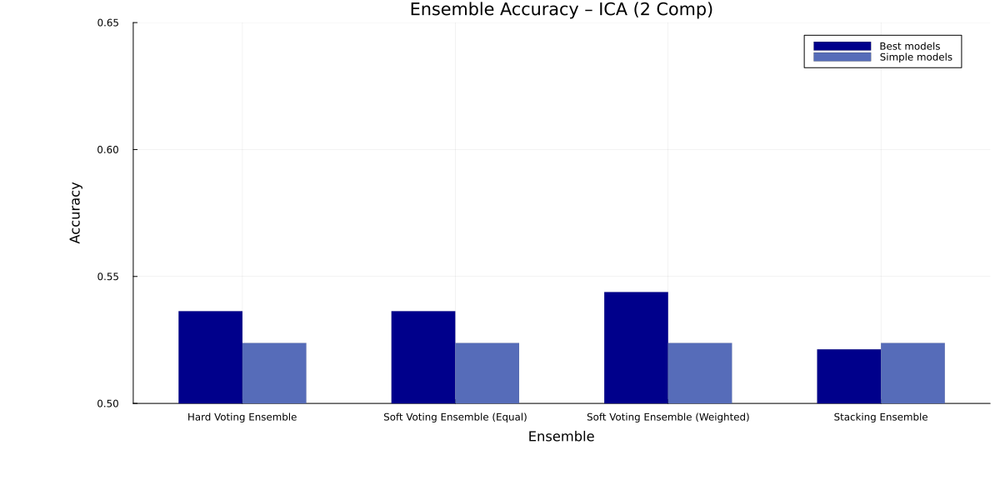

In [ ]:
data_to_plot_ensembles_4 = [
    (
        ds_name,
        [
            ("Hard Voting Ensemble",
                hard_voting_4_results[ds_name][1],
                hard_voting_4_results[ds_name][2]),
            ("Soft Voting Ensemble (Equal)",
                soft_equal_4_results[ds_name][1],
                soft_equal_4_results[ds_name][2]),
            ("Soft Voting Ensemble (Weighted)",
                soft_weighted_4_results[ds_name][1],
                soft_weighted_4_results[ds_name][2]),
            ("Stacking Ensemble",
                stacking_4_results[ds_name][1],
                stacking_4_results[ds_name][2])
        ]
    )
    for ds_name in ordered_datasets
]

data_to_plot_ensembles_4_simple = [
    (
        ds_name,
        [
            ("Hard Voting Ensemble",
                simple_hard_voting_4_results[ds_name][1],
                simple_hard_voting_4_results[ds_name][2]),
            ("Soft Voting Ensemble (Equal)",
                simple_soft_equal_4_results[ds_name][1],
                simple_soft_equal_4_results[ds_name][2]),
            ("Soft Voting Ensemble (Weighted)",
                simple_soft_weighted_4_results[ds_name][1],
                simple_soft_weighted_4_results[ds_name][2]),
            ("Stacking Ensemble",
                simple_stacking_4_results[ds_name][1],
                simple_stacking_4_results[ds_name][2])
        ]
    )
    for ds_name in ordered_datasets
]


plotEnsembleAccuracyBestVsSimple(
    data_to_plot_ensembles_4,
    data_to_plot_ensembles_4_simple;
    folder_name   = "ensembles/4-class/accuracy_best_vs_simple",
    base_filename = "accuracy_4class_best_vs_simple",
    size          = (1200, 600),
    ylims         = (0.5, 0.65) 
)


In [ ]:
class_labels_3 = ["1-low crime \n(0.0, 0.09)", "2- medium crime \n(0.09, 0.25)", "3- high crime \n(0.25, 1.0)"]

exp_name = "3-class"

soft_weights_3 = [1.5, 2, 1.3, 1.7]

ensemble_specs_3 = Dict([
    name => (
        X_train = experiment.X,
        X_test  = experiment.x_test,
        models  = [
            model
            for names, model in experiment.best_machines 
        ]
    )
    for name, experiment in suites_3
])

# ensemble_specs_3 = Dict(
#     "Raw Attributes" => (
#         X_train = train_input,
#         X_test  = test_input,
#         models  = [
#             best_ann_3_class_model,
#             best_svm_3_class_model,
#             best_dt_3_class_model,
#             best_knn_3_class_model
#         ]
#     ),
#     "PCA (95% Var)" => (
#         X_train = pca_train,
#         X_test  = pca_test,
#         models  = [
#             best_ann_3_class_model_95,
#             best_svm_3_class_model_95,
#             best_dt_3_class_model_95,
#             best_knn_3_class_model_95
#         ]
#     ),
#     "PCA (99% Var)" => (
#         X_train = pca_train_99,
#         X_test  = pca_test_99,
#         models  = [
#             best_ann_3_class_model_99,
#             best_svm_3_class_model_99,
#             best_dt_3_class_model_99,
#             best_knn_3_class_model_99
#         ]
#     ),
#     "ICA (2 Comp)" => (
#         X_train = ica_train,
#         X_test  = ica_test,
#         models  = [
#             best_ann_3_class_model_ica,
#             best_svm_3_class_model_ica,
#             best_dt_3_class_model_ica,
#             best_knn_3_class_model_ica
#         ]
#     ),
#     ,
#     "Filtered by Correlation" => (
#         X_train = train_corr,
#         X_test  = test_corr,
#         models  = [
#             best_ann_3_model_corr,
#             best_svm_3_model_corr,
#             best_dt_3_model_corr,
#             best_knn_3_model_corr
#         ]
#     )
# )


Dict{String, @NamedTuple{X_train::Matrix{Float64}, X_test::Matrix{Float64}, models::Vector{Probabilistic}}} with 4 entries:
  "Raw Attributes" => (X_train = [0.02 0.56 … 0.02 0.0; 0.04 0.35 … 0.05 0.0; ……
  "PCA (99% Var)"  => (X_train = [-0.524125 -0.192786 … -0.0400254 -0.052233; -…
  "ICA (2 Comp)"   => (X_train = [-0.315278 0.45694; 0.308958 0.260741; … ; -0.…
  "PCA (95% Var)"  => (X_train = [-0.524125 -0.192786 … 0.075712 0.156021; -0.2…


VOTING ENSEMBLES – CLASSIFICATION

>>> [3-class crime] Dataset: Raw Attributes (voting=hard)
Weighted Metrics:
Accuracy: 0.6842105263157895
Error Rate: 0.3157894736842105
Sensitivity (Recall): 0.6842105263157894
Specificity: 0.845659801231557
Positive Predictive Value (Precision): 0.7245657228400972
Negative Predictive Value (Precision): 0.8418155514870707
F-score: 0.6925812484823458
Confusion Matrix:
[95 21 14; 45 77 2; 43 1 101]

>>> [3-class crime] Dataset: PCA (99% Var) (voting=hard)
Weighted Metrics:
Accuracy: 0.6666666666666666
Error Rate: 0.33333333333333337
Sensitivity (Recall): 0.6666666666666666
Specificity: 0.8373338336087509
Positive Predictive Value (Precision): 0.6931979099253802
Negative Predictive Value (Precision): 0.831820184042277
F-score: 0.674322275470552
Confusion Matrix:
[80 42 2; 29 84 17; 3 40 102]

>>> [3-class crime] Dataset: ICA (2 Comp) (voting=hard)
Weighted Metrics:
Accuracy: 0.6365914786967418
Error Rate: 0.3634085213032582
Sensitivity (Recall): 0.63659

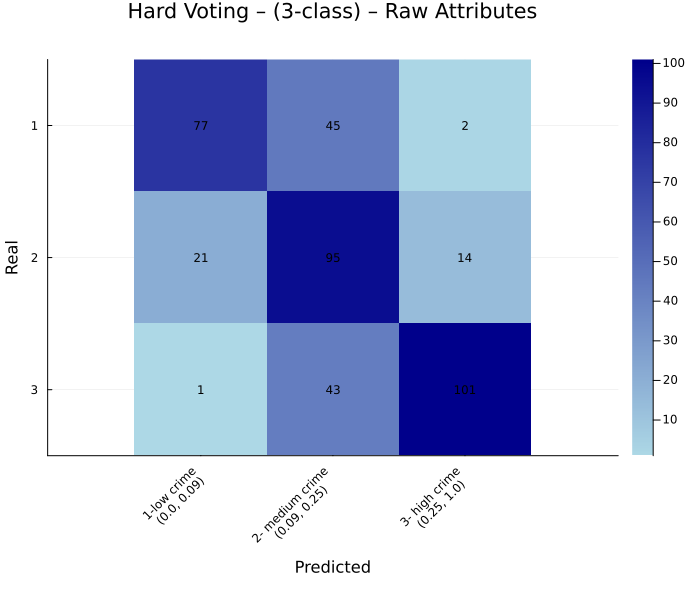

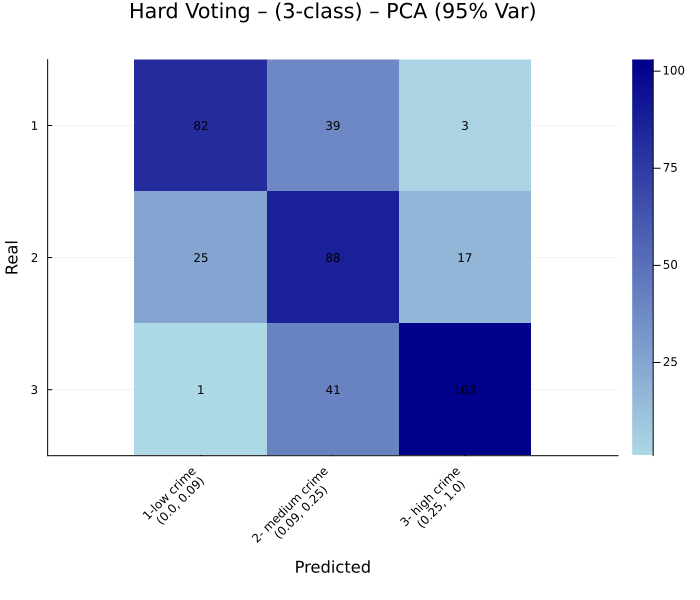

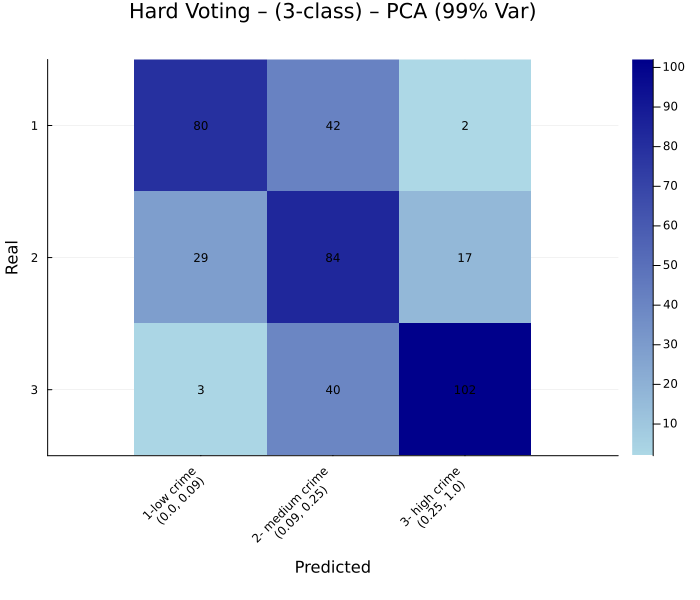

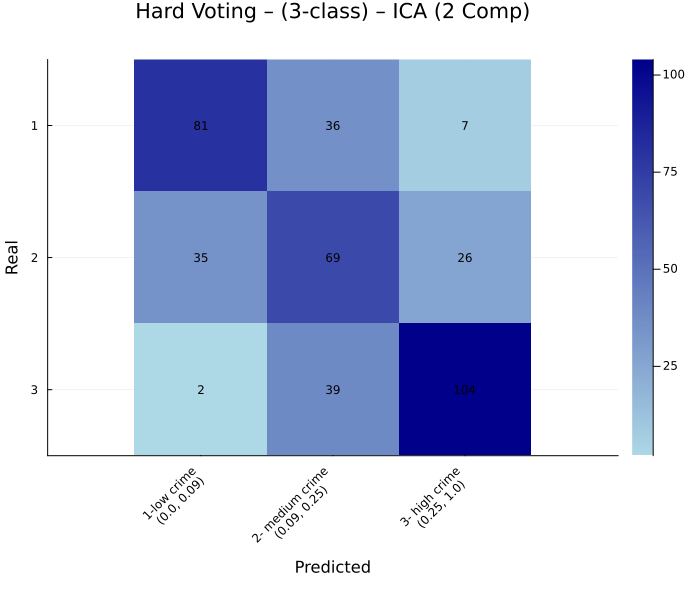

In [ ]:


hard_voting_3_results = run_voting_ensembles(
    ensemble_specs_3,
    suites_3["Raw Attributes"].y,
    suites_3["Raw Attributes"].y_test;
    voting       = :hard,
    title_prefix = "3-class crime"
)

hard_3_save_dir    = joinpath("ensembles", exp_name, "hard_voting")
hard_3_file_prefix = "hard_voting_3class"

plotEnsembleConfusionsIndividual(
    hard_voting_3_results,
    "Hard Voting – ($exp_name)";
    class_labels = class_labels_3,
    save_dir     = hard_3_save_dir,
    file_prefix  = hard_3_file_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [3-class crime] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.6842105263157895
Error Rate: 0.3157894736842105
Sensitivity (Recall): 0.6842105263157894
Specificity: 0.845659801231557
Positive Predictive Value (Precision): 0.7245657228400972
Negative Predictive Value (Precision): 0.8418155514870707
F-score: 0.6925812484823458
Confusion Matrix:
[95 21 14; 45 77 2; 43 1 101]

>>> [3-class crime] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.6666666666666666
Error Rate: 0.33333333333333337
Sensitivity (Recall): 0.6666666666666666
Specificity: 0.8373338336087509
Positive Predictive Value (Precision): 0.6931979099253802
Negative Predictive Value (Precision): 0.831820184042277
F-score: 0.674322275470552
Confusion Matrix:
[80 42 2; 29 84 17; 3 40 102]

>>> [3-class crime] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.6365914786967418
Error Rate: 0.3634085213032582
Sensitivity (Recall): 0.63659

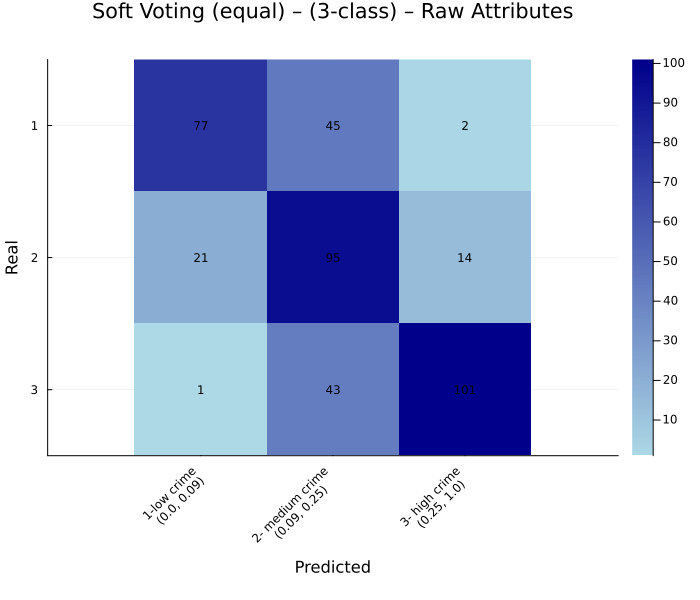

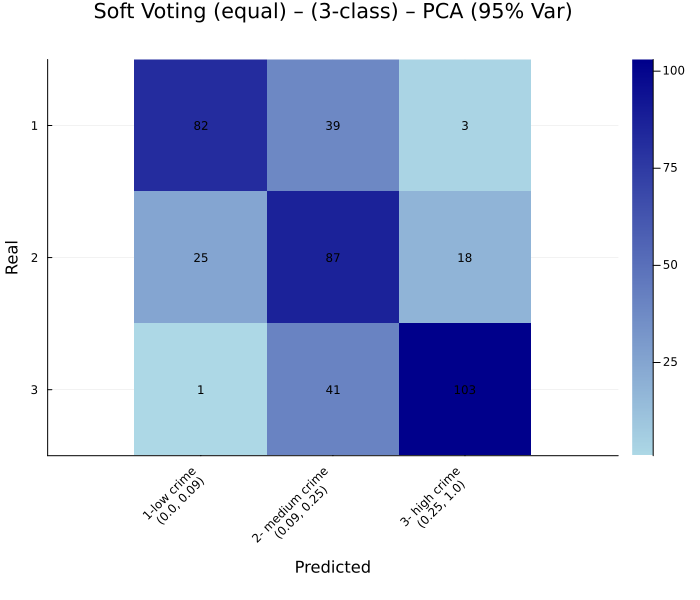

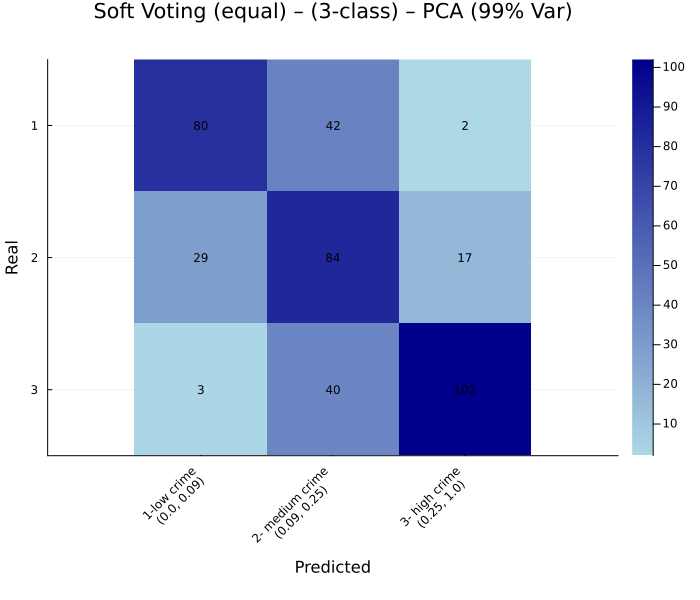

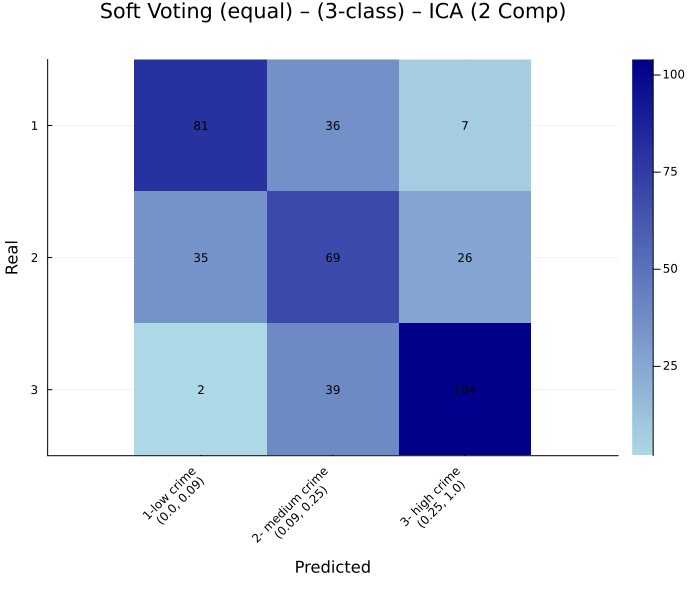

In [ ]:
soft_equal_3_results = run_voting_ensembles(
    ensemble_specs_3,
    train_output_binned_3,
    test_output_binned_3;
    voting       = :soft,
    weights      = nothing,
    title_prefix = "3-class crime"
)

soft_equal_3_dir    = joinpath("ensembles", exp_name, "soft_equal_voting")
soft_equal_3_prefix = "soft_equal_voting_3class"

plotEnsembleConfusionsIndividual(
    soft_equal_3_results,
    "Soft Voting (equal) – ($exp_name)";
    class_labels = class_labels_3,
    save_dir     = soft_equal_3_dir,
    file_prefix  = soft_equal_3_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [3-class crime] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.6992481203007519
Error Rate: 0.3007518796992481
Sensitivity (Recall): 0.6992481203007518
Specificity: 0.8530795175211341
Positive Predictive Value (Precision): 0.7145836260404438
Negative Predictive Value (Precision): 0.8486602781681613
F-score: 0.7045175236575724
Confusion Matrix:
[87 2 35; 2 109 34; 30 17 83]

>>> [3-class crime] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.6942355889724311
Error Rate: 0.3057644110275689
Sensitivity (Recall): 0.694235588972431
Specificity: 0.8495832155289832
Positive Predictive Value (Precision): 0.6997729183100468
Negative Predictive Value (Precision): 0.8466849839888635
F-score: 0.6963784672391091
Confusion Matrix:
[93 2 29; 3 109 33; 32 23 75]

>>> [3-class crime] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.6491228070175439
Error Rate: 0.3508771929824561
Sensitivity (Recall): 0.6491

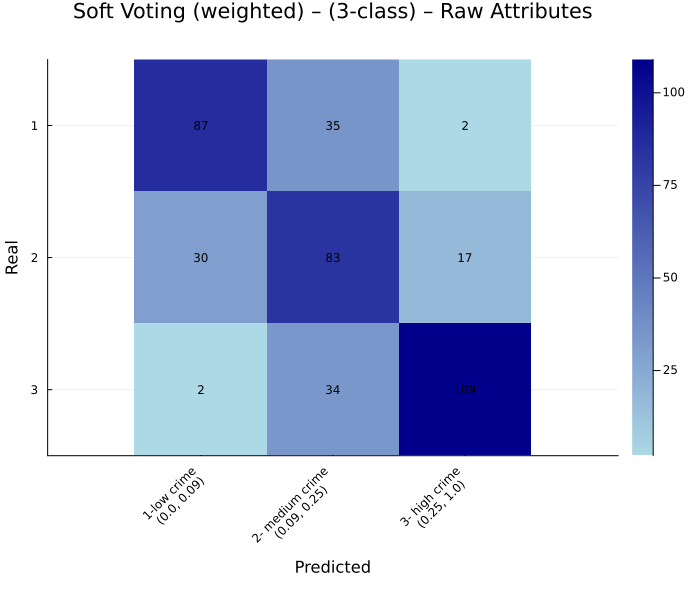

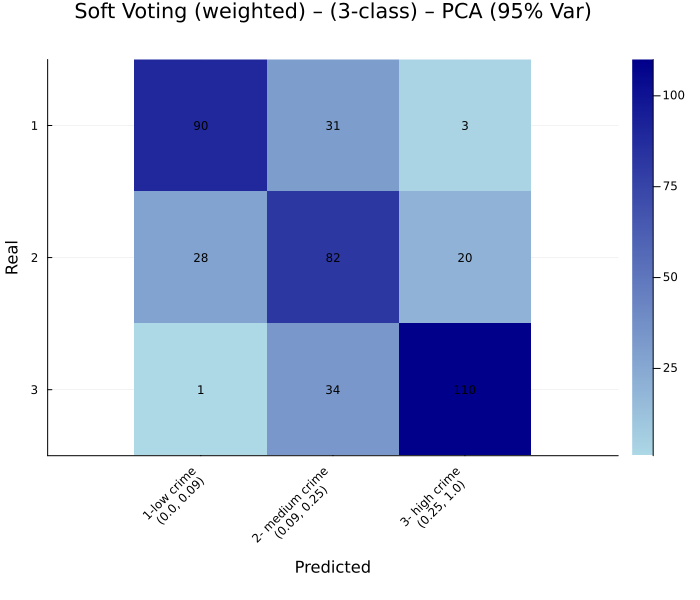

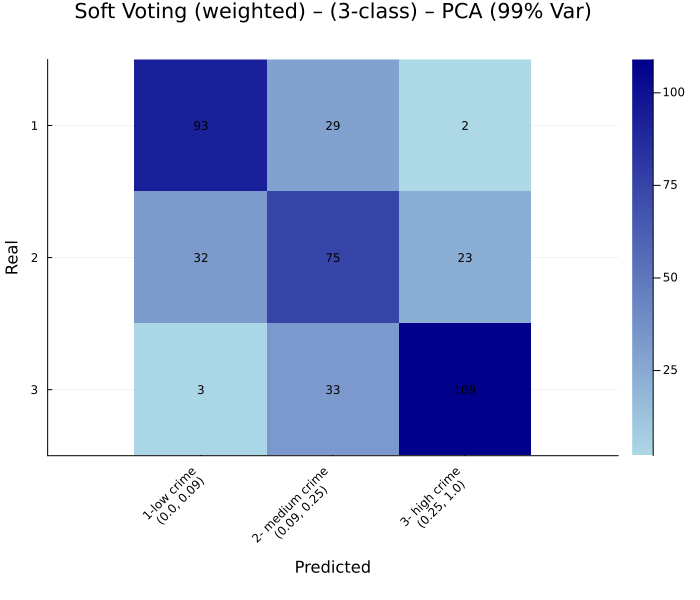

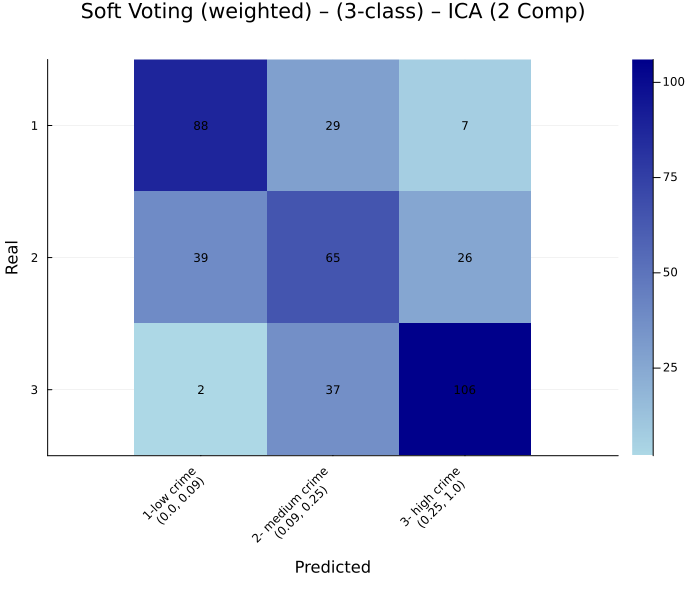

In [ ]:
soft_weighted_3_results = run_voting_ensembles(
    ensemble_specs_3,
    train_output_binned_3,
    test_output_binned_3;
    voting       = :soft,
    weights      = soft_weights_3,
    title_prefix = "3-class crime"
)

soft_weighted_3_dir    = joinpath("ensembles", exp_name, "soft_weighted_voting")
soft_weighted_3_prefix = "soft_weighted_voting_3class"

plotEnsembleConfusionsIndividual(
    soft_weighted_3_results,
    "Soft Voting (weighted) – ($exp_name)";
    class_labels = class_labels_3,
    save_dir     = soft_weighted_3_dir,
    file_prefix  = soft_weighted_3_prefix
)


STACKING ENSEMBLES – CLASSIFICATION

>>> [3-class crime] Representation: Raw Attributes
Weighted Metrics:
Accuracy: 0.6867167919799498
Error Rate: 0.31328320802005016
Sensitivity (Recall): 0.6867167919799498
Specificity: 0.8461453422269141
Positive Predictive Value (Precision): 0.6995894991761515
Negative Predictive Value (Precision): 0.8418623258965481
F-score: 0.6914063374103778
Confusion Matrix:
[90 2 32; 1 106 38; 31 21 78]

>>> [3-class crime] Representation: PCA (99% Var)
Weighted Metrics:
Accuracy: 0.706766917293233
Error Rate: 0.29323308270676696
Sensitivity (Recall): 0.706766917293233
Specificity: 0.8544939896422339
Positive Predictive Value (Precision): 0.7101165445195288
Negative Predictive Value (Precision): 0.8534945642164653
F-score: 0.7082804073399027
Confusion Matrix:
[76 28 26; 30 92 2; 30 1 114]

>>> [3-class crime] Representation: ICA (2 Comp)
Weighted Metrics:
Accuracy: 0.6416040100250626
Error Rate: 0.3583959899749374
Sensitivity (Recall): 0.6416040100250626
Speci

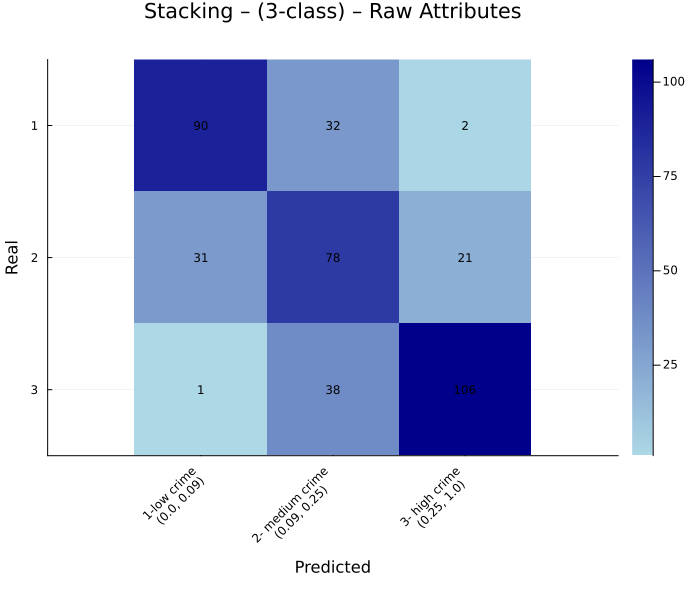

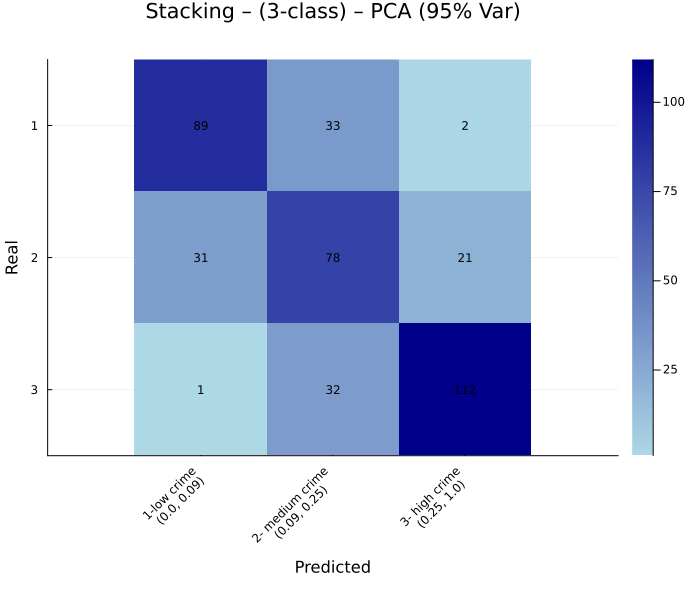

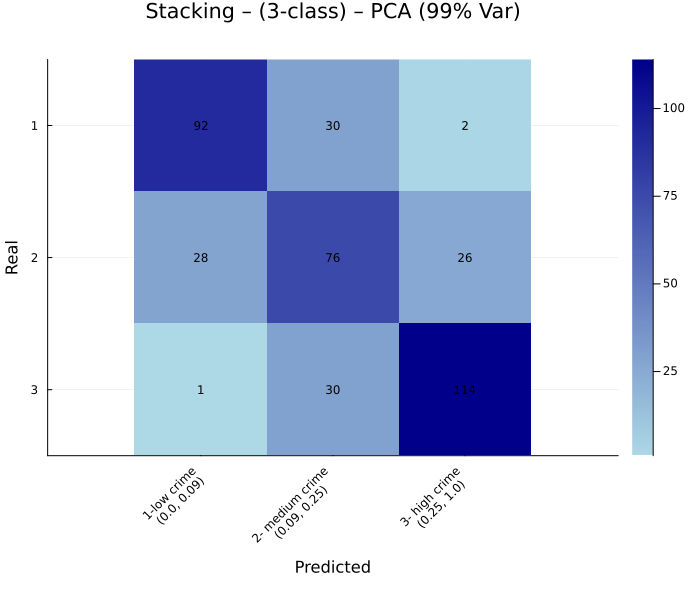

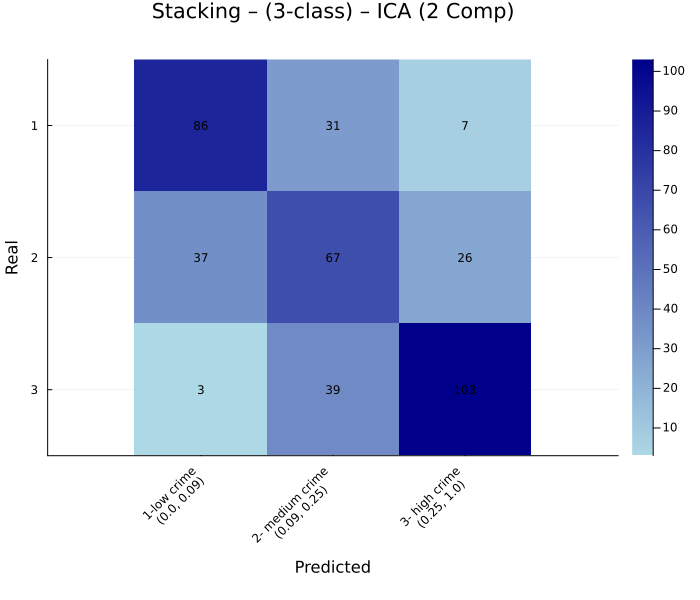

In [ ]:
stacking_3_results = Ensembles.run_stacking_ensembles(
    ensemble_specs_3,
    train_output_binned_3,
    test_output_binned_3;
    base_names   = (:ANN, :SVM, :DT, :KNN),
    title_prefix = "3-class crime"
)

stacking_3_dir    = joinpath("ensembles", exp_name, "stacking")
stacking_3_prefix = "stacking_3class"

plotEnsembleConfusionsIndividual(
    stacking_3_results,
    "Stacking – ($exp_name)";
    class_labels = class_labels_3,
    save_dir     = stacking_3_dir,
    file_prefix  = stacking_3_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [3-class crime (simple)] Dataset: Raw Attributes (voting=hard)
Weighted Metrics:
Accuracy: 0.6867167919799498
Error Rate: 0.31328320802005016
Sensitivity (Recall): 0.6867167919799497
Specificity: 0.846016654358859
Positive Predictive Value (Precision): 0.7121195777822096
Negative Predictive Value (Precision): 0.8415029595731089
F-score: 0.6939036000855034
Confusion Matrix:
[87 24 19; 38 84 2; 41 1 103]

>>> [3-class crime (simple)] Dataset: PCA (99% Var) (voting=hard)
Weighted Metrics:
Accuracy: 0.6766917293233082
Error Rate: 0.32330827067669177
Sensitivity (Recall): 0.6766917293233082
Specificity: 0.840246106133978
Positive Predictive Value (Precision): 0.7113763235820405
Negative Predictive Value (Precision): 0.8383307184634334
F-score: 0.6838914206078044
Confusion Matrix:
[90 19 21; 49 73 2; 38 0 107]

>>> [3-class crime (simple)] Dataset: ICA (2 Comp) (voting=hard)
Weighted Metrics:
Accuracy: 0.6265664160401002
Error Rate: 0.3734335839598998


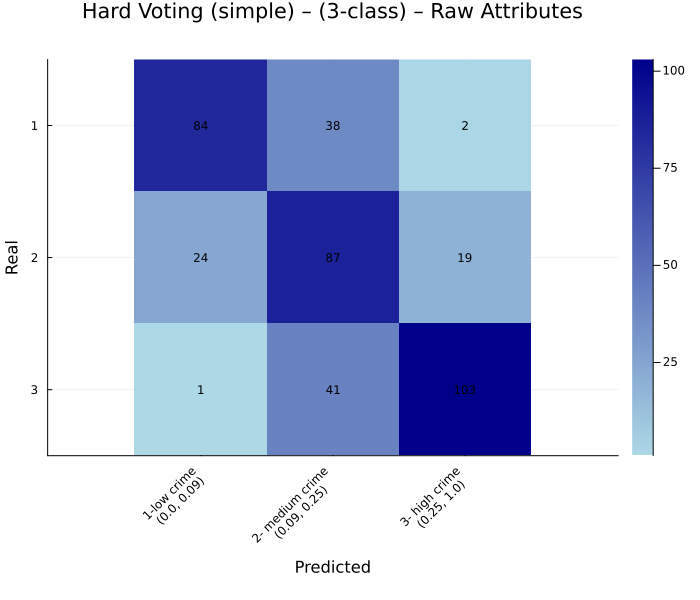

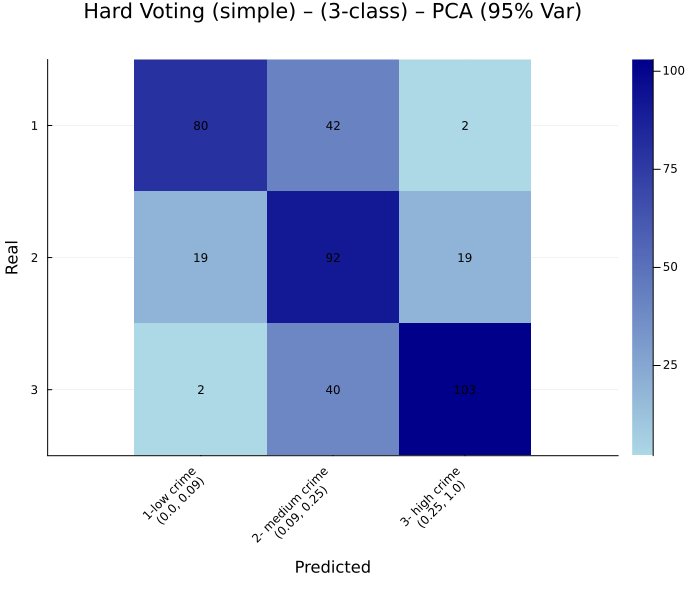

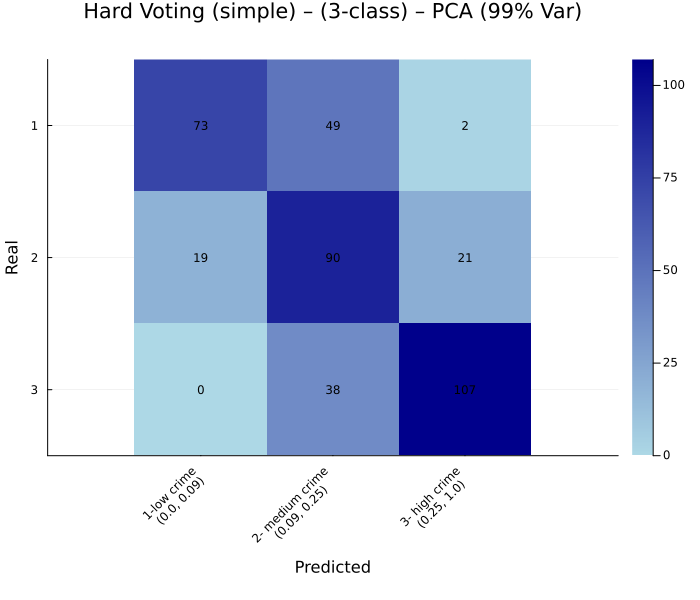

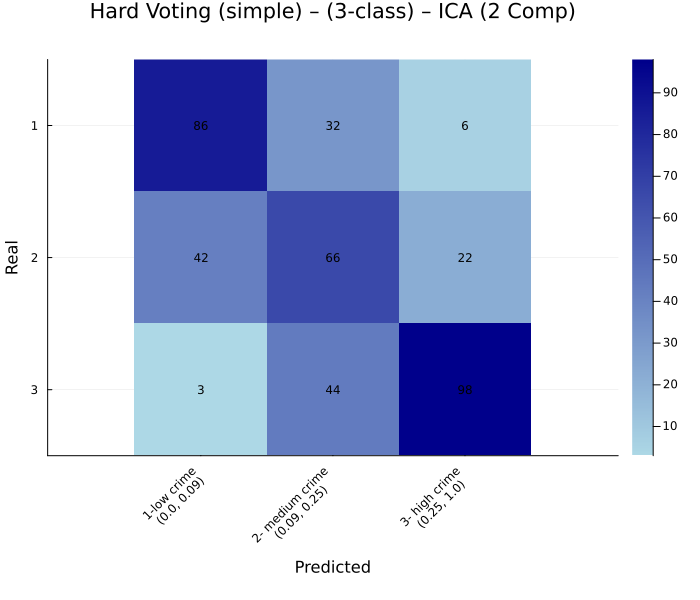

In [ ]:
simple_hard_voting_3_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned_3,
    test_output_binned_3;
    voting       = :hard,
    title_prefix = "3-class crime (simple)"
)

simple_hard_3_save_dir    = joinpath("ensembles", exp_name, "simple_hard_voting")
simple_hard_3_file_prefix = "simple_hard_voting_3class"

plotEnsembleConfusionsIndividual(
    simple_hard_voting_3_results,
    "Hard Voting (simple) – ($exp_name)";
    class_labels = class_labels_3,
    save_dir     = simple_hard_3_save_dir,
    file_prefix  = simple_hard_3_file_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [3-class crime (simple)] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.6842105263157895
Error Rate: 0.3157894736842105
Sensitivity (Recall): 0.6842105263157894
Specificity: 0.8445859121490036
Positive Predictive Value (Precision): 0.708764934298493
Negative Predictive Value (Precision): 0.8401649872366683
F-score: 0.6913131957920039
Confusion Matrix:
[86 24 20; 38 84 2; 41 1 103]

>>> [3-class crime (simple)] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.6766917293233082
Error Rate: 0.32330827067669177
Sensitivity (Recall): 0.6766917293233082
Specificity: 0.840246106133978
Positive Predictive Value (Precision): 0.7113763235820405
Negative Predictive Value (Precision): 0.8383307184634334
F-score: 0.6838914206078044
Confusion Matrix:
[90 19 21; 49 73 2; 38 0 107]

>>> [3-class crime (simple)] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.6265664160401002
Error Rate: 0.3734335839598998
S

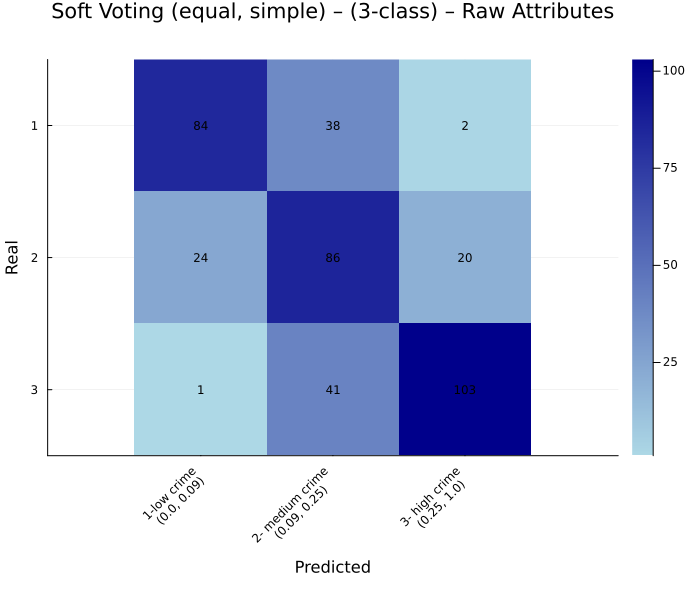

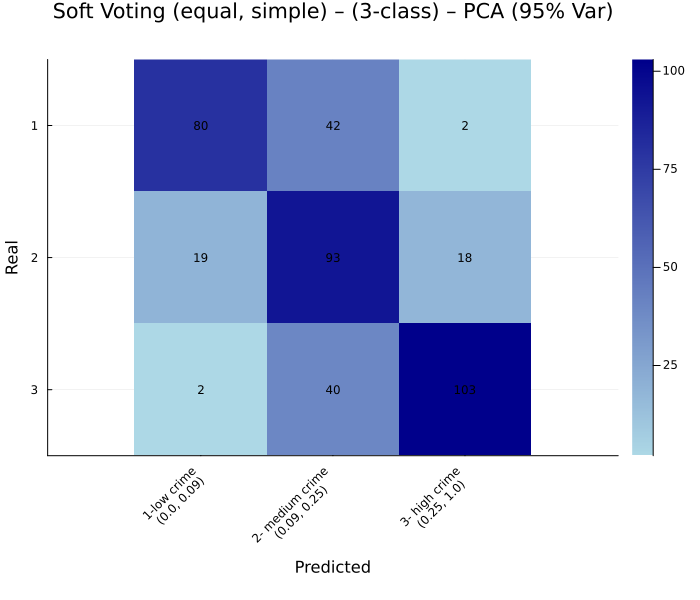

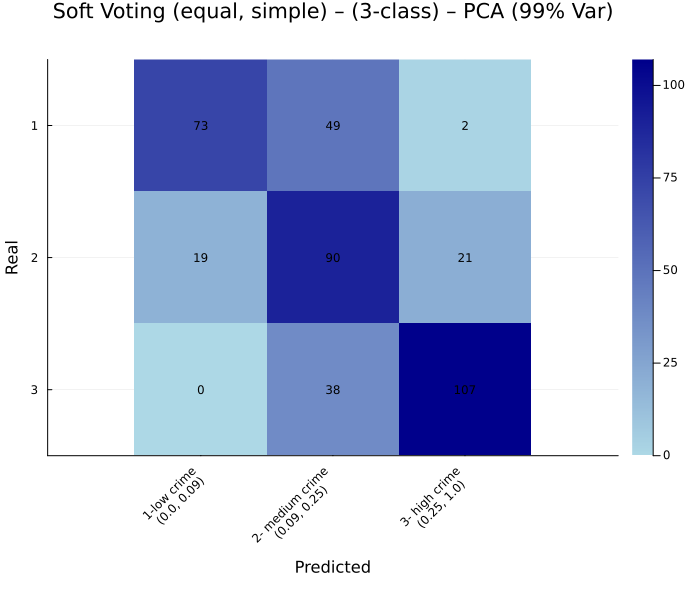

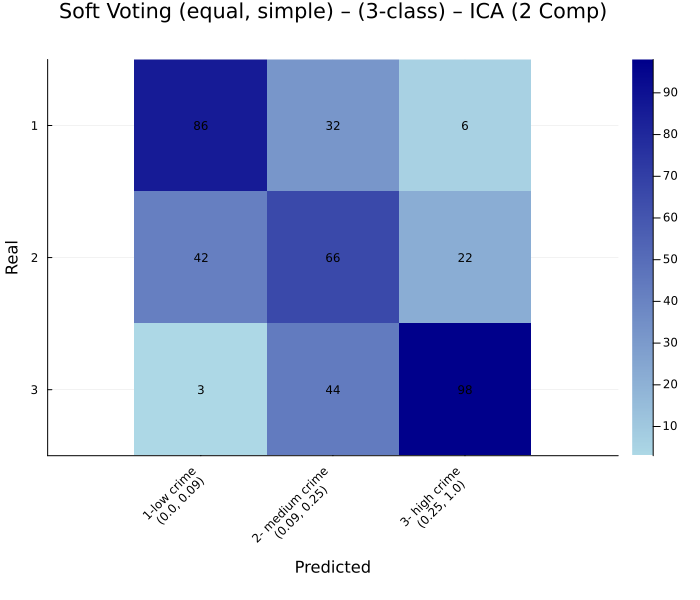

In [ ]:
simple_soft_equal_3_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned_3,
    test_output_binned_3;
    voting       = :soft,
    weights      = nothing,
    title_prefix = "3-class crime (simple)"
)

simple_soft_equal_3_dir    = joinpath("ensembles", exp_name, "simple_soft_equal_voting")
simple_soft_equal_3_prefix = "simple_soft_equal_voting_3class"

plotEnsembleConfusionsIndividual(
    simple_soft_equal_3_results,
    "Soft Voting (equal, simple) – ($exp_name)";
    class_labels = class_labels_3,
    save_dir     = simple_soft_equal_3_dir,
    file_prefix  = simple_soft_equal_3_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [3-class crime (simple)] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.7092731829573935
Error Rate: 0.2907268170426065
Sensitivity (Recall): 0.7092731829573935
Specificity: 0.8568266645650456
Positive Predictive Value (Precision): 0.7142874861242892
Negative Predictive Value (Precision): 0.8547651821541192
F-score: 0.7114281975677745
Confusion Matrix:
[78 30 22; 31 91 2; 29 2 114]

>>> [3-class crime (simple)] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.7017543859649122
Error Rate: 0.29824561403508776
Sensitivity (Recall): 0.7017543859649122
Specificity: 0.8522100040050977
Positive Predictive Value (Precision): 0.708820186127235
Negative Predictive Value (Precision): 0.8503486044655822
F-score: 0.7046526959177645
Confusion Matrix:
[78 27 25; 32 90 2; 32 1 112]

>>> [3-class crime (simple)] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.6265664160401002
Error Rate: 0.3734335839598998


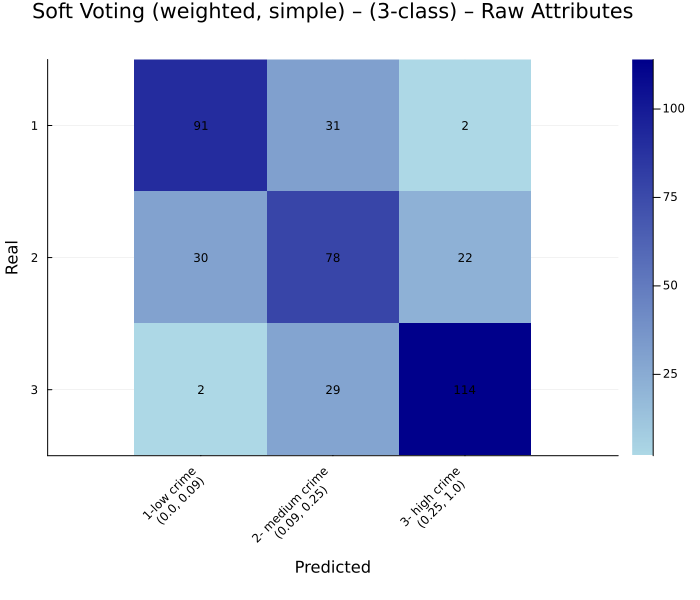

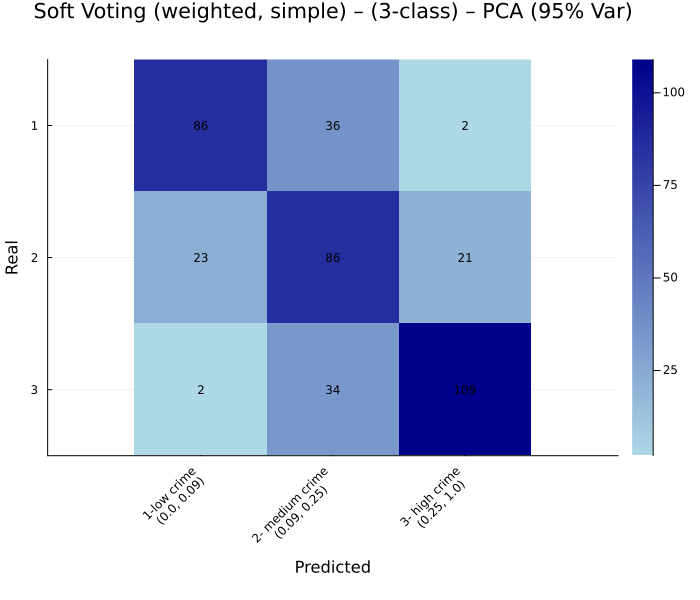

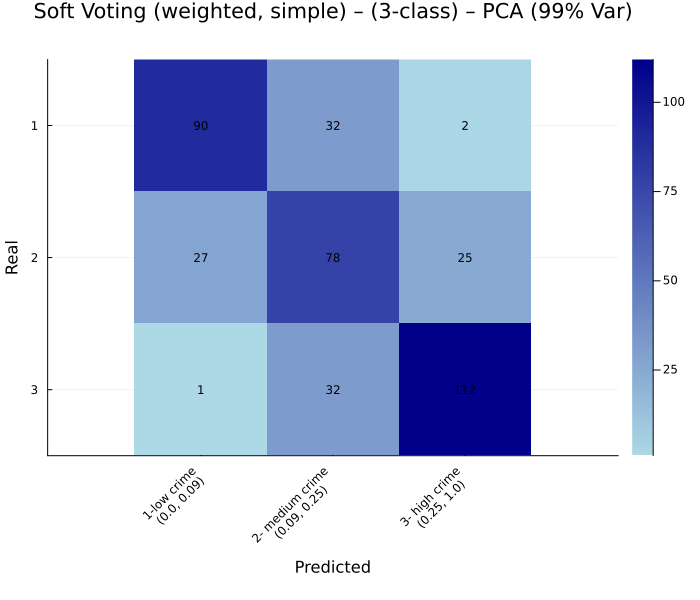

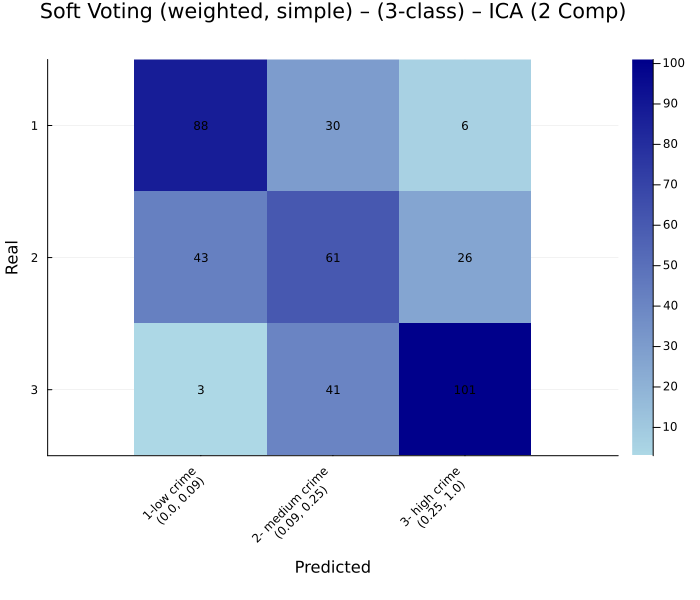

In [ ]:
simple_soft_weighted_3_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned_3,
    test_output_binned_3;
    voting       = :soft,
    weights      = soft_weights_3,
    title_prefix = "3-class crime (simple)"
)

simple_soft_weighted_3_dir    = joinpath("ensembles", exp_name, "simple_soft_weighted_voting")
simple_soft_weighted_3_prefix = "simple_soft_weighted_voting_3class"

plotEnsembleConfusionsIndividual(
    simple_soft_weighted_3_results,
    "Soft Voting (weighted, simple) – ($exp_name)";
    class_labels = class_labels_3,
    save_dir     = simple_soft_weighted_3_dir,
    file_prefix  = simple_soft_weighted_3_prefix
)


STACKING ENSEMBLES – CLASSIFICATION

>>> [3-class crime (simple)] Representation: Raw Attributes
Weighted Metrics:
Accuracy: 0.7092731829573935
Error Rate: 0.2907268170426065
Sensitivity (Recall): 0.7092731829573935
Specificity: 0.8554283415521104
Positive Predictive Value (Precision): 0.7083526027370013
Negative Predictive Value (Precision): 0.8555355417146266
F-score: 0.7087866954207223
Confusion Matrix:
[73 29 28; 27 95 2; 28 2 115]

>>> [3-class crime (simple)] Representation: PCA (99% Var)
Weighted Metrics:
Accuracy: 0.706766917293233
Error Rate: 0.29323308270676696
Sensitivity (Recall): 0.706766917293233
Specificity: 0.8548757423624815
Positive Predictive Value (Precision): 0.7085242410268711
Negative Predictive Value (Precision): 0.8542079852209661
F-score: 0.707603806334097
Confusion Matrix:
[74 31 25; 30 92 2; 29 0 116]

>>> [3-class crime (simple)] Representation: ICA (2 Comp)
Weighted Metrics:
Accuracy: 0.6416040100250626
Error Rate: 0.3583959899749374
Sensitivity (Recall):

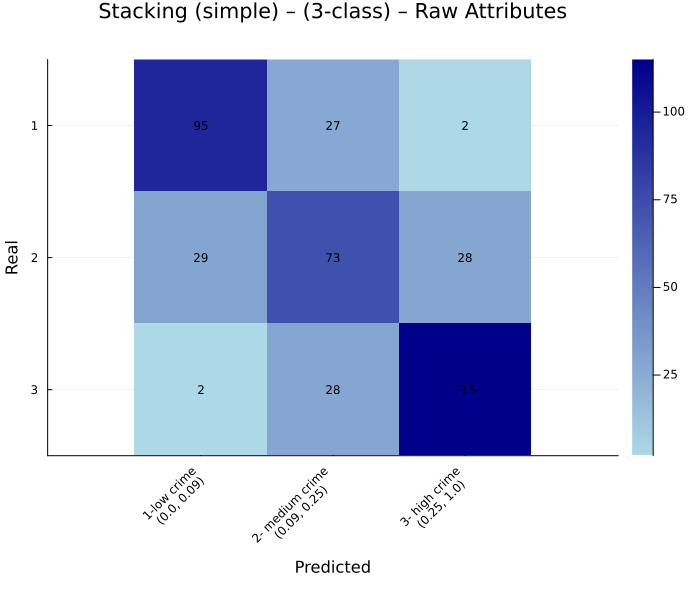

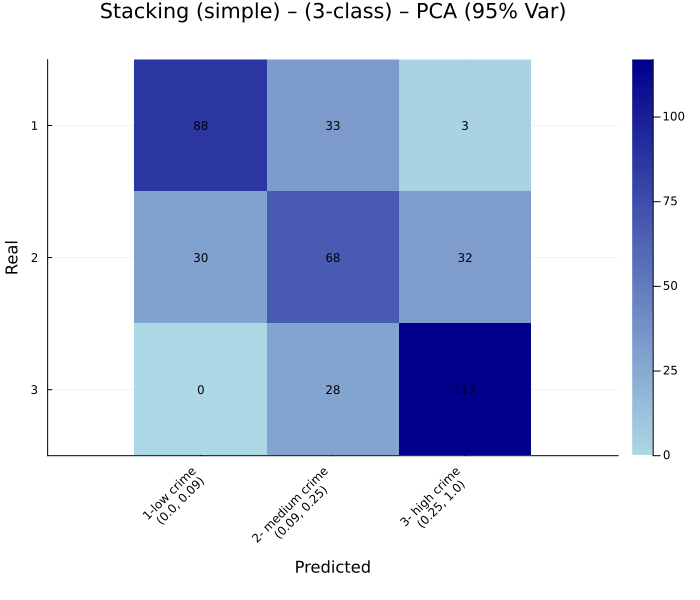

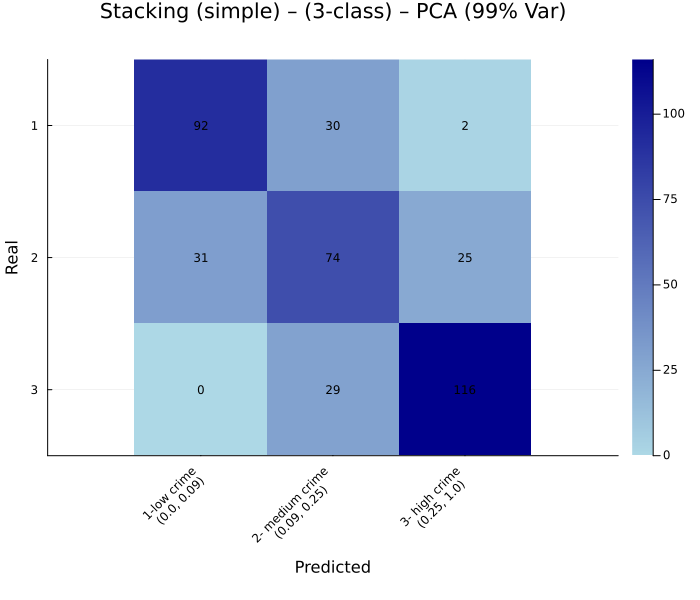

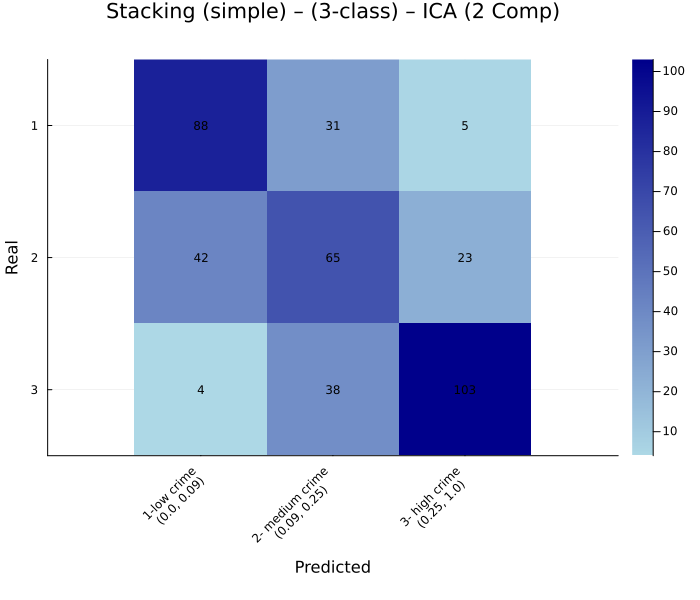

In [ ]:
simple_stacking_3_results = Ensembles.run_stacking_ensembles(
    simple_ensemble_specs,
    train_output_binned_3,
    test_output_binned_3;
    base_names   = (:ANN, :SVM, :DT, :KNN),
    title_prefix = "3-class crime (simple)"
)

simple_stacking_3_dir    = joinpath("ensembles", exp_name, "simple_stacking")
simple_stacking_3_prefix = "simple_stacking_3class"

plotEnsembleConfusionsIndividual(
    simple_stacking_3_results,
    "Stacking (simple) – ($exp_name)";
    class_labels = class_labels_3,
    save_dir     = simple_stacking_3_dir,
    file_prefix  = simple_stacking_3_prefix
)

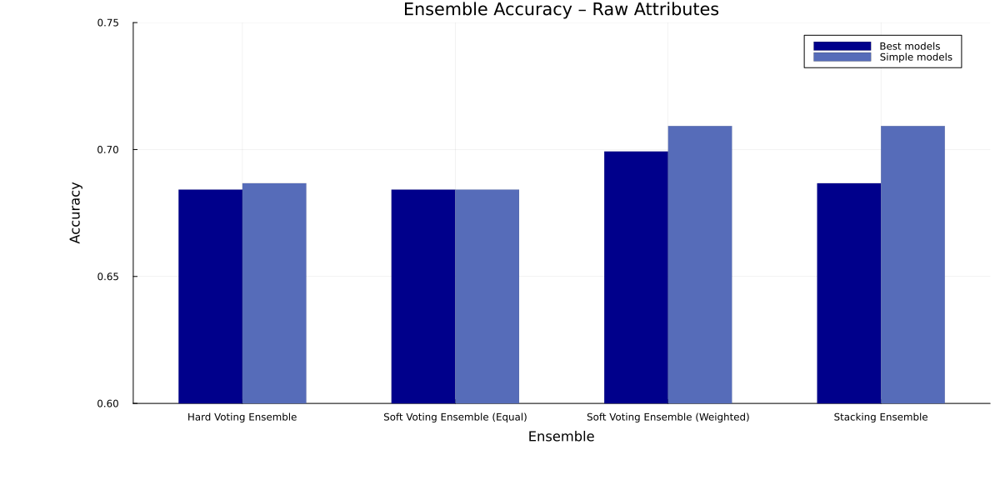

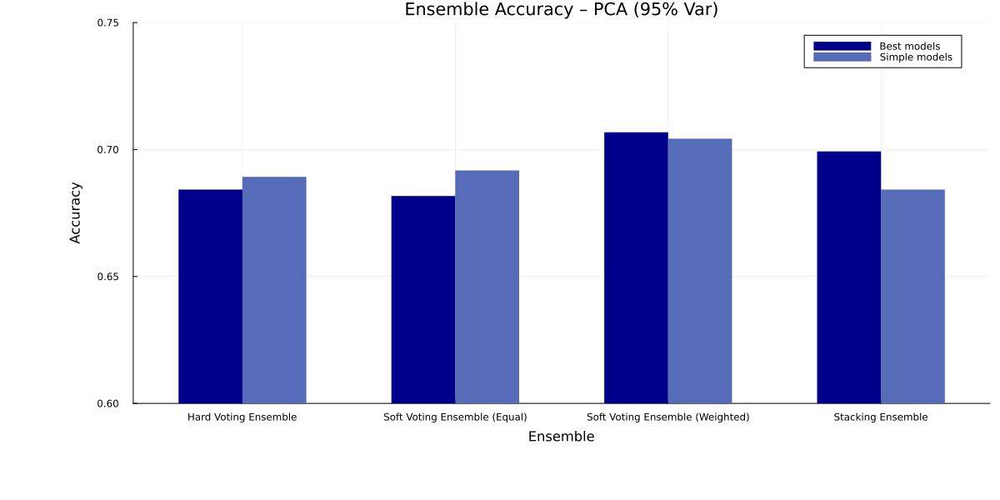

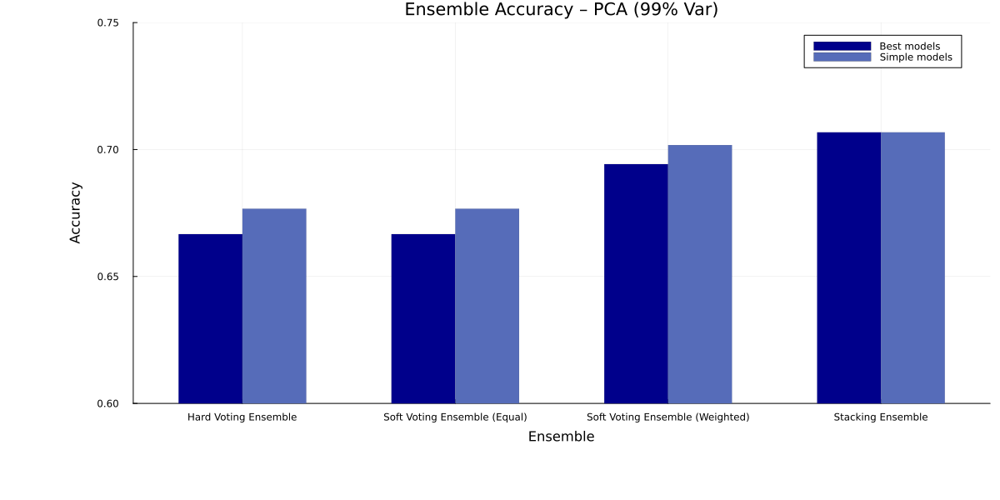

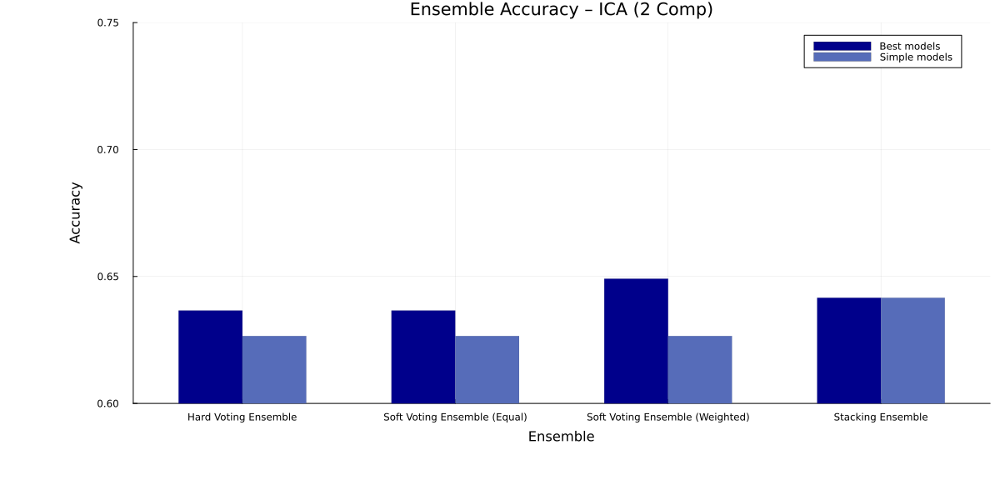

In [ ]:
data_to_plot_ensembles_3 = [
    (
        ds_name,
        [
            ("Hard Voting Ensemble",
                hard_voting_3_results[ds_name][1],
                hard_voting_3_results[ds_name][2]),
            ("Soft Voting Ensemble (Equal)",
                soft_equal_3_results[ds_name][1],
                soft_equal_3_results[ds_name][2]),
            ("Soft Voting Ensemble (Weighted)",
                soft_weighted_3_results[ds_name][1],
                soft_weighted_3_results[ds_name][2]),
            ("Stacking Ensemble",
                stacking_3_results[ds_name][1],
                stacking_3_results[ds_name][2])
        ]
    )
    for ds_name in ordered_datasets
]

data_to_plot_ensembles_3_simple = [
    (
        ds_name,
        [
            ("Hard Voting Ensemble",
                simple_hard_voting_3_results[ds_name][1],
                simple_hard_voting_3_results[ds_name][2]),
            ("Soft Voting Ensemble (Equal)",
                simple_soft_equal_3_results[ds_name][1],
                simple_soft_equal_3_results[ds_name][2]),
            ("Soft Voting Ensemble (Weighted)",
                simple_soft_weighted_3_results[ds_name][1],
                simple_soft_weighted_3_results[ds_name][2]),
            ("Stacking Ensemble",
                simple_stacking_3_results[ds_name][1],
                simple_stacking_3_results[ds_name][2])
        ]
    )
    for ds_name in ordered_datasets
]

plotEnsembleAccuracyBestVsSimple(
    data_to_plot_ensembles_3,
    data_to_plot_ensembles_3_simple;
    folder_name   = "ensembles/3-class/accuracy_best_vs_simple",
    base_filename = "accuracy_3class_best_vs_simple",
    size          = (1200, 600),
    ylims         = (0.6, 0.75) 
)


In [ ]:
# Global Attributes for Experiments
exp_name = "2-class"

class_labels_2 = [
    "1-low crime\n(0.0, 0.15)",
    "2-high crime\n(0.15, 1.0)"
]

soft_weights = [1.5, 2, 1.3, 1.7]

ensemble_specs = Dict([
    name => (
        X_train = experiment.X,
        X_test  = experiment.x_test,
        models  = [
            model
            for names, model in experiment.best_machines 
        ]
    )
    for name, experiment in suites_2
])
# ensemble_specs = Dict(
#     "Raw Attributes" => (
#         X_train = train_input,
#         X_test  = test_input,
#         models  = [
#             best_ann_class_model,
#             best_svm_class_model,
#             best_dt_class_model,
#             best_knn_class_model
#         ]
#     ),
#     "PCA (95% Var)" => (
#         X_train = pca_train,
#         X_test  = pca_test,
#         models  = [
#             best_ann_class_model_95,
#             best_svm_class_model_95,
#             best_dt_class_model_95,
#             best_knn_class_model_95
#         ]
#     ),
#     "PCA (99% Var)" => (
#         X_train = pca_train_99,
#         X_test  = pca_test_99,
#         models  = [
#             best_ann_class_model_99,
#             best_svm_class_model_99,
#             best_dt_class_model_99,
#             best_knn_class_model_99
#         ]
#     ),
#     "ICA (2 Comp)" => (
#         X_train = ica_train,
#         X_test  = ica_test,
#         models  = [
#             best_ann_class_model_ica,
#             best_svm_class_model_ica,
#             best_dt_class_model_ica,
#             best_knn_class_model_ica
#         ]
#     ),
#     "Filtered by Correlation" => (
#         X_train = train_corr,
#         X_test  = test_corr,
#         models  = [
#             best_ann_model_corr,
#             best_svm_model_corr,
#             best_dt_model_corr,
#             best_knn_model_corr
#         ]
#     )
# )


Dict{String, @NamedTuple{X_train::Matrix{Float64}, X_test::Matrix{Float64}, models::Vector{Probabilistic}}} with 4 entries:
  "Raw Attributes" => (X_train = [0.02 0.56 … 0.02 0.0; 0.04 0.35 … 0.05 0.0; ……
  "PCA (99% Var)"  => (X_train = [-0.524125 -0.192786 … -0.0400254 -0.052233; -…
  "ICA (2 Comp)"   => (X_train = [-0.315278 0.45694; 0.308958 0.260741; … ; -0.…
  "PCA (95% Var)"  => (X_train = [-0.524125 -0.192786 … 0.075712 0.156021; -0.2…


VOTING ENSEMBLES – CLASSIFICATION

>>> [2-class crime] Dataset: Raw Attributes (voting=hard)
Weighted Metrics:
Accuracy: 0.8446115288220551
Error Rate: 0.15538847117794485
Sensitivity (Recall): 0.8648648648648649
Specificity: 0.8271028037383178
Positive Predictive Value (Precision): 0.8121827411167513
Negative Predictive Value (Precision): 0.8762376237623762
F-score: 0.837696335078534
Confusion Matrix:
[177 37; 25 160]

>>> [2-class crime] Dataset: PCA (99% Var) (voting=hard)
Weighted Metrics:
Accuracy: 0.8220551378446115
Error Rate: 0.17794486215538846
Sensitivity (Recall): 0.8324324324324325
Specificity: 0.8130841121495327
Positive Predictive Value (Precision): 0.7938144329896907
Negative Predictive Value (Precision): 0.848780487804878
F-score: 0.8126649076517151
Confusion Matrix:
[174 40; 31 154]

>>> [2-class crime] Dataset: ICA (2 Comp) (voting=hard)
Weighted Metrics:
Accuracy: 0.7744360902255639
Error Rate: 0.22556390977443608
Sensitivity (Recall): 0.772972972972973
Specificity:

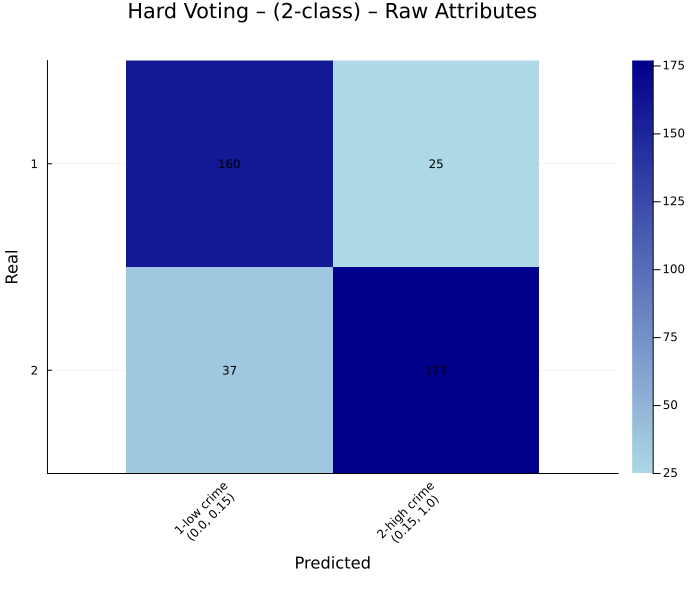

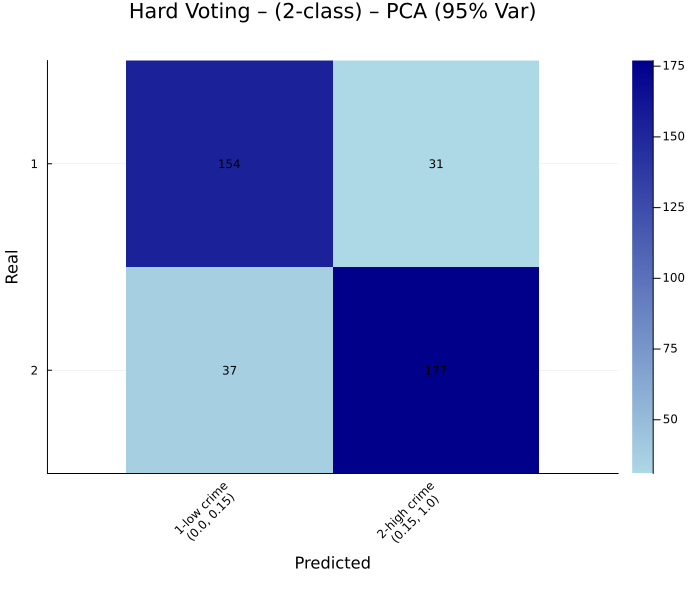

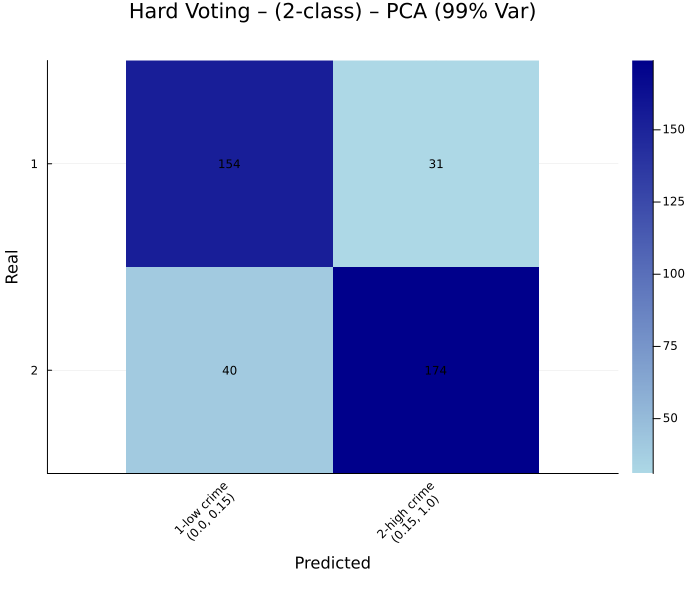

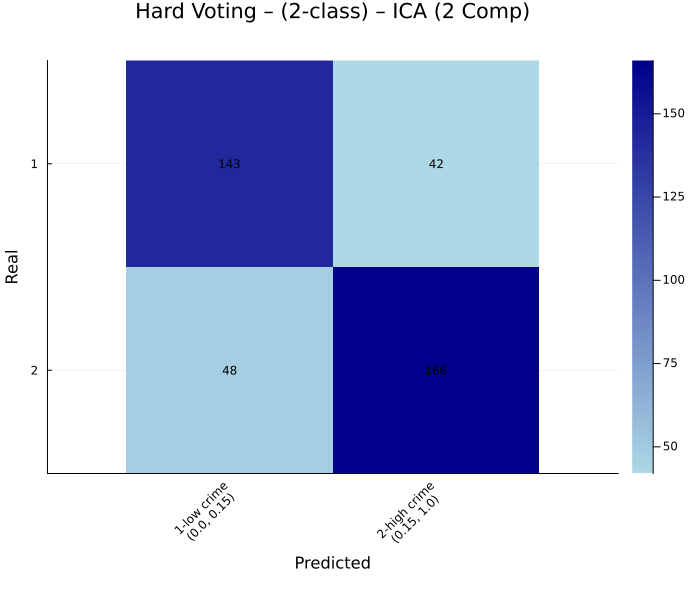

In [ ]:
# 1) Run ensembles
hard_voting_results = run_voting_ensembles(
    ensemble_specs,
    suites_2["Raw Attributes"].y,
    suites_2["Raw Attributes"].y_test;
    voting       = :hard,
    title_prefix = "2-class crime"
)

# 2) Images directory
save_dir = joinpath("ensembles", exp_name, "hard_voting")
file_prefix = "hard_voting_2class"

# 3) Plots
plotEnsembleConfusionsIndividual(
    hard_voting_results,
    "Hard Voting – ($exp_name)";
    class_labels = class_labels_2,
    save_dir     = save_dir,
    file_prefix  = file_prefix
)



VOTING ENSEMBLES – CLASSIFICATION

>>> [2-class crime] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.8471177944862155
Error Rate: 0.15288220551378445
Sensitivity (Recall): 0.8648648648648649
Specificity: 0.8317757009345794
Positive Predictive Value (Precision): 0.8163265306122449
Negative Predictive Value (Precision): 0.8768472906403941
F-score: 0.8398950131233596
Confusion Matrix:
[178 36; 25 160]

>>> [2-class crime] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.8270676691729323
Error Rate: 0.17293233082706766
Sensitivity (Recall): 0.8432432432432433
Specificity: 0.8130841121495327
Positive Predictive Value (Precision): 0.7959183673469388
Negative Predictive Value (Precision): 0.8571428571428571
F-score: 0.8188976377952756
Confusion Matrix:
[174 40; 29 156]

>>> [2-class crime] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.7744360902255639
Error Rate: 0.22556390977443608
Sensitivity (Recall): 0.772972972972973
Specificit

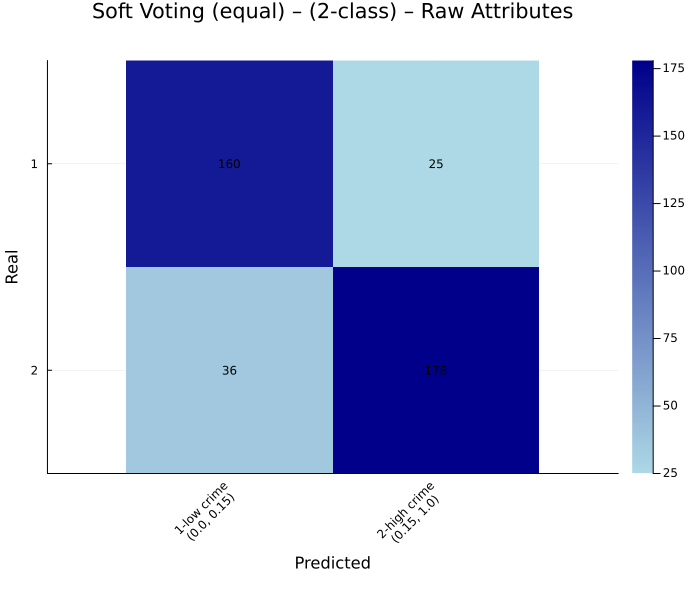

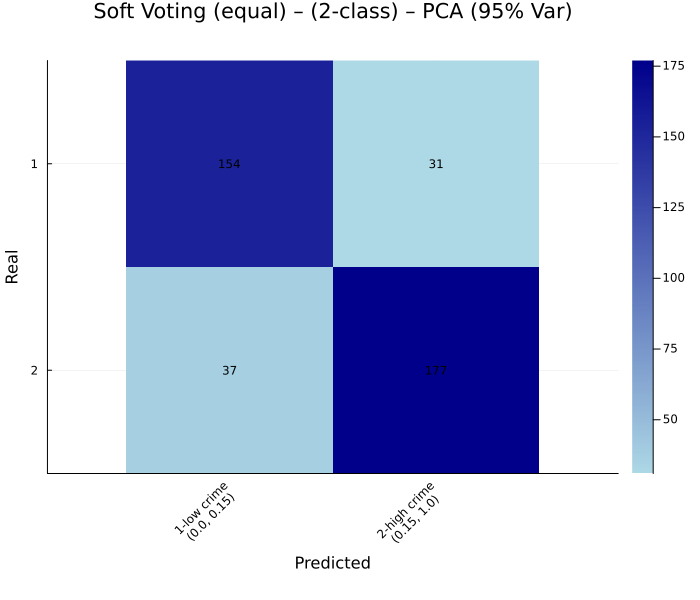

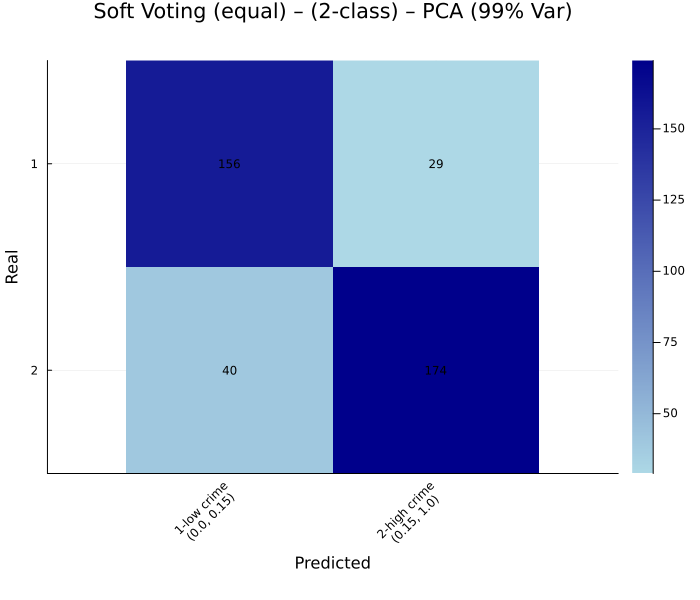

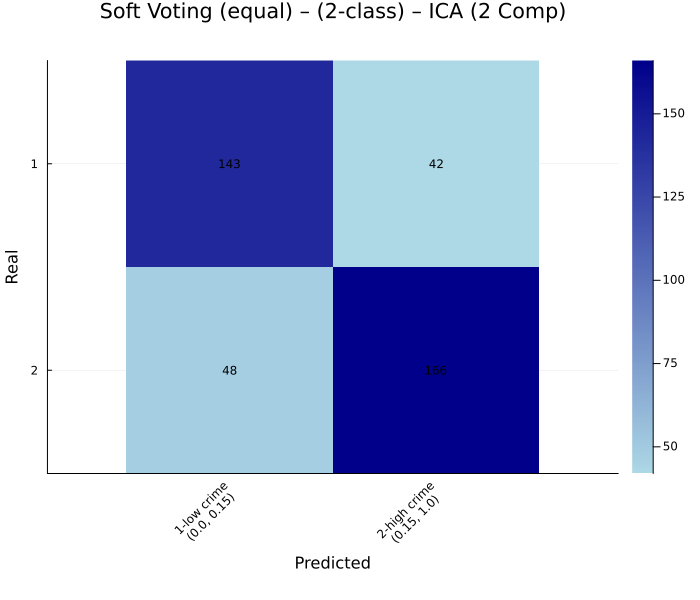

In [ ]:
soft_equal_results = run_voting_ensembles(
    ensemble_specs,
    train_output_binned_2,
    test_output_binned_2;
    voting       = :soft,           # <- soft
    weights      = nothing,         # <- pesos iguales por defecto
    title_prefix = "2-class crime"
)

soft_equal_dir    = joinpath("ensembles", exp_name, "soft_equal_voting")
soft_equal_prefix = "soft_equal_voting_2class"

plotEnsembleConfusionsIndividual(
    soft_equal_results,
    "Soft Voting (equal) – ($exp_name)";
    class_labels = class_labels_2,
    save_dir     = soft_equal_dir,
    file_prefix  = soft_equal_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [2-class crime] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.8345864661654135
Error Rate: 0.16541353383458646
Sensitivity (Recall): 0.8648648648648649
Specificity: 0.8084112149532711
Positive Predictive Value (Precision): 0.7960199004975125
Negative Predictive Value (Precision): 0.8737373737373737
F-score: 0.8290155440414507
Confusion Matrix:
[173 41; 25 160]

>>> [2-class crime] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.8320802005012531
Error Rate: 0.16791979949874686
Sensitivity (Recall): 0.8756756756756757
Specificity: 0.794392523364486
Positive Predictive Value (Precision): 0.7864077669902912
Negative Predictive Value (Precision): 0.8808290155440415
F-score: 0.8286445012787724
Confusion Matrix:
[170 44; 23 162]

>>> [2-class crime] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.7869674185463659
Error Rate: 0.21303258145363407
Sensitivity (Recall): 0.8054054054054054
Specificit

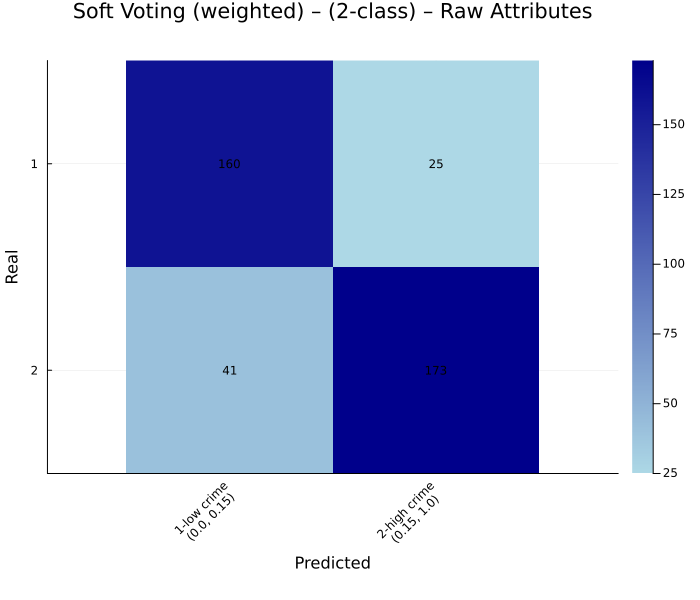

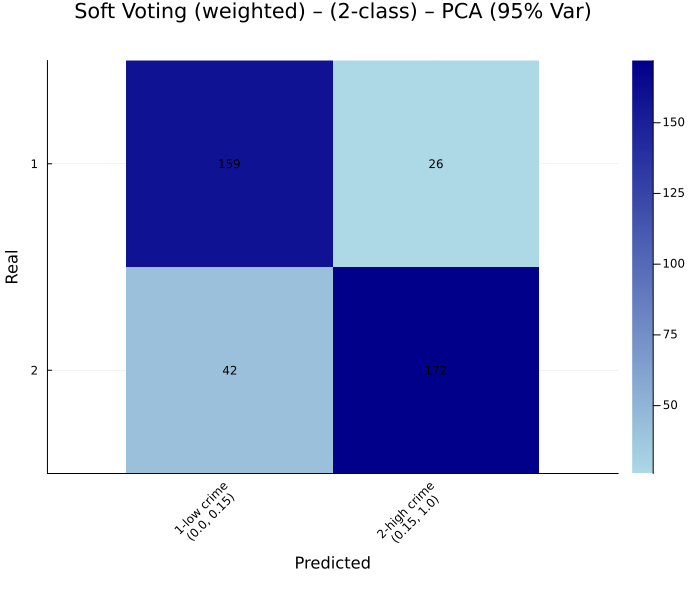

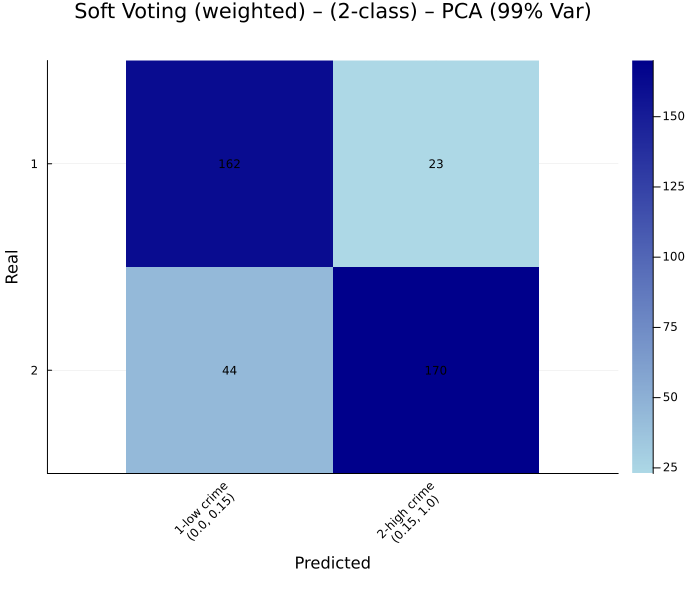

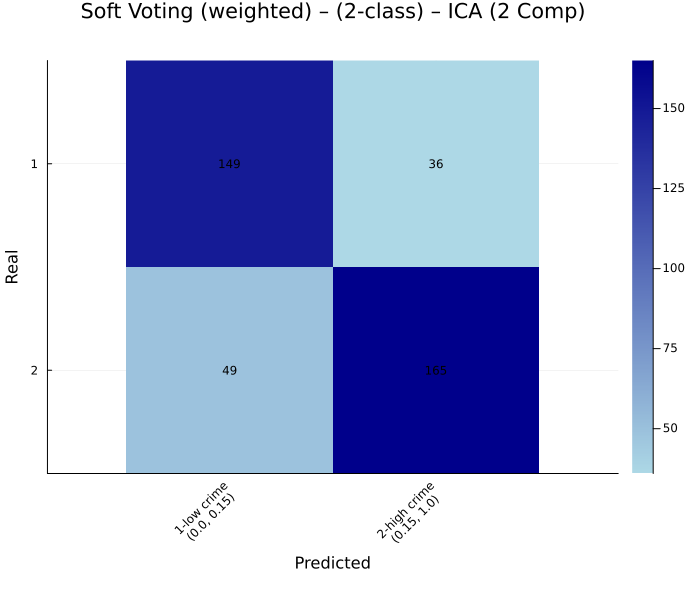

In [ ]:
soft_weighted_results = run_voting_ensembles(
    ensemble_specs,
    train_output_binned_2,
    test_output_binned_2;
    voting       = :soft,
    weights      = soft_weights,       
    title_prefix = "2-class crime"
)

soft_weighted_dir    = joinpath("ensembles", exp_name, "soft_weighted_voting")
soft_weighted_prefix = "soft_weighted_voting_2class"

plotEnsembleConfusionsIndividual(
    soft_weighted_results,
    "Soft Voting (weighted) – ($exp_name)";
    class_labels = class_labels_2,
    save_dir     = soft_weighted_dir,
    file_prefix  = soft_weighted_prefix
)


STACKING ENSEMBLES – CLASSIFICATION

>>> [2-class crime] Representation: Raw Attributes
Weighted Metrics:
Accuracy: 0.8370927318295739
Error Rate: 0.16290726817042606
Sensitivity (Recall): 0.8810810810810811
Specificity: 0.7990654205607477
Positive Predictive Value (Precision): 0.7912621359223301
Negative Predictive Value (Precision): 0.8860103626943006
F-score: 0.8337595907928389
Confusion Matrix:
[171 43; 22 163]

>>> [2-class crime] Representation: PCA (99% Var)
Weighted Metrics:
Accuracy: 0.8320802005012531
Error Rate: 0.16791979949874686
Sensitivity (Recall): 0.8594594594594595
Specificity: 0.8084112149532711
Positive Predictive Value (Precision): 0.795
Negative Predictive Value (Precision): 0.8693467336683417
F-score: 0.825974025974026
Confusion Matrix:
[173 41; 26 159]

>>> [2-class crime] Representation: ICA (2 Comp)
Weighted Metrics:
Accuracy: 0.7769423558897243
Error Rate: 0.22305764411027568
Sensitivity (Recall): 0.7837837837837838
Specificity: 0.7710280373831776
Positive P

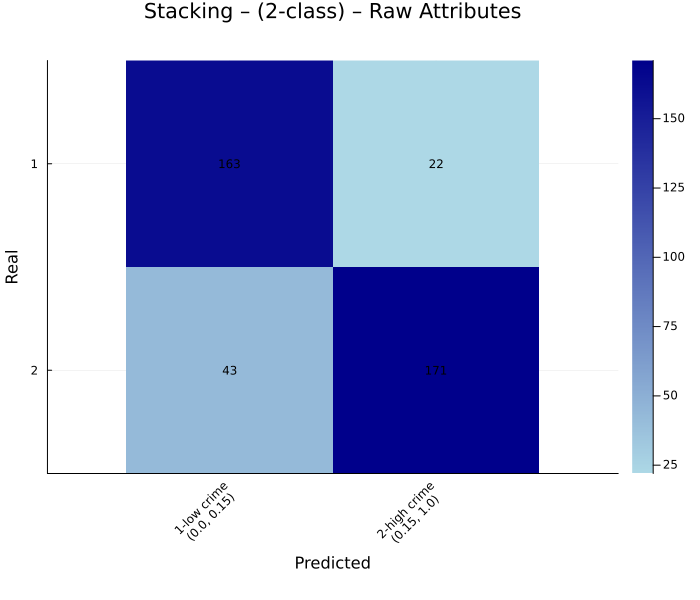

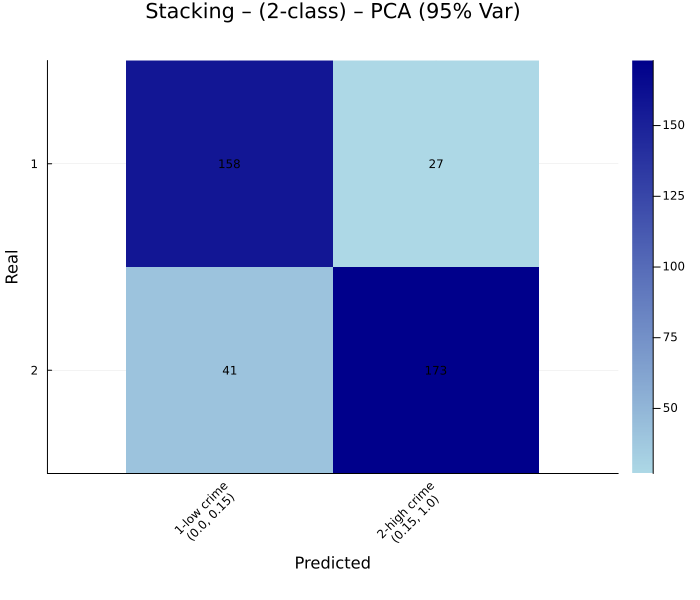

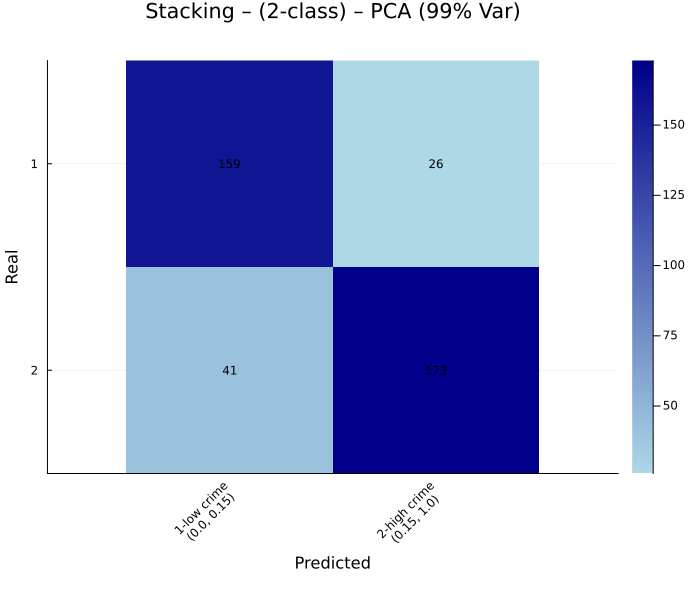

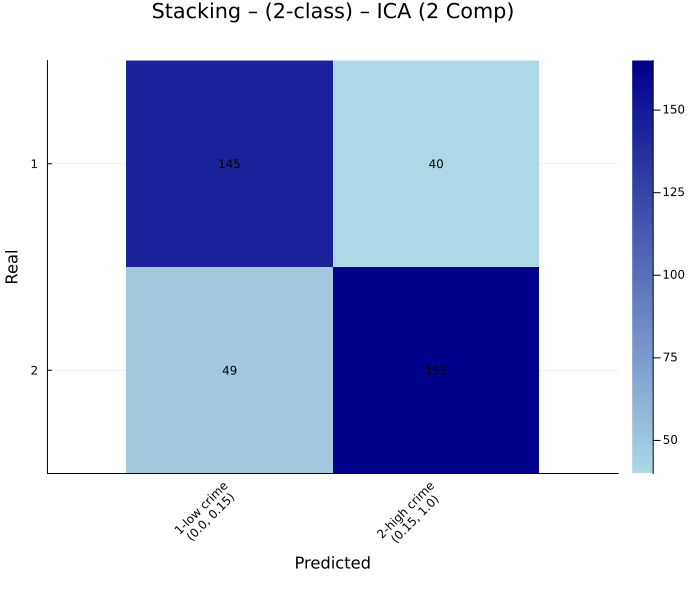

In [ ]:
stacking_results = Ensembles.run_stacking_ensembles(
    ensemble_specs,
    train_output_binned_2,
    test_output_binned_2;
    base_names   = (:ANN, :SVM, :DT, :KNN),
    title_prefix = "2-class crime"
)

stacking_dir    = joinpath("ensembles", exp_name, "stacking")
stacking_prefix = "stacking_2class"

plotEnsembleConfusionsIndividual(
    stacking_results,
    "Stacking – ($exp_name)";
    class_labels = class_labels_2,
    save_dir     = stacking_dir,
    file_prefix  = stacking_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [2-class crime (simple)] Dataset: Raw Attributes (voting=hard)
Weighted Metrics:
Accuracy: 0.8245614035087719
Error Rate: 0.17543859649122806
Sensitivity (Recall): 0.827027027027027
Specificity: 0.822429906542056
Positive Predictive Value (Precision): 0.8010471204188482
Negative Predictive Value (Precision): 0.8461538461538461
F-score: 0.8138297872340425
Confusion Matrix:
[176 38; 32 153]

>>> [2-class crime (simple)] Dataset: PCA (99% Var) (voting=hard)
Weighted Metrics:
Accuracy: 0.8395989974937343
Error Rate: 0.16040100250626566
Sensitivity (Recall): 0.827027027027027
Specificity: 0.8504672897196262
Positive Predictive Value (Precision): 0.827027027027027
Negative Predictive Value (Precision): 0.8504672897196262
F-score: 0.827027027027027
Confusion Matrix:
[182 32; 32 153]

>>> [2-class crime (simple)] Dataset: ICA (2 Comp) (voting=hard)
Weighted Metrics:
Accuracy: 0.7719298245614035
Error Rate: 0.22807017543859648
Sensitivity (Recall): 0.7729

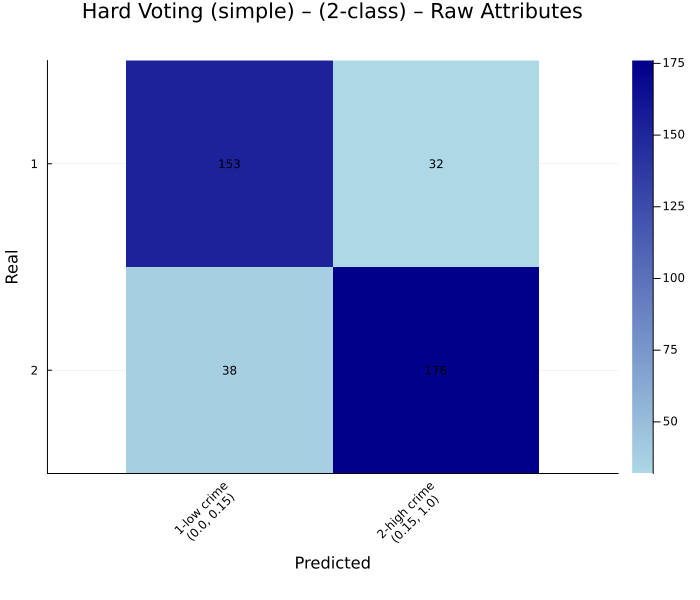

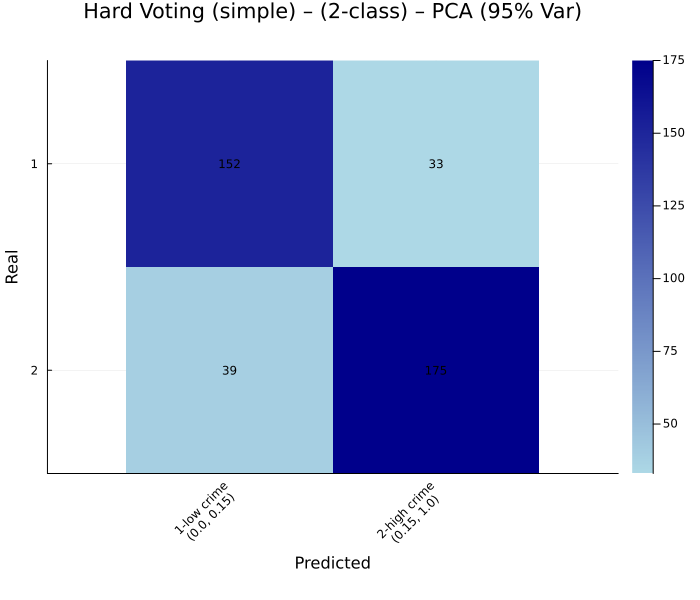

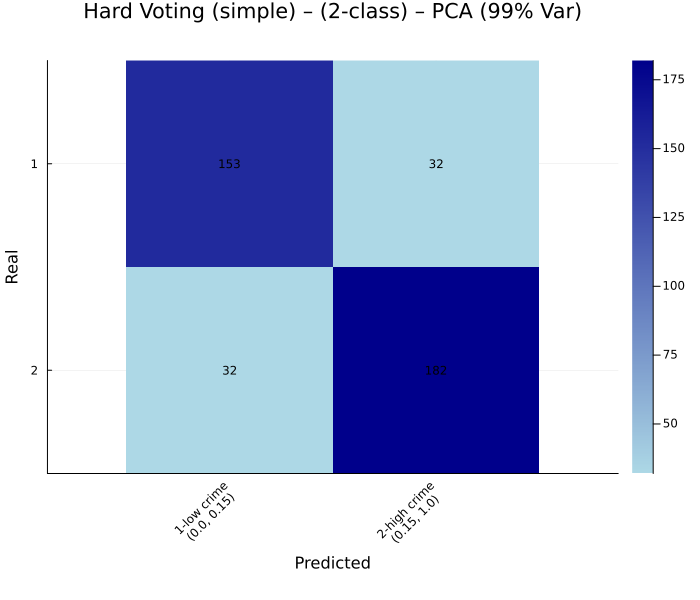

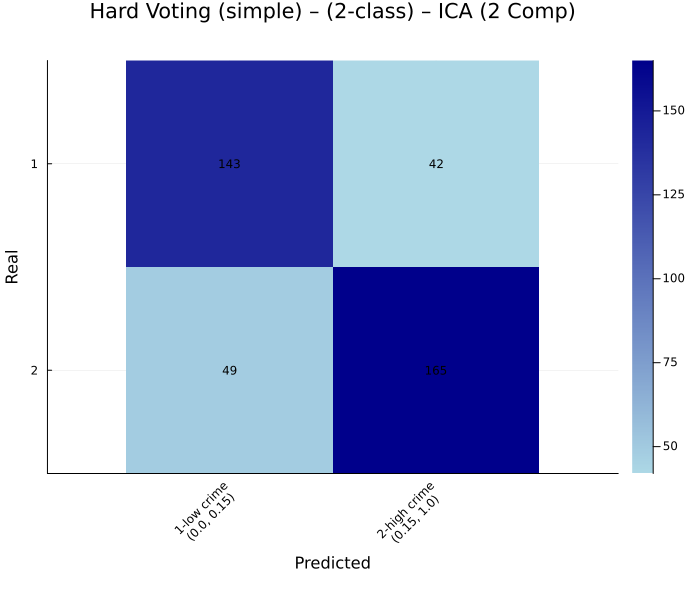

In [ ]:
simple_hard_voting_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned_2,
    test_output_binned_2;
    voting       = :hard,
    title_prefix = "2-class crime (simple)"
)

simple_hard_save_dir    = joinpath("ensembles", exp_name, "simple_hard_voting")
simple_hard_file_prefix = "simple_hard_voting_2class"

plotEnsembleConfusionsIndividual(
    simple_hard_voting_results,
    "Hard Voting (simple) – ($exp_name)";
    class_labels = class_labels_2,
    save_dir     = simple_hard_save_dir,
    file_prefix  = simple_hard_file_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [2-class crime (simple)] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.8245614035087719
Error Rate: 0.17543859649122806
Sensitivity (Recall): 0.827027027027027
Specificity: 0.822429906542056
Positive Predictive Value (Precision): 0.8010471204188482
Negative Predictive Value (Precision): 0.8461538461538461
F-score: 0.8138297872340425
Confusion Matrix:
[176 38; 32 153]

>>> [2-class crime (simple)] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.8395989974937343
Error Rate: 0.16040100250626566
Sensitivity (Recall): 0.827027027027027
Specificity: 0.8504672897196262
Positive Predictive Value (Precision): 0.827027027027027
Negative Predictive Value (Precision): 0.8504672897196262
F-score: 0.827027027027027
Confusion Matrix:
[182 32; 32 153]

>>> [2-class crime (simple)] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.7744360902255639
Error Rate: 0.22556390977443608
Sensitivity (Recall): 0.7729

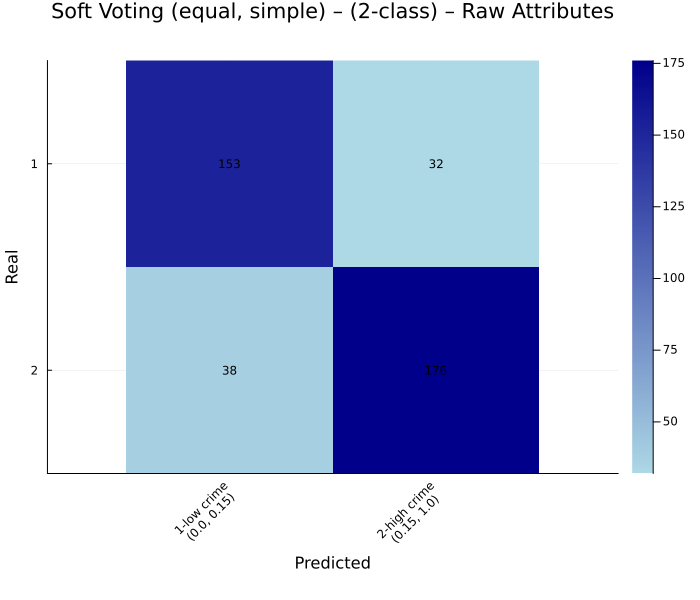

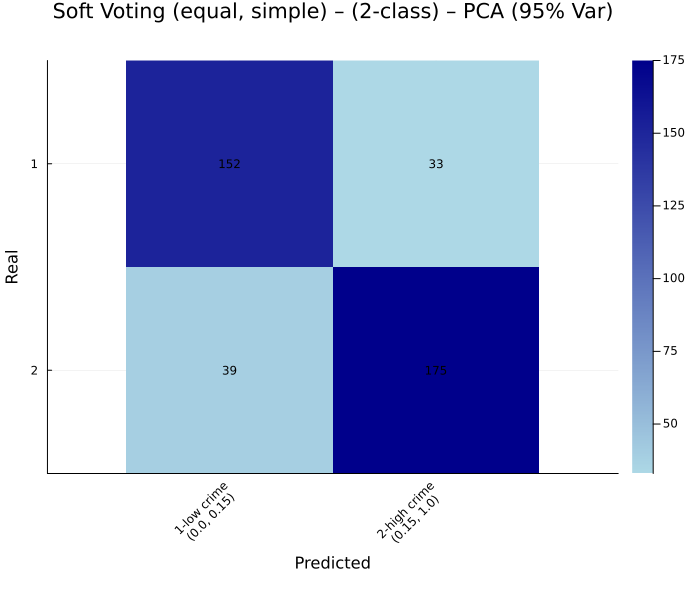

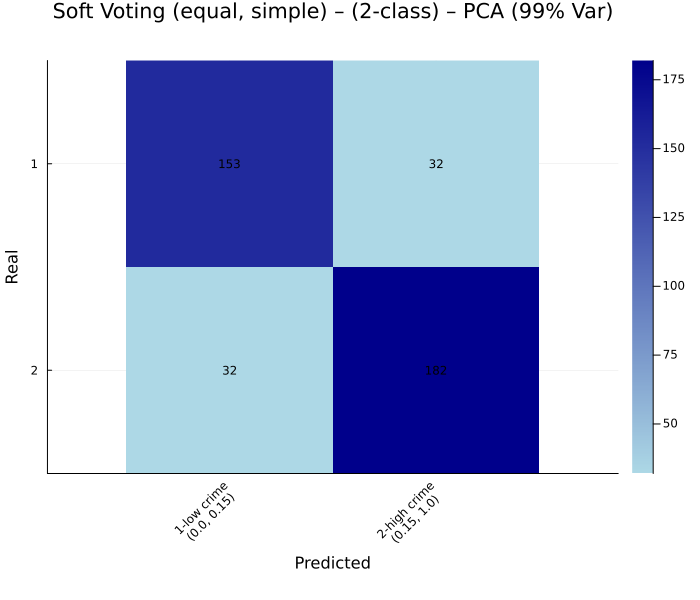

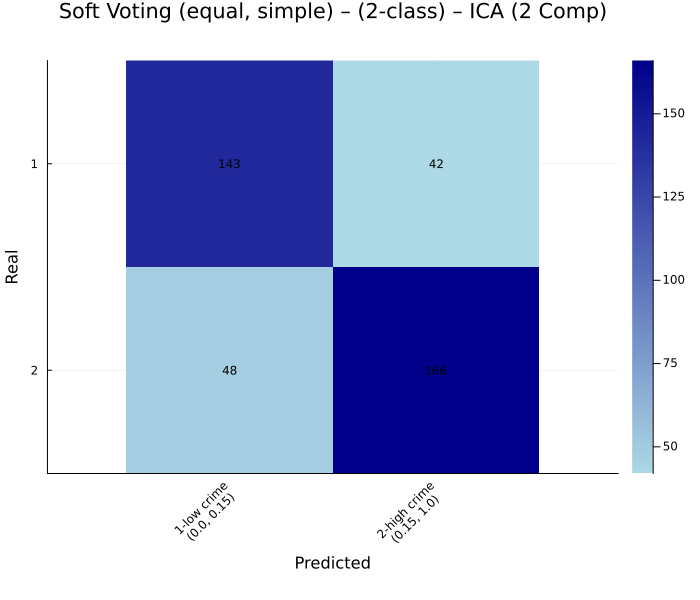

In [ ]:
simple_soft_equal_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned_2,
    test_output_binned_2;
    voting       = :soft,
    weights      = nothing,                       # igualitario
    title_prefix = "2-class crime (simple)"
)

simple_soft_equal_save_dir    = joinpath("ensembles", exp_name, "simple_soft_equal_voting")
simple_soft_equal_file_prefix = "simple_soft_equal_voting_2class"

plotEnsembleConfusionsIndividual(
    simple_soft_equal_results,
    "Soft Voting (equal, simple) – ($exp_name)";
    class_labels = class_labels_2,
    save_dir     = simple_soft_equal_save_dir,
    file_prefix  = simple_soft_equal_file_prefix
)


VOTING ENSEMBLES – CLASSIFICATION

>>> [2-class crime (simple)] Dataset: Raw Attributes (voting=soft)
Weighted Metrics:
Accuracy: 0.8395989974937343
Error Rate: 0.16040100250626566
Sensitivity (Recall): 0.8756756756756757
Specificity: 0.8084112149532711
Positive Predictive Value (Precision): 0.7980295566502463
Negative Predictive Value (Precision): 0.8826530612244898
F-score: 0.8350515463917526
Confusion Matrix:
[173 41; 23 162]

>>> [2-class crime (simple)] Dataset: PCA (99% Var) (voting=soft)
Weighted Metrics:
Accuracy: 0.8446115288220551
Error Rate: 0.15538847117794485
Sensitivity (Recall): 0.8756756756756757
Specificity: 0.8177570093457944
Positive Predictive Value (Precision): 0.8059701492537313
Negative Predictive Value (Precision): 0.8838383838383839
F-score: 0.8393782383419689
Confusion Matrix:
[175 39; 23 162]

>>> [2-class crime (simple)] Dataset: ICA (2 Comp) (voting=soft)
Weighted Metrics:
Accuracy: 0.7794486215538847
Error Rate: 0.22055137844611528
Sensitivity (Recall): 0

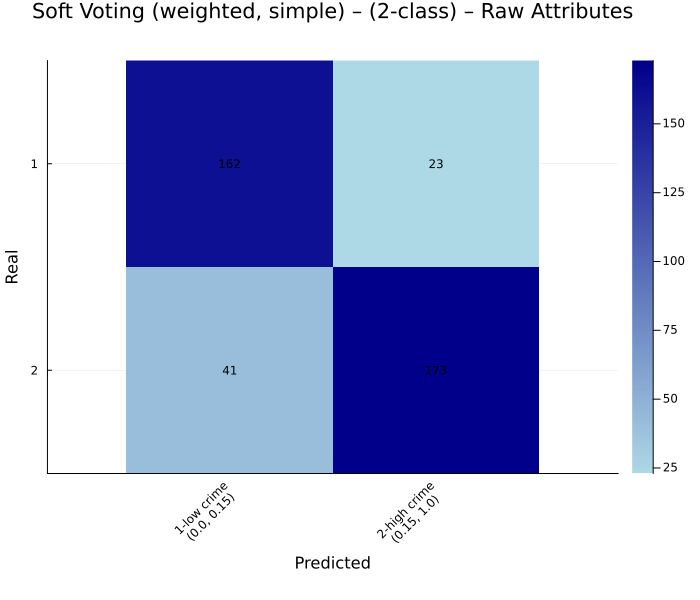

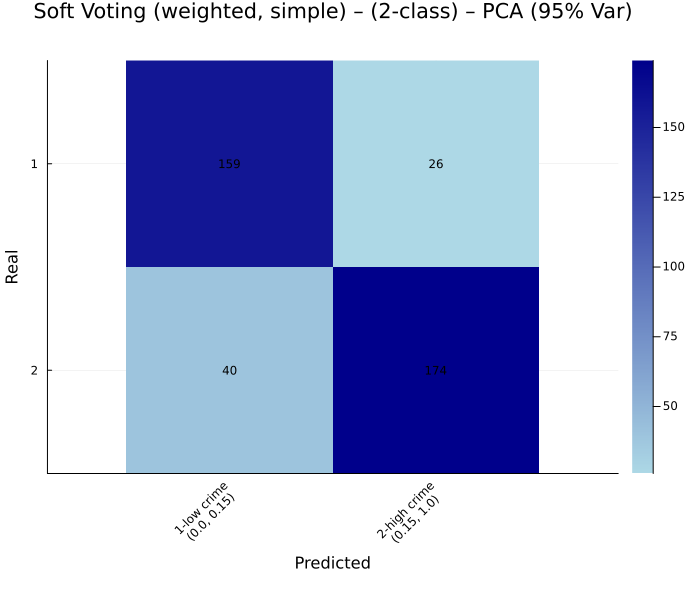

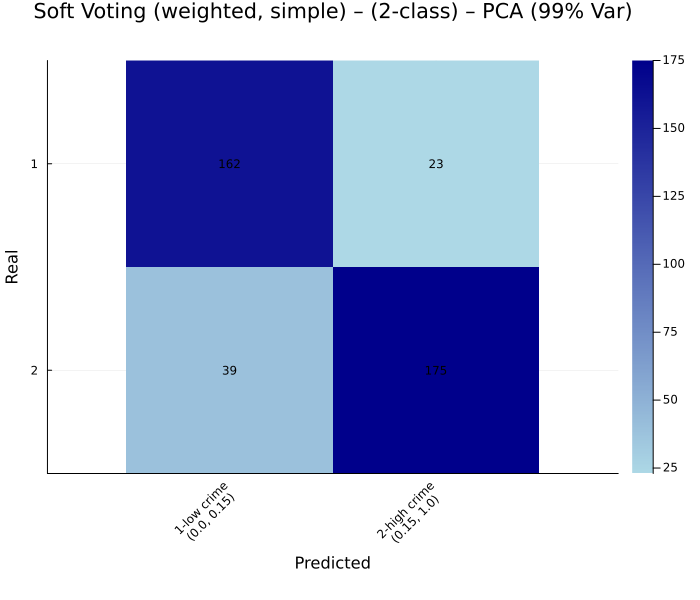

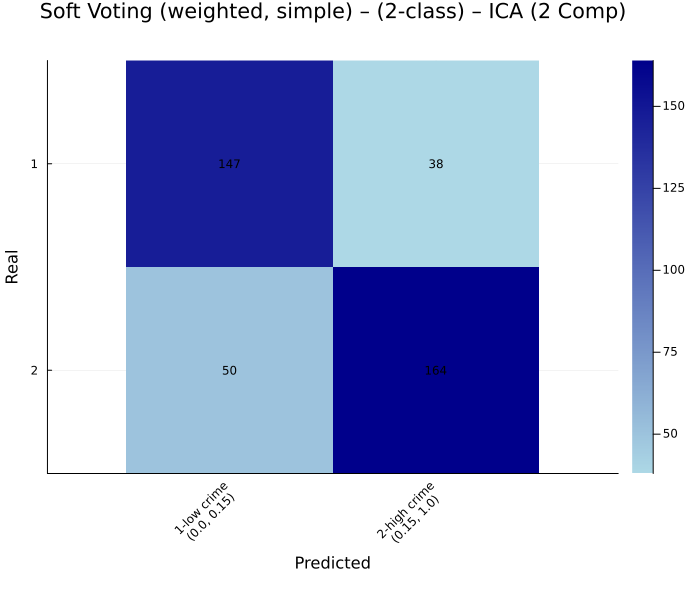

In [ ]:
simple_soft_weighted_results = run_voting_ensembles(
    simple_ensemble_specs,
    train_output_binned_2,
    test_output_binned_2;
    voting       = :soft,
    weights      = soft_weights,
    title_prefix = "2-class crime (simple)"
)

simple_soft_weighted_save_dir    = joinpath("ensembles", exp_name, "simple_soft_weighted_voting")
simple_soft_weighted_file_prefix = "simple_soft_weighted_voting_2class"

plotEnsembleConfusionsIndividual(
    simple_soft_weighted_results,
    "Soft Voting (weighted, simple) – ($exp_name)";
    class_labels = class_labels_2,
    save_dir     = simple_soft_weighted_save_dir,
    file_prefix  = simple_soft_weighted_file_prefix
)


STACKING ENSEMBLES – CLASSIFICATION

>>> [2-class crime] Representation: Raw Attributes
Weighted Metrics:
Accuracy: 0.8345864661654135
Error Rate: 0.16541353383458646
Sensitivity (Recall): 0.8486486486486486
Specificity: 0.822429906542056
Positive Predictive Value (Precision): 0.8051282051282052
Negative Predictive Value (Precision): 0.8627450980392157
F-score: 0.8263157894736842
Confusion Matrix:
[176 38; 28 157]

>>> [2-class crime] Representation: PCA (99% Var)
Weighted Metrics:
Accuracy: 0.8220551378446115
Error Rate: 0.17794486215538846
Sensitivity (Recall): 0.8594594594594595
Specificity: 0.7897196261682243
Positive Predictive Value (Precision): 0.7794117647058824
Negative Predictive Value (Precision): 0.8666666666666667
F-score: 0.8174807197943444
Confusion Matrix:
[169 45; 26 159]

>>> [2-class crime] Representation: ICA (2 Comp)
Weighted Metrics:
Accuracy: 0.7844611528822055
Error Rate: 0.21553884711779447
Sensitivity (Recall): 0.8054054054054054
Specificity: 0.76635514018691

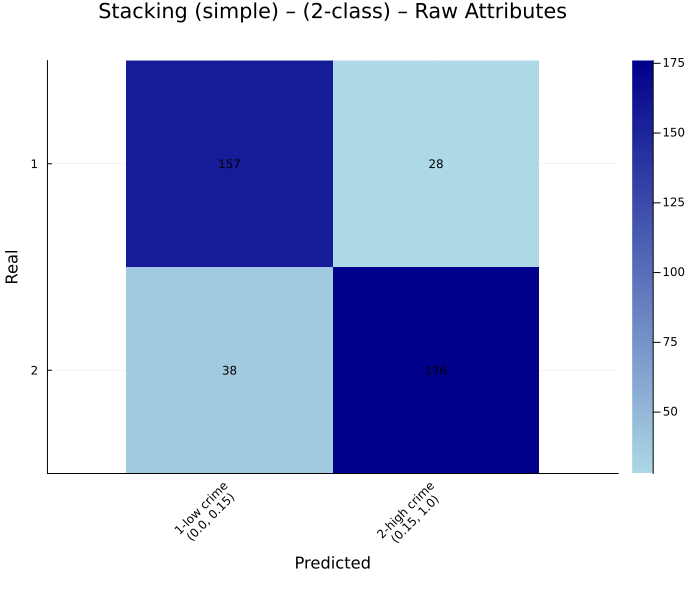

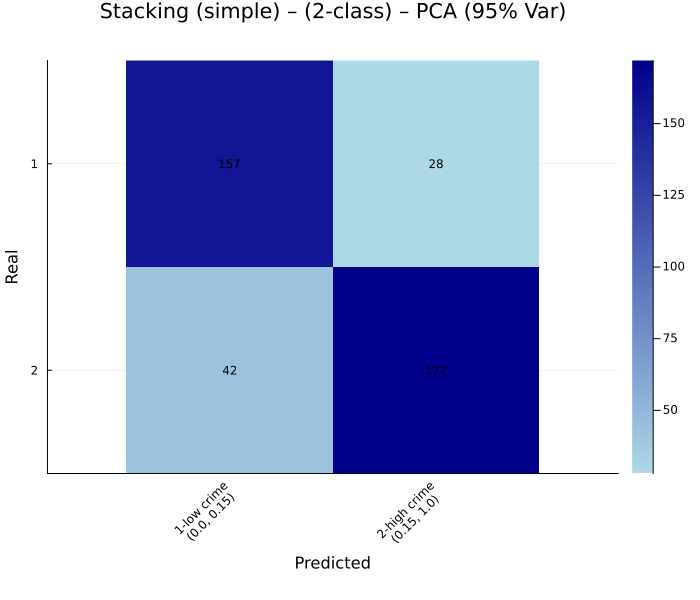

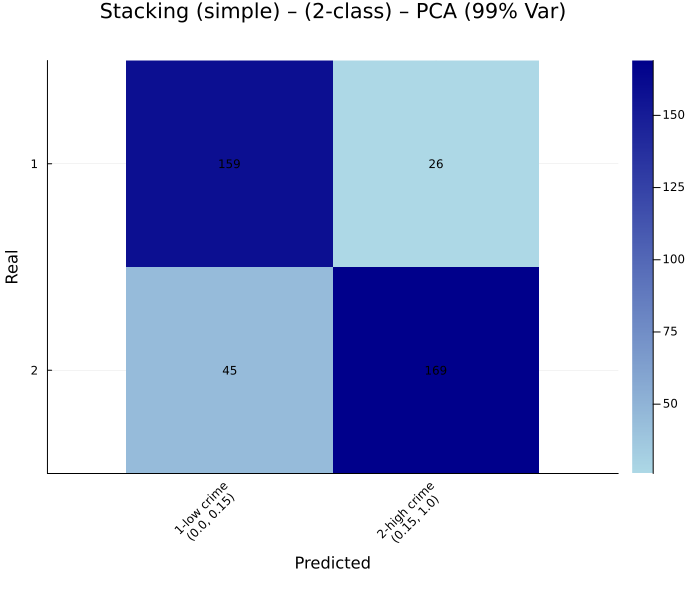

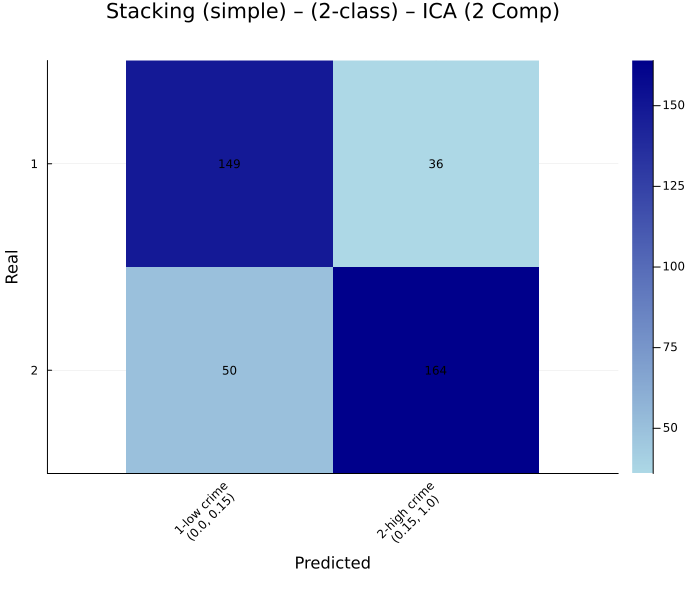

In [ ]:
simple_stacking_results = Ensembles.run_stacking_ensembles(
    simple_ensemble_specs,
    train_output_binned_2,
    test_output_binned_2;
    base_names   = (:ANN, :SVM, :DT, :KNN),
    title_prefix = "2-class crime"
)

simple_stacking_dir    = joinpath("ensembles", exp_name, "simple_stacking")
simple_stacking_prefix = "simple_stacking_2class"

plotEnsembleConfusionsIndividual(
    simple_stacking_results,
    "Stacking (simple) – ($exp_name)";
    class_labels = class_labels_2,
    save_dir     = simple_stacking_dir,
    file_prefix  = simple_stacking_prefix
)

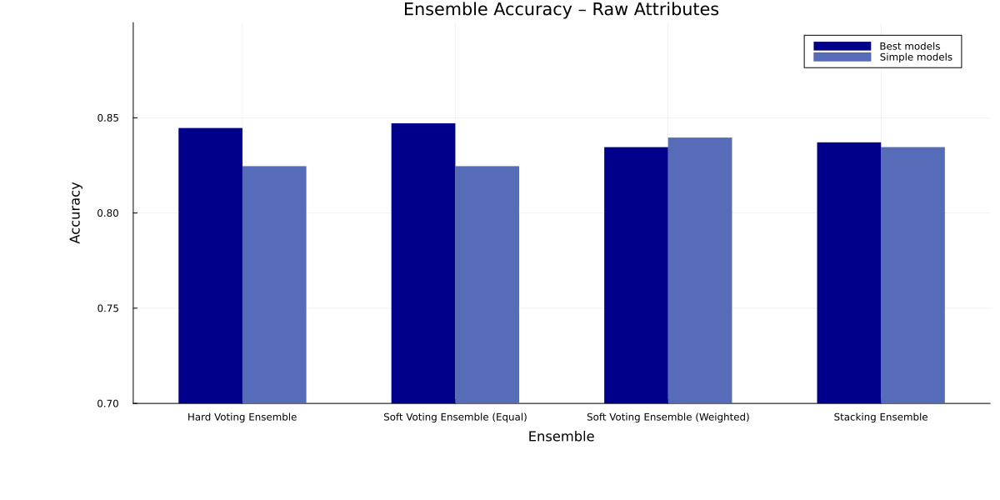

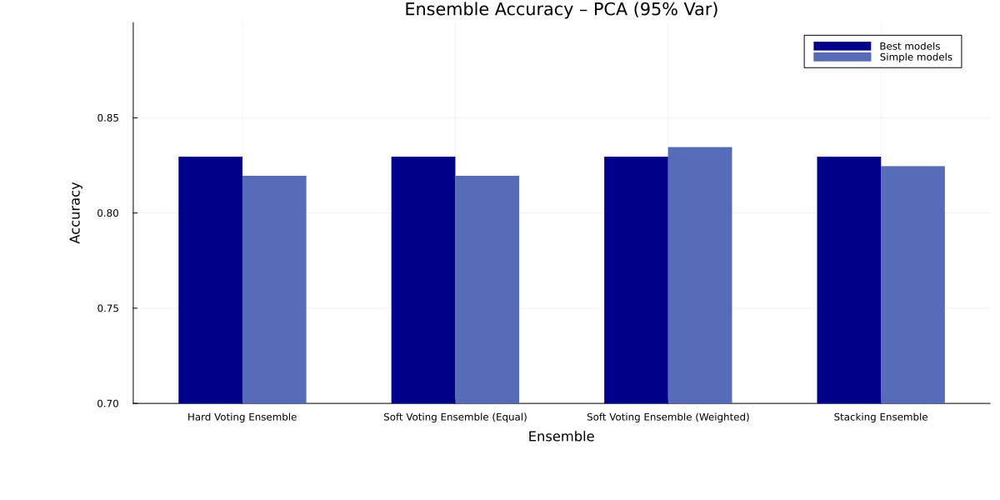

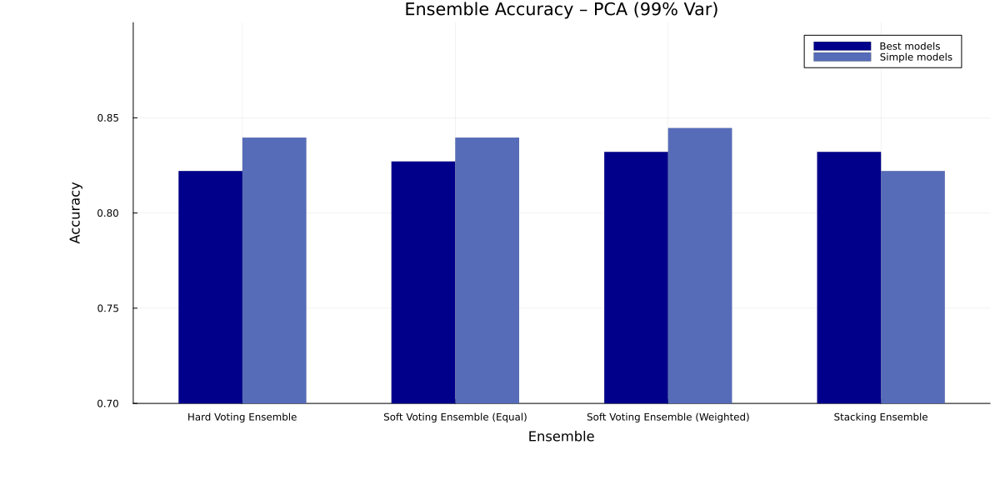

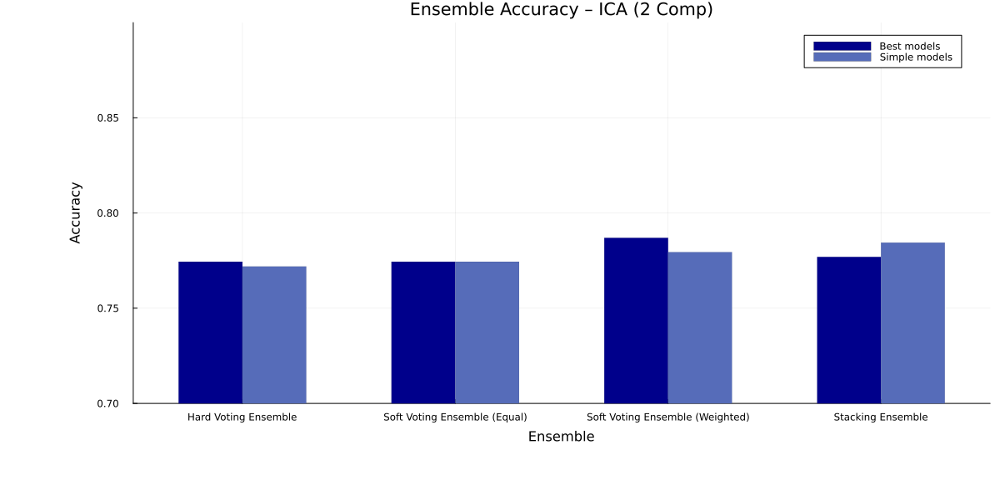

In [ ]:
# 3) Accuracy comparison: hard + soft + weighted + stacking
data_to_plot_ensembles = [
    (
        ds_name,
        [
            ("Hard Voting Ensemble",
                hard_voting_results[ds_name][1],
                hard_voting_results[ds_name][2]),
            ("Soft Voting Ensemble (Equal)",
                soft_equal_results[ds_name][1],
                soft_equal_results[ds_name][2]),
            ("Soft Voting Ensemble (Weighted)",
                soft_weighted_results[ds_name][1],
                soft_weighted_results[ds_name][2]),
            ("Stacking Ensemble",
                stacking_results[ds_name][1],
                stacking_results[ds_name][2])
        ]
    )
    for ds_name in ordered_datasets
]

data_to_plot_ensembles_simples = [
    (
        ds_name,
        [
            ("Hard Voting Ensemble",
                simple_hard_voting_results[ds_name][1],
                simple_hard_voting_results[ds_name][2]),
            ("Soft Voting Ensemble (Equal)",
                simple_soft_equal_results[ds_name][1],
                simple_soft_equal_results[ds_name][2]),
            ("Soft Voting Ensemble (Weighted)",
                simple_soft_weighted_results[ds_name][1],
                simple_soft_weighted_results[ds_name][2]),
            ("Stacking Ensemble",
                simple_stacking_results[ds_name][1],
                simple_stacking_results[ds_name][2])
        ]
    )
    for ds_name in ordered_datasets
]

plotEnsembleAccuracyBestVsSimple(
    data_to_plot_ensembles,
    data_to_plot_ensembles_simples;
    folder_name   = "ensembles/3-class/accuracy_best_vs_simple",
    base_filename = "accuracy_3class_best_vs_simple",
    size          = (1200, 600),
    ylims         = (0.7, 0.9)   # ajusta a ojo si hace falta
)



In [ ]:
println("\nREGRESSION ENSEMBLES – HARD (EQUAL WEIGHTS)")
println("===========================================")

reg_ensemble_results_hard = Ensembles.run_regression_ensembles(
    reg_ensemble_specs,
    y_train_reg,
    y_test_reg;
    weights  = nothing
)

reg_ensembles_table_hard = print_reg_ensemble_summary(
    reg_ensemble_results_hard,
    ordered_datasets;
    metric_fn = evaluate_regression,
    title     = "FINAL SUMMARY – Hard Regression Ensemble (Test RMSE)",
    col_label = "Hard Ensemble RMSE"
)



REGRESSION ENSEMBLES – HARD (EQUAL WEIGHTS)

VOTING ENSEMBLES – REGRESSION

>>> Regression ensemble on dataset: Raw Attributes
  RMSE = 0.1609
  R²   = 0.5156

>>> Regression ensemble on dataset: PCA (99% Var)
  RMSE = 0.1477
  R²   = 0.5917

>>> Regression ensemble on dataset: ICA (2 Comp)
  RMSE = 0.1761
  R²   = 0.4196

>>> Regression ensemble on dataset: PCA (95% Var)
  RMSE = 0.1618
  R²   = 0.5104


FINAL SUMMARY – Hard Regression Ensemble (Test RMSE)
┌────────────────┬────────────────────┐
│ Representation │ Hard Ensemble RMSE │
├────────────────┼────────────────────┤
│ Raw Attributes │             0.1609 │
│  PCA (95% Var) │             0.1618 │
│  PCA (99% Var) │             0.1477 │
│   ICA (2 Comp) │             0.1761 │
└────────────────┴────────────────────┘


Row,Representation,rmse_col_sym
,String,Float64
1,Raw Attributes,0.160919
2,PCA (95% Var),0.161788
3,PCA (99% Var),0.147741
4,ICA (2 Comp),0.176145


In [ ]:
println("\nREGRESSION ENSEMBLES – EQUAL WEIGHTS")
println("====================================")

reg_ensemble_results_equal = Ensembles.run_regression_ensembles(
    reg_ensemble_specs,
    y_train_reg,
    y_test_reg;
    weights  = nothing
)

reg_ensembles_table_equal = print_reg_ensemble_summary(
    reg_ensemble_results_equal,
    ordered_datasets;
    metric_fn = evaluate_regression,
    title     = "FINAL SUMMARY – Regression Ensemble (Equal Weights) – Test RMSE",
    col_label = "Equal Weights RMSE"
)


REGRESSION ENSEMBLES – EQUAL WEIGHTS

VOTING ENSEMBLES – REGRESSION

>>> Regression ensemble on dataset: Raw Attributes
  RMSE = 0.1545
  R²   = 0.5536

>>> Regression ensemble on dataset: PCA (99% Var)
  RMSE = 0.1611
  R²   = 0.5147

>>> Regression ensemble on dataset: ICA (2 Comp)
  RMSE = 0.184
  R²   = 0.3667

>>> Regression ensemble on dataset: PCA (95% Var)
  RMSE = 0.169
  R²   = 0.4657


FINAL SUMMARY – Regression Ensemble (Equal Weights) – Test RMSE
┌────────────────┬────────────────────┐
│ Representation │ Equal Weights RMSE │
├────────────────┼────────────────────┤
│ Raw Attributes │             0.1545 │
│  PCA (95% Var) │             0.1690 │
│  PCA (99% Var) │             0.1611 │
│   ICA (2 Comp) │             0.1840 │
└────────────────┴────────────────────┘


Row,Representation,rmse_col_sym
,String,Float64
1,Raw Attributes,0.15449
2,PCA (95% Var),0.169012
3,PCA (99% Var),0.16108
4,ICA (2 Comp),0.184005


In [ ]:
# ==========================================================
# 2) REGRESSION ENSEMBLE – WEIGHTED (RMSE-based weights)
# ==========================================================
# We use the inverse of the single-model RMSEs as weights,
# so better (lower RMSE) models get higher weight.
base_rmse = [rmse_ann, rmse_svm, rmse_dt, rmse_knn]     
inv_rmse  = 1.0 ./ base_rmse
reg_weights = inv_rmse ./ sum(inv_rmse)

4-element Vector{Float64}:
 0.2969705803914208
 0.12460737559620715
 0.26876510540202087
 0.3096569386103512

In [ ]:
# ==========================================================
# REGRESSION ENSEMBLES – WEIGHTED AVERAGE
# ==========================================================

println("\nREGRESSION ENSEMBLES – WEIGHTED")
println("================================")

reg_ensemble_results_weighted = Ensembles.run_regression_ensembles(
    reg_ensemble_specs,
    y_train_reg,
    y_test_reg;
    weights = reg_weights
)

reg_ensembles_table_weighted = print_reg_ensemble_summary(
    reg_ensemble_results_weighted,
    ordered_datasets;
    metric_fn = evaluate_regression,
    title     = "FINAL SUMMARY – Regression Ensemble (Weighted) – Test RMSE",
    col_label = "Weighted RMSE"
)



REGRESSION ENSEMBLES – WEIGHTED

VOTING ENSEMBLES – REGRESSION

>>> Regression ensemble on dataset: Raw Attributes
  RMSE = 0.1399
  R²   = 0.6337

>>> Regression ensemble on dataset: PCA (99% Var)
  RMSE = 0.1433
  R²   = 0.616

>>> Regression ensemble on dataset: ICA (2 Comp)
  RMSE = 0.172
  R²   = 0.4469

>>> Regression ensemble on dataset: PCA (95% Var)
  RMSE = 0.1441
  R²   = 0.6116


FINAL SUMMARY – Regression Ensemble (Weighted) – Test RMSE
┌────────────────┬───────────────┐
│ Representation │ Weighted RMSE │
├────────────────┼───────────────┤
│ Raw Attributes │        0.1399 │
│  PCA (95% Var) │        0.1441 │
│  PCA (99% Var) │        0.1433 │
│   ICA (2 Comp) │        0.1720 │
└────────────────┴───────────────┘


Row,Representation,rmse_col_sym
,String,Float64
1,Raw Attributes,0.139944
2,PCA (95% Var),0.144106
3,PCA (99% Var),0.143274
4,ICA (2 Comp),0.171964


In [ ]:
reg_stacking_results = Ensembles.run_regression_stacking_ensembles(
    reg_ensemble_specs,         
    y_train_reg,
    y_test_reg;
    base_names     = (:ANN, :SVM, :DT, :KNN),
    meta_regressor = NeuralNetworkRegressor(
        builder=MLJFlux.MLP((8,8), Flux.relu), 
        epochs=8, 
        batch_size=32,
        optimiser=Optimisers.Adam(0.01) 
    ),
    nfolds         = 5,
    rng_seed       = 123,
    title_prefix   = "Stacking Regression (full)"
)

reg_ensembles_table_stack = print_reg_ensemble_summary(
    reg_stacking_results,
    ordered_datasets;
    metric_fn = evaluate_regression,
    title     = "FINAL SUMMARY – Regression Stacking Ensemble (Full Models, Test RMSE)",
    col_label = "Stacking RMSE (full)"
)


REGRESSION ENSEMBLES – STACKING

>>> Building stacking regression ensemble for: Raw Attributes
Stacking Regression (full) – Raw Attributes: RMSE = 0.1382

>>> Building stacking regression ensemble for: PCA (99% Var)
Stacking Regression (full) – PCA (99% Var): RMSE = 0.1340

>>> Building stacking regression ensemble for: ICA (2 Comp)
Stacking Regression (full) – ICA (2 Comp): RMSE = 0.1655

>>> Building stacking regression ensemble for: PCA (95% Var)
Stacking Regression (full) – PCA (95% Var): RMSE = 0.1312

FINAL SUMMARY – Regression Stacking Ensemble (Full Models, Test RMSE)
┌────────────────┬──────────────────────┐
│ Representation │ Stacking RMSE (full) │
├────────────────┼──────────────────────┤
│ Raw Attributes │               0.1382 │
│  PCA (95% Var) │               0.1312 │
│  PCA (99% Var) │               0.1340 │
│   ICA (2 Comp) │               0.1655 │
└────────────────┴──────────────────────┘


Row,Representation,rmse_col_sym
,String,Float64
1,Raw Attributes,0.138226
2,PCA (95% Var),0.131163
3,PCA (99% Var),0.133981
4,ICA (2 Comp),0.16551


In [ ]:
println("\nSIMPLE REGRESSION ENSEMBLES – HARD (EQUAL WEIGHTS)")
println("====================================================")

simple_reg_ensemble_results_hard = Ensembles.run_regression_ensembles(
    simple_reg_ensemble_specs,
    y_train_reg,
    y_test_reg;
    weights = nothing
)

simple_reg_ensembles_table_hard = print_reg_ensemble_summary(
    simple_reg_ensemble_results_hard,
    ordered_datasets;
    metric_fn = evaluate_regression,
    title     = "FINAL SUMMARY – Simple Hard Regression Ensemble (Test RMSE)",
    col_label = "Simple Hard Ensemble RMSE"
)


SIMPLE REGRESSION ENSEMBLES – HARD (EQUAL WEIGHTS)

VOTING ENSEMBLES – REGRESSION

>>> Regression ensemble on dataset: Raw Attributes
  RMSE = 0.1548
  R²   = 0.5518

>>> Regression ensemble on dataset: PCA (99% Var)
  RMSE = 0.1605
  R²   = 0.5181

>>> Regression ensemble on dataset: ICA (2 Comp)
  RMSE = 0.1941
  R²   = 0.2953

>>> Regression ensemble on dataset: PCA (95% Var)
  RMSE = 0.1607
  R²   = 0.5169


FINAL SUMMARY – Simple Hard Regression Ensemble (Test RMSE)
┌────────────────┬───────────────────────────┐
│ Representation │ Simple Hard Ensemble RMSE │
├────────────────┼───────────────────────────┤
│ Raw Attributes │                    0.1548 │
│  PCA (95% Var) │                    0.1607 │
│  PCA (99% Var) │                    0.1605 │
│   ICA (2 Comp) │                    0.1941 │
└────────────────┴───────────────────────────┘


Row,Representation,rmse_col_sym
,String,Float64
1,Raw Attributes,0.1548
2,PCA (95% Var),0.160704
3,PCA (99% Var),0.160512
4,ICA (2 Comp),0.194093


In [ ]:
println("\nSIMPLE REGRESSION ENSEMBLES – EQUAL WEIGHTS")
println("===========================================")

simple_reg_ensemble_results_equal = Ensembles.run_regression_ensembles(
    simple_reg_ensemble_specs,
    y_train_reg,
    y_test_reg;
    weights = nothing
)

simple_reg_ensembles_table_equal = print_reg_ensemble_summary(
    simple_reg_ensemble_results_equal,
    ordered_datasets;
    metric_fn = evaluate_regression,
    title     = "FINAL SUMMARY – Simple Regression Ensemble (Equal Weights) – Test RMSE",
    col_label = "Simple Equal Weights RMSE"
)


SIMPLE REGRESSION ENSEMBLES – EQUAL WEIGHTS

VOTING ENSEMBLES – REGRESSION

>>> Regression ensemble on dataset: Raw Attributes
  RMSE = 0.1534
  R²   = 0.5597

>>> Regression ensemble on dataset: PCA (99% Var)
  RMSE = 0.1555
  R²   = 0.5476

>>> Regression ensemble on dataset: ICA (2 Comp)
  RMSE = 0.1778
  R²   = 0.4084

>>> Regression ensemble on dataset: PCA (95% Var)
  RMSE = 0.1575
  R²   = 0.5362


FINAL SUMMARY – Simple Regression Ensemble (Equal Weights) – Test RMSE
┌────────────────┬───────────────────────────┐
│ Representation │ Simple Equal Weights RMSE │
├────────────────┼───────────────────────────┤
│ Raw Attributes │                    0.1534 │
│  PCA (95% Var) │                    0.1575 │
│  PCA (99% Var) │                    0.1555 │
│   ICA (2 Comp) │                    0.1778 │
└────────────────┴───────────────────────────┘


Row,Representation,rmse_col_sym
,String,Float64
1,Raw Attributes,0.153421
2,PCA (95% Var),0.157459
3,PCA (99% Var),0.15552
4,ICA (2 Comp),0.177846


In [ ]:
simple_reg_ensemble_results_weighted = Ensembles.run_regression_ensembles(
    simple_reg_ensemble_specs,
    y_train_reg,
    y_test_reg;
    weights = reg_weights        
)

simple_reg_ensembles_table_weighted = print_reg_ensemble_summary(
    simple_reg_ensemble_results_weighted,
    ordered_datasets;
    metric_fn = evaluate_regression,
    title     = "FINAL SUMMARY – Simple Regression Ensemble (Weighted) – Test RMSE",
    col_label = "Simple Weighted RMSE"
)


VOTING ENSEMBLES – REGRESSION

>>> Regression ensemble on dataset: Raw Attributes
  RMSE = 0.1354
  R²   = 0.657

>>> Regression ensemble on dataset: PCA (99% Var)
  RMSE = 0.1445
  R²   = 0.6095

>>> Regression ensemble on dataset: ICA (2 Comp)
  RMSE = 0.1765
  R²   = 0.4175

>>> Regression ensemble on dataset: PCA (95% Var)
  RMSE = 0.1428
  R²   = 0.6184


FINAL SUMMARY – Simple Regression Ensemble (Weighted) – Test RMSE
┌────────────────┬──────────────────────┐
│ Representation │ Simple Weighted RMSE │
├────────────────┼──────────────────────┤
│ Raw Attributes │               0.1354 │
│  PCA (95% Var) │               0.1428 │
│  PCA (99% Var) │               0.1445 │
│   ICA (2 Comp) │               0.1765 │
└────────────────┴──────────────────────┘


Row,Representation,rmse_col_sym
,String,Float64
1,Raw Attributes,0.135423
2,PCA (95% Var),0.142824
3,PCA (99% Var),0.144482
4,ICA (2 Comp),0.176468


In [ ]:
println("\nSIMPLE REGRESSION ENSEMBLES – STACKING")
println("======================================")

simple_reg_stacking_results = Ensembles.run_regression_stacking_ensembles(
    simple_reg_ensemble_specs,
    y_train_reg,
    y_test_reg;
    base_names     = (:ANN, :SVM, :DT, :KNN),
    meta_regressor = NeuralNetworkRegressor(),
    nfolds       = 5,
    rng_seed     = 123,
    title_prefix = "Stacking Regression (simple)"
)

simple_reg_ensembles_table_stack = print_reg_ensemble_summary(
    simple_reg_stacking_results,
    ordered_datasets;
    metric_fn = evaluate_regression,
    title     = "FINAL SUMMARY – Simple Regression Stacking Ensemble (Test RMSE)",
    col_label = "Simple Stacking RMSE"
)


SIMPLE REGRESSION ENSEMBLES – STACKING

REGRESSION ENSEMBLES – STACKING

>>> Building stacking regression ensemble for: Raw Attributes
Stacking Regression (simple) – Raw Attributes: RMSE = 0.1307

>>> Building stacking regression ensemble for: PCA (99% Var)
Stacking Regression (simple) – PCA (99% Var): RMSE = 0.1485

>>> Building stacking regression ensemble for: ICA (2 Comp)
Stacking Regression (simple) – ICA (2 Comp): RMSE = 0.1688

>>> Building stacking regression ensemble for: PCA (95% Var)
Stacking Regression (simple) – PCA (95% Var): RMSE = 0.1340

FINAL SUMMARY – Simple Regression Stacking Ensemble (Test RMSE)
┌────────────────┬──────────────────────┐
│ Representation │ Simple Stacking RMSE │
├────────────────┼──────────────────────┤
│ Raw Attributes │               0.1307 │
│  PCA (95% Var) │               0.1340 │
│  PCA (99% Var) │               0.1485 │
│   ICA (2 Comp) │               0.1688 │
└────────────────┴──────────────────────┘


Row,Representation,rmse_col_sym
,String,Float64
1,Raw Attributes,0.130674
2,PCA (95% Var),0.133973
3,PCA (99% Var),0.148514
4,ICA (2 Comp),0.168754


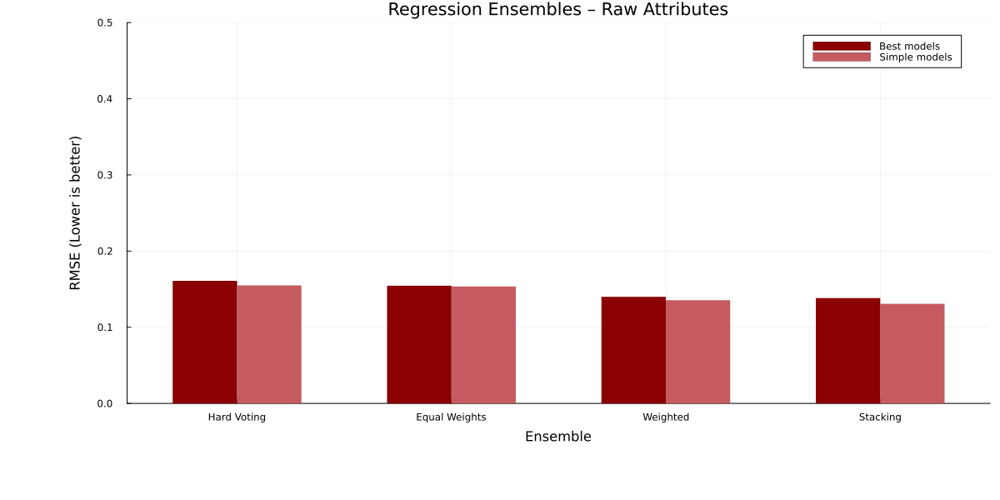

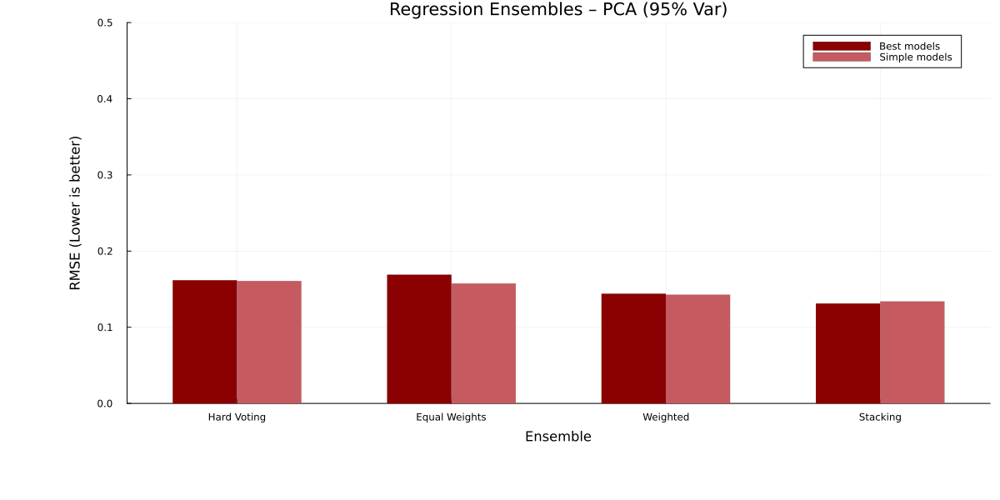

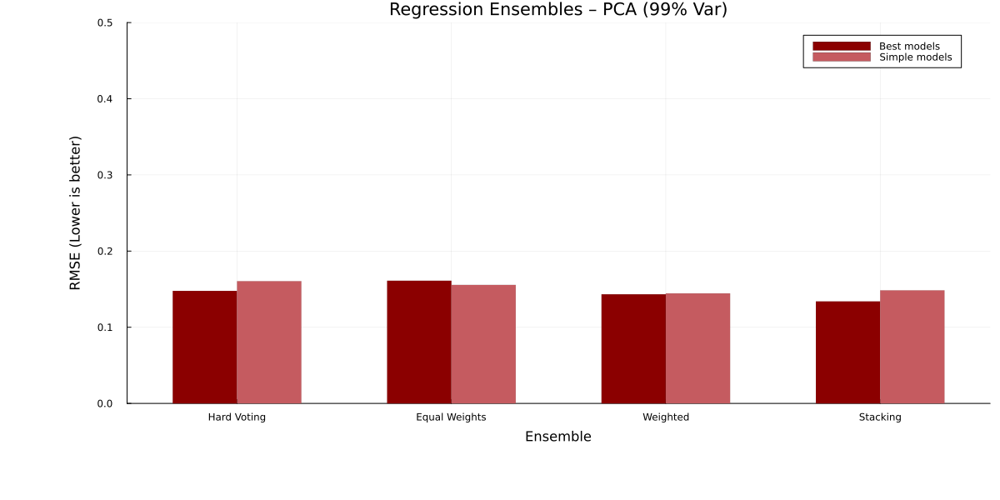

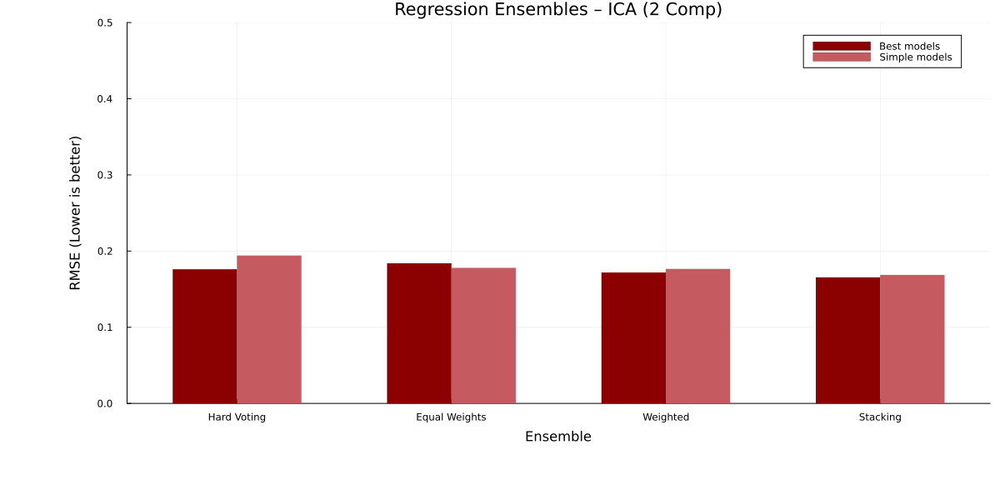

In [ ]:
summary_hard     = Ensembles.summarize_regression_ensembles(reg_ensemble_results_hard,     ordered_datasets; metric_fn=evaluate_regression)
summary_equal    = Ensembles.summarize_regression_ensembles(reg_ensemble_results_equal,    ordered_datasets; metric_fn=evaluate_regression)
summary_weighted = Ensembles.summarize_regression_ensembles(reg_ensemble_results_weighted, ordered_datasets; metric_fn=evaluate_regression)
summary_stacking = Ensembles.summarize_regression_ensembles(reg_stacking_results,          ordered_datasets; metric_fn=evaluate_regression)

simple_summary_hard = Ensembles.summarize_regression_ensembles(simple_reg_ensemble_results_hard,            ordered_datasets; metric_fn = evaluate_regression)
simple_summary_equal = Ensembles.summarize_regression_ensembles(simple_reg_ensemble_results_equal,          ordered_datasets; metric_fn = evaluate_regression)
simple_summary_weighted = Ensembles.summarize_regression_ensembles(simple_reg_ensemble_results_weighted,    ordered_datasets; metric_fn = evaluate_regression)
simple_summary_stacking = Ensembles.summarize_regression_ensembles(simple_reg_stacking_results,             ordered_datasets; metric_fn = evaluate_regression)


plot_regression_ensemble_best_vs_simple(
    summary_hard,
    summary_equal,
    summary_weighted,
    summary_stacking,
    simple_summary_hard,
    simple_summary_equal,
    simple_summary_weighted,
    simple_summary_stacking,
    ordered_datasets;
    ensemble_labels = ["Hard Voting", "Equal Weights", "Weighted", "Stacking"],
    folder_name     = joinpath("ensembles", "regression", "best_vs_simple"),
    base_filename   = "regression_best_vs_simple",
    size            = (1200, 600),
    ylims           = (0, 0.5)   # o por ejemplo (0.4, 0.9)
)

